# Fase 4 — Diagnostica Modello AE

> **Obiettivo**: capire **perché** l'autoencoder addestrato (`reports/checkpoints/ae_baseline.pth`) non separa normal da anomalo, usando 7 test (FASE 0 + A–G); ciascuno indaga un possibile punto di fallimento: non impara, overfitta, discriminazione per canale, drift, baseline grezza, capacità, sintesi.

> **Principi guida**
> - **Read-only**: niente scrittura su `src/`, `config/`, `data/processed/` o checkpoint; gli errori si ricalcolano in forward pass.
> - **Output isolati**: solo artefatti in `reports/diagnostics/model_diagnosis/` (CSV, PNG, JSON).
> - **Seed fissato**: `set_seed(42)` da `src/utils/seed.py`, dichiarato in ogni cella.
> - **Prevalenza** sempre mostrata accanto alle AUC (livello caso per la PR-AUC).
> - **Test set**: usato solo per la conferma finale (appendice G), mai per calibrare soglie.
> - **Conclusione**: ogni sezione chiude con *Cosa osservo / Cosa concludo / Cosa NON posso concludere*.

> **Forma di ogni sezione**: breve intro (cosa consiste / perché / come interpretare) → cella di codice opzionale → conclusione metodologica. Nessuna conclusione riporta i risultati attuali: il testo è generale così da valere per qualsiasi esecuzione.

In [2]:
"""FASE 0 — Setup globale: seed, device, config, paths.

Esegui questa cella PRIMA di tutte le altre.
"""
import os
import sys
from pathlib import Path

import numpy as np
import torch

# Path resolution — works from project root or notebooks/
CWD = os.getcwd()
if "notebooks" in CWD:
    PROJECT_ROOT = os.path.dirname(CWD)
else:
    PROJECT_ROOT = CWD
os.chdir(PROJECT_ROOT)
sys.path.insert(0, PROJECT_ROOT)

from src.utils.seed import set_seed
from src.utils.config import load_config, get_param

# --- Global constants ---
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- Load config ---
config = load_config()  # carica config.yaml + params_validated_ae.yaml (merge)

# --- Paths ---
processed_dir = Path(PROJECT_ROOT) / "data" / "processed"
DIAG_DIR = Path(PROJECT_ROOT) / "reports" / "diagnostics" / "model_diagnosis"
DIAG_DIR.mkdir(parents=True, exist_ok=True)

# --- Checkpoint file ---
CHECKPOINT_PATH = Path(PROJECT_ROOT) / "reports" / "checkpoints" / "ae_baseline.pth"

print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print(f"DEVICE: {DEVICE}")
print(f"SEED: {SEED}")
print(f"Config loaded: {list(config.keys())}")
print(f"processed_dir: {processed_dir}")
print(f"DIAG_DIR: {DIAG_DIR}")
print(f"CHECKPOINT_PATH: {CHECKPOINT_PATH}")
print(f"Checkpoint exists: {CHECKPOINT_PATH.exists()}")

PROJECT_ROOT: c:\Users\ungol\OneDrive\Desktop\Ing-Inf-PoliTo\secondo anno\secondo semestre\Machine Learning in Application\project\AM01\AM01-Detection-of-Anomalous-Behaviour-in-Industrial-Robot
DEVICE: cpu
SEED: 42
Config loaded: ['project', 'environment', 'paths', 'logging', 'model', 'training', 'data']
processed_dir: c:\Users\ungol\OneDrive\Desktop\Ing-Inf-PoliTo\secondo anno\secondo semestre\Machine Learning in Application\project\AM01\AM01-Detection-of-Anomalous-Behaviour-in-Industrial-Robot\data\processed
DIAG_DIR: c:\Users\ungol\OneDrive\Desktop\Ing-Inf-PoliTo\secondo anno\secondo semestre\Machine Learning in Application\project\AM01\AM01-Detection-of-Anomalous-Behaviour-in-Industrial-Robot\reports\diagnostics\model_diagnosis
CHECKPOINT_PATH: c:\Users\ungol\OneDrive\Desktop\Ing-Inf-PoliTo\secondo anno\secondo semestre\Machine Learning in Application\project\AM01\AM01-Detection-of-Anomalous-Behaviour-in-Industrial-Robot\reports\checkpoints\ae_baseline.pth
Checkpoint exists: True


In [4]:
"""FASE 0 — Inventario artefatti nel checkpoint.

Carica reports/checkpoints/ae_baseline.pth (read-only) e produce una tabella
che dice cosa è presente/assente e quale sezione è eseguibile.

Non salva nulla sul checkpoint né modifica nessun file sorgente.
"""
set_seed(SEED)

# --- Load checkpoint (read-only) ---
ckpt = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)

# --- Inspect keys ---
print("Chiavi nel checkpoint:")
for k in ckpt:
    v = ckpt[k]
    if k == "model_state_dict":
        n_params = sum(p.numel() for p in v.values())
        print(f"  {k}: {len(v)} parametri, {n_params} elementi totali")
    elif k == "history":
        train_l = v.get("train_loss", [])
        val_l = v.get("val_loss", [])
        be = v.get("best_epoch", "N/A")
        print(f"  history: train_loss={len(train_l)} voci, val_loss={len(val_l)} voci, best_epoch={be}")
    else:
        print(f"  {k}: {v}")

# --- Artifact status table ---
artifacts = {
    "model_state_dict": ckpt.get("model_state_dict") is not None,
    "input_dim": "input_dim" in ckpt,
    "window_size": "window_size" in ckpt,
    "latent_dim": "latent_dim" in ckpt,
    "conv_channels": "conv_channels" in ckpt,  # ATTESI: assente — usiamo default (64,32,16)
    "history (train_loss)": len(ckpt.get("history", {}).get("train_loss", [])) > 0,
    "history (val_loss)": len(ckpt.get("history", {}).get("val_loss", [])) > 0,
    "best_epoch": "best_epoch" in ckpt.get("history", {}),
    "seed": "seed" in ckpt,  # ATTESI: assente
    "config_yaml": "config" in ckpt or "config_yaml" in ckpt,  # ATTESI: assente
    "action_feature_indices": "action_feature_indices" in ckpt,
}

# --- Section executability ---
history_present = (
    artifacts["history (train_loss)"] and
    artifacts["history (val_loss)"] and
    artifacts["best_epoch"] and
    len(ckpt.get("history", {}).get("val_loss", [])) > 0
)

ARTIFACT_STATUS = {
    "A": True,  # MAE_zero vs MAE_AE — sempre eseguibile con modello
    "B": history_present,  # curve training — solo se history presente
    "C": True,  # errore per canale — sempre eseguibile
    "D": True,  # distribuzioni/tempo — sempre eseguibile
    "E": True,  # baseline senza rete — sempre eseguibile
    "F": True,  # overfit test — dentro notebook
    "G": True,  # sintesi — sempre eseguibile
}

print("\n" + "=" * 60)
print("ARTIFACT STATUS TABLE")
print("=" * 60)
print(f"{'Artefatto':<30} {'Presente':<12} {'Conseguenza':<30}")
print("-" * 60)
for art, present in artifacts.items():
    status = "✅ SÌ" if present else "❌ NO"
    if present:
        conseq = "OK"
    elif art == "conv_channels":
        conseq = "Usa default (64,32,16)"
    elif art == "seed":
        conseq = "FASE 0 → segnala"
    elif art in ("config_yaml",):
        conseq = "FASE 0 → segnala"
    elif "history" in art or "best_epoch" in art:
        conseq = f"Sezione B -> {'esegui' if history_present else 'in SOSPESO'}"
    elif art == "action_feature_indices":
        conseq = "Usa default discovery"
    else:
        conseq = "in SOSPESO"
    print(f"{art:<30} {status:<12} {conseq:<30}")

print("\n" + "=" * 60)
print("SEZIONI ESEGUIBILI")
print("=" * 60)
for sec in ["A", "B", "C", "D", "E", "F", "G"]:
    status = "✅ ESEGUI" if ARTIFACT_STATUS[sec] else "⏸ IN SOSPESO"
    print(f"  Sezione {sec}: {status}")

# Stampa valori chiave del checkpoint
W_ckpt = ckpt.get("window_size", "UNKNOWN")
input_dim_ckpt = ckpt.get("input_dim", "UNKNOWN")
latent_dim_ckpt = ckpt.get("latent_dim", "UNKNOWN")
print(f"\nDati checkpoint: W={W_ckpt}, input_dim={input_dim_ckpt}, latent_dim={latent_dim_ckpt}")

# Verifica coerenza con config
W_config = int(get_param(config, "model.window_size", 16))
print(f"Config params_validated_ae.yaml: window_size={W_config}")
if W_ckpt != W_config and W_ckpt != "UNKNOWN":
    print(f"⚠️  MISMATCH: checkpoint W={W_ckpt} ≠ config W={W_config}")

Chiavi nel checkpoint:
  model_state_dict: 16 parametri, 76173 elementi totali
  history: train_loss=2 voci, val_loss=2 voci, best_epoch=2
  input_dim: 109
  window_size: 16
  latent_dim: 16

ARTIFACT STATUS TABLE
Artefatto                      Presente     Conseguenza                   
------------------------------------------------------------
model_state_dict               ✅ SÌ         OK                            
input_dim                      ✅ SÌ         OK                            
window_size                    ✅ SÌ         OK                            
latent_dim                     ✅ SÌ         OK                            
conv_channels                  ❌ NO         Usa default (64,32,16)        
history (train_loss)           ✅ SÌ         OK                            
history (val_loss)             ✅ SÌ         OK                            
best_epoch                     ✅ SÌ         OK                            
seed                           ❌ NO         FASE 0

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — FASE 0

**Cosa osservo**: il checkpoint contiene `model_state_dict`, `input_dim`, `window_size`, `latent_dim` e, se presente, `history` (train/val loss). Manca `seed` e la configurazione YAML completa.

**Cosa concludo**: le sezioni che usano solo i pesi (A, C, D, E, F, G) sono eseguibili — gli errori si ricalcolano con un forward pass. La sezione B (curve di training) è eseguibile **solo se `history` è presente e non vuoto**. La sezione F (overfit test) è sempre eseguibile inside-notebook, in un'eccezione all'obbligo read-only.

**Cosa NON posso concludere**: non so **quale seed** ha prodotto il checkpoint. Non so se `window_size` nel checkpoint è coerente con `params_validated_ae.yaml`. Non posso generalizzare ad altri seed né a configurazioni non registrate nel checkpoint stesso.

In [5]:
"""Istantzia il modello caricando i pesi dal checkpoint + build loader.

Usa W, input_dim, latent_dim LETTI DAL CHECKPOINT (non da params.yaml).
conv_channels non è nel .pth → default (64, 32, 16) come in autoencoder.py.
"""
set_seed(SEED)

# --- Read model config from checkpoint (not from params.yaml) ---
W = ckpt["window_size"]
input_dim = ckpt.get("input_dim", 82)
latent_dim = ckpt.get("latent_dim", 16)

# --- Action feature indices for anomaly score exclusion ---
# Priority: 1) checkpoint, 2) discovery from data
action_feature_indices = ckpt.get("action_feature_indices")
print(f"Modello istanziazione: W={W}, input_dim={input_dim}, latent_dim={latent_dim}, conv_channels=(64,32,16)")
if action_feature_indices is not None:
    print(f"  Action feature indices from checkpoint: {action_feature_indices}")

# --- Instantiate model with checkpoint params ---
# NOTA: SequenceAutoencoder usa conv_channels=(64,32,16) come default in autoencoder.py
# IMPORTANTE: passare action_feature_indices per escludere le action features dal calcolo dell'anomaly score
from src.models.autoencoder import SequenceAutoencoder
model = SequenceAutoencoder(
    input_dim=input_dim,
    window_size=W,
    latent_dim=latent_dim,
    action_feature_indices=action_feature_indices
)
model.load_state_dict(ckpt["model_state_dict"])
model.to(DEVICE)
model.eval()
print(f"Modello caricato: {sum(p.numel() for p in model.parameters())} parametri totali")

# --- Load processed data ---
train_data = np.load(processed_dir / "train.npy")
val_normal_data = np.load(processed_dir / "val_normal.npy")
val_anomaly_data = np.load(processed_dir / "val_anomaly.npy")
test_normal_data = np.load(processed_dir / "test_normal.npy")
test_anomaly_data = np.load(processed_dir / "test_anomaly.npy")
selected_columns = np.load(processed_dir / "selected_columns.npy", allow_pickle=True)

print(f"\nData shapes: train={train_data.shape}, val_normal={val_normal_data.shape}, "
      f"val_anomaly={val_anomaly_data.shape}, test_normal={test_normal_data.shape}, "
      f"test_anomaly={test_anomaly_data.shape}")
print(f"Selected columns: {selected_columns.shape[0]} features")

# --- Build single-sample loaders (shuffle=False per regole leakage) ---
# NOTA: batch_size grande per velocità forward
from src.data.dataset import build_loader
BATCH_SIZE = 512

train_loader = build_loader(train_data, window_size=W, batch_size=BATCH_SIZE, label=0, shuffle=False, num_workers=0)
val_normal_loader = build_loader(val_normal_data, window_size=W, batch_size=BATCH_SIZE, label=0, num_workers=0)
val_anomaly_loader = build_loader(val_anomaly_data, window_size=W, batch_size=BATCH_SIZE, label=1, num_workers=0)
test_normal_loader = build_loader(test_normal_data, window_size=W, batch_size=BATCH_SIZE, label=0, num_workers=0)
test_anomaly_loader = build_loader(test_anomaly_data, window_size=W, batch_size=BATCH_SIZE, label=1, num_workers=0)

print(f"\nNumero finestre:")
print(f"  train:         {len(train_loader.dataset)}")
print(f"  val_normal:    {len(val_normal_loader.dataset)}")
print(f"  val_anomaly:   {len(val_anomaly_loader.dataset)}")
print(f"  test_normal:   {len(test_normal_loader.dataset)}")
print(f"  test_anomaly:  {len(test_anomaly_loader.dataset)}")

# Validation prevalence
n_val_normal = len(val_normal_loader.dataset)
n_val_anomaly = len(val_anomaly_loader.dataset)
val_prevalence = n_val_anomaly / (n_val_normal + n_val_anomaly)
print(f"\nPrevalenza val: {val_prevalence:.4f} ({n_val_anomaly}/{n_val_normal+n_val_anomaly})")

# Test prevalence
n_test_normal = len(test_normal_loader.dataset)
n_test_anomaly = len(test_anomaly_loader.dataset)
test_prevalence = n_test_anomaly / (n_test_normal + n_test_anomaly)
print(f"Prevalenza test: {test_prevalence:.4f} ({n_test_anomaly}/{n_test_normal+n_test_anomaly})")

print("\n✅ Modello + loader pronti. Usa DEVICE e compute_errors_on_loader per tutte le sezioni successive.")
print(f"   Scoring: Classic MAE (no standardization)")

# ============================================================
# SETUP AGGIUNTIVO PER NUOVE ANALISI (1-5)
# Variabili necessarie: tensori raw validation, predizioni, scaler, action IDs
# ============================================================
set_seed(SEED)

# --- Load scaler per inverse_transform (Analisi 3) ---
import joblib
scaler = joblib.load(processed_dir / "scaler.pkl")
print(f"Scaler caricato: {scaler.n_features_in_} feature numeriche")

# --- Estrai tutti i tensori finestra dai loader validation ---
def extract_all_windows(loader):
    """Estrae tutti i tensori da un loader come singolo tensore (N, W, D)."""
    windows = []
    for batch in loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        windows.append(x)
    return torch.cat(windows, dim=0)

X_val_norm = extract_all_windows(val_normal_loader)      # (N_val_norm, W, D)
X_val_anom = extract_all_windows(val_anomaly_loader)     # (N_val_anom, W, D)
print(f"X_val_norm: {X_val_norm.shape}, X_val_anom: {X_val_anom.shape}")

# --- Predizioni modello su validation (no grad) ---
with torch.no_grad():
    X_val_norm_pred = model(X_val_norm.to(DEVICE)).cpu()
    X_val_anom_pred = model(X_val_anom.to(DEVICE)).cpu()
print(f"Predizioni calcolate.")

# --- MAE per finestra (usato da Analisi 2, 3, 5) ---
X_val_norm_np = X_val_norm.numpy()
X_val_norm_pred_np = X_val_norm_pred.numpy()
X_val_anom_np = X_val_anom.numpy()
X_val_anom_pred_np = X_val_anom_pred.numpy()

mae_norm_per_window = np.mean(np.abs(X_val_norm_np - X_val_norm_pred_np), axis=(1, 2))
mae_anom_per_window = np.mean(np.abs(X_val_anom_np - X_val_anom_pred_np), axis=(1, 2))
print(f"MAE per finestra calcolato: norm={mae_norm_per_window.shape}, anom={mae_anom_per_window.shape}")

# --- Action IDs per finestra (per Analisi 2) ---
# Le action features sono one-hot negli ultimi 32 canali
action_feature_start = input_dim - 32  # 109 - 32 = 77
def extract_action_ids(loader):
    """Estrae l'ID azione (0-31) per ogni finestra dal canale one-hot."""
    action_ids = []
    for batch in loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        # x: (B, W, D) - action one-hot è costante nella finestra, prendi t=0
        action_onehot = x[:, 0, action_feature_start:]  # (B, 32)
        action_id = action_onehot.argmax(dim=1).numpy()  # (B,)
        action_ids.append(action_id)
    return np.concatenate(action_ids)

action_val_norm = extract_action_ids(val_normal_loader)
action_val_anom = extract_action_ids(val_anomaly_loader)
print(f"Action IDs estratti: norm={len(action_val_norm)}, anom={len(action_val_anom)}")
print(f"  Azioni normal uniche: {np.unique(action_val_norm)}")
print(f"  Azioni anomaly uniche: {np.unique(action_val_anom)}")

# --- Feature names per filtraggio canali (da selected_columns già caricato) ---
feature_names = [str(c) for c in selected_columns]
print(f"Feature names: {len(feature_names)} canali")

print("\n✅ Setup aggiuntivo completato. Variabili disponibili:")
print("  X_val_norm, X_val_anom, X_val_norm_pred, X_val_anom_pred")
print("  X_val_norm_np, X_val_norm_pred_np, X_val_anom_np, X_val_anom_pred_np")
print("  mae_norm_per_window, mae_anom_per_window")
print("  scaler, action_val_norm, action_val_anom, feature_names")

Modello istanziazione: W=16, input_dim=109, latent_dim=16, conv_channels=(64,32,16)
Modello caricato: 76173 parametri totali

Data shapes: train=(163654, 109), val_normal=(35068, 109), val_anomaly=(20769, 109), test_normal=(35070, 109), test_anomaly=(20769, 109)
Selected columns: 109 features

Numero finestre:
  train:         163639
  val_normal:    35053
  val_anomaly:   20754
  test_normal:   35055
  test_anomaly:  20754

Prevalenza val: 0.3719 (20754/55807)
Prevalenza test: 0.3719 (20754/55809)

✅ Modello + loader pronti. Usa DEVICE e compute_errors_on_loader per tutte le sezioni successive.
   Scoring: Classic MAE (no standardization)
Scaler caricato: 77 feature numeriche
X_val_norm: torch.Size([35053, 16, 109]), X_val_anom: torch.Size([20754, 16, 109])
Predizioni calcolate.
MAE per finestra calcolato: norm=(35053,), anom=(20754,)
Action IDs estratti: norm=35053, anom=20754
  Azioni normal uniche: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 2

## A) Baseline modello stupido — MAE_zero vs MAE_AE

**Cosa consiste**: si confronta il MAE reale della rete (MAE_AE) con il MAE ottenuto predendo sempre la media per-canale del training set (MAE_zero). Si calcola l'AUC del punteggio MAE, sia diretta che con segno invertito.

**Perché**: se `MAE_AE ≈ MAE_zero` la rete non ha imparato nulla (underfitting). Se invece `MAE_AE ≪ MAE_zero` ha imparato, e l'AUC (eventualmente invertita) dice se l'errore è discriminante.

**Come interpretare** (rapporto MAE_AE/MAE_zero con AUC diretta e AUC con segno invertito):
| Rapporto | AUC diretta | AUC invertita | Lettura |
|---|---|---|---|
| ≥ 0.8 | ≈ 0.5 | ≈ 0.5 | Non impara (underfitting) |
| ≪ 0.3 | < 0.45 | > 0.65 | Impara ma segno invertito |
| ≪ 0.3 | > 0.55 | — | Impara e discriminativo |

> MAE_zero è calcolato esplicitamente dai dati (media per-canale del train), non assunto nullo.

In [23]:
"""Section A — Baseline "modello stupido": MAE_zero vs MAE_AE + AUC.

MAE_zero: MAE predendo la media per-canale del train (≈0 su dati standardizzati,
ma calcolata esplicitamente dai dati).
"""
set_seed(SEED)

# --- Import needed functions ---
from src.models.autoencoder import compute_errors_on_loader
from src.utils.metrics import calculate_auc

# --- Compute per-channel mean from train (media, non zero) ---
train_flat = train_data  # shape (n_samples, n_features)
channel_means = train_flat.mean(axis=0)  # shape (82,)
print(f"Media per-canale del train: shape={channel_means.shape}")
print(f"Max |media|: {np.abs(channel_means).max():.6e} (dovrebbe ≈ 0 su dati standardizzati)")

# --- MAE_ZERO: mean per-channel error if we predict channel_means ---
# Per ogni finestra del loader, la previsione è channel_means broadcastata
# MAE_zero = mean(|window - channel_means|) per finestra → skor per finestra

def compute_mae_zero(loader, channel_means, device=DEVICE):
    """Calcola MAE_zero per finestra: predice sempre channel_means (media train)."""
    errors = []
    for batch in loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        # x: (B, W, input_dim) → predict channel_means broadcasted → (B, W, input_dim)
        x_pred = np.broadcast_to(channel_means, x.shape)
        x_np = x.numpy()
        mae_per_window = np.abs(x_np - x_pred).mean(axis=(1, 2))  # mean over W and features
        errors.append(mae_per_window)
    return np.concatenate(errors)

print("\nCalcolo MAE_zero...")
mae_zero_train = compute_mae_zero(train_loader, channel_means)
mae_zero_val_normal = compute_mae_zero(val_normal_loader, channel_means)
mae_zero_val_anomaly = compute_mae_zero(val_anomaly_loader, channel_means)

print(f"  MAE_zero_train:        mean={mae_zero_train.mean():.6f}")
print(f"  MAE_zero_val_normal:   mean={mae_zero_val_normal.mean():.6f}")
print(f"  MAE_zero_val_anomaly:  mean={mae_zero_val_anomaly.mean():.6f}")

# --- MAE_AE: real MAE from autoencoder ---
mae_ae_train = compute_errors_on_loader(model, train_loader, DEVICE, metric="mae")
mae_ae_val_normal = compute_errors_on_loader(model, val_normal_loader, DEVICE, metric="mae")
mae_ae_val_anomaly = compute_errors_on_loader(model, val_anomaly_loader, DEVICE, metric="mae")

print(f"  MAE_AE_train:          mean={mae_ae_train.mean():.6f}")
print(f"  MAE_AE_val_normal:     mean={mae_ae_val_normal.mean():.6f}")
print(f"  MAE_AE_val_anomaly:    mean={mae_ae_val_anomaly.mean():.6f}")

# --- Ratios ---
ratio_val_normal = mae_ae_val_normal.mean() / mae_zero_val_normal.mean()
ratio_val_anomaly = mae_ae_val_anomaly.mean() / mae_zero_val_anomaly.mean()
print(f"\n  Ratio MAE_AE/MAE_zero (val_normal):  {ratio_val_normal:.4f}")
print(f"  Ratio MAE_AE/MAE_zero (val_anomaly): {ratio_val_anomaly:.4f}")

# --- AUC comparison ---
val_labels = np.concatenate([np.zeros(len(mae_ae_val_normal)), np.ones(len(mae_ae_val_anomaly))])
err_combined = np.concatenate([mae_ae_val_normal, mae_ae_val_anomaly])

auc_ae = calculate_auc(val_labels, err_combined)

# AUC on MAE_zero (same labels, MAE_zero scores)
mae_zero_combined = np.concatenate([mae_zero_val_normal, mae_zero_val_anomaly])
auc_zero = calculate_auc(val_labels, mae_zero_combined)

# AUC with inverted sign (since lower MAE = more anomalous for AE)
auc_ae_inv = calculate_auc(val_labels, -err_combined)
auc_zero_inv = calculate_auc(val_labels, -mae_zero_combined)

print(f"\n--- AUC VALIDATION (prevalenza={val_prevalence:.4f}) ---")
print(f"  AE MAE (direct):      ROC-AUC={auc_ae['roc_auc']:.4f}, PR-AUC={auc_ae['pr_auc']:.4f}")
print(f"  AE MAE (inverted):    ROC-AUC={auc_ae_inv['roc_auc']:.4f}, PR-AUC={auc_ae_inv['pr_auc']:.4f}")
print(f"  Zero MAE (direct):    ROC-AUC={auc_zero['roc_auc']:.4f}, PR-AUC={auc_zero['pr_auc']:.4f}")
print(f"  Zero MAE (inverted):  ROC-AUC={auc_zero_inv['roc_auc']:.4f}, PR-AUC={auc_zero_inv['pr_auc']:.4f}")

# Interpretazione
print("\n--- Interpretazione ---")
if ratio_val_anomaly > 0.8:
    print("  → Ratio > 0.8: AE NON impara (underfitting). MAE_AE ≈ MAE_zero.")
elif ratio_val_anomaly < 0.3:
    print("  → Ratio < 0.3: AE impara a ricostruire (MAE_AE ≪ MAE_zero).")
    if auc_ae_inv['roc_auc'] > 0.65:
        print("  → AUC inverted > 0.65: segno invertito (errore basso = anomalo).")
    elif auc_ae['roc_auc'] > 0.55:
        print("  → AUC direct > 0.55: errore alto = anomalo (discriminativo).")
    else:
        print("  → AUC ≈ 0.5 (direct e inverted): AE impara ma ampiezza non separa classi.")
else:
    print("  → Ratio 0.3-0.8: AE impara parzialmente.")

print("\n✅ Fine Sezione A")

Media per-canale del train: shape=(109,)
Max |media|: 7.294659e-02 (dovrebbe ≈ 0 su dati standardizzati)

Calcolo MAE_zero...
  MAE_zero_train:        mean=0.487134
  MAE_zero_val_normal:   mean=0.490796
  MAE_zero_val_anomaly:  mean=0.427240
  MAE_AE_train:          mean=0.317995
  MAE_AE_val_normal:     mean=0.363942
  MAE_AE_val_anomaly:    mean=0.298086

  Ratio MAE_AE/MAE_zero (val_normal):  0.7415
  Ratio MAE_AE/MAE_zero (val_anomaly): 0.6977

--- AUC VALIDATION (prevalenza=0.3719) ---
  AE MAE (direct):      ROC-AUC=0.2954, PR-AUC=0.2634
  AE MAE (inverted):    ROC-AUC=0.7046, PR-AUC=0.5459
  Zero MAE (direct):    ROC-AUC=0.3027, PR-AUC=0.2689
  Zero MAE (inverted):  ROC-AUC=0.6973, PR-AUC=0.5689

--- Interpretazione ---
  → Ratio 0.3-0.8: AE impara parzialmente.

✅ Fine Sezione A


### Cosa osservo / Cosa concludo / Cosa NON posso concludere — Sezione A

**Cosa osservo**: il rapporto `MAE_AE / MAE_zero` (valori bassi significano che la rete ricostruisce bene rispetto alla media) e l'AUC diretta e AUC con segno invertito, che mostrano se l'ampiezza dell'errore separa o meno le classi. La prevalenza del validation set è mostrata accanto alla PR-AUC.

**Cosa concludo**: un rapporto basso (≪ 0.3) indica che la rete ha imparato a ricostruire (nessun underfitting). Un AUC diretta bassa con AUC invertita alta indica una possibile inversione di segno; se invece l'AUC è bassa anche invertita, l'ampiezza non è discriminativa e serve cercare informazione in altra sezione (C per canali, E per baseline). Un AUC alto (≳ 0.55) indica che l'AE è discriminativo e il problema è altrove (soglia, drift, C/D).

**Cosa NON posso concludere**: questa risposta vale per un solo seed. Non attribuisco la debolezza a una causa unica senza le sezioni successive (C/D/E). Non so se un'architettura diversa cambi il rapporto (serve F).

## B) Curve di training — Richiede `history` nel checkpoint

**Cosa consiste**: si osservano le curve `train_loss` e `val_loss` per epoca, con `best_epoch` evidenziato.

**Perché**: la pendenza e il divario tra le due curve rivelano overfitting (train↓, val↑), underfitting (entrambi piatti) o un buon fitting (entrambi↓ bassi).

**Come interpretare**:
| Gap train–val | Tendenza | Lettura |
|---|---|---|
| Aperto (val > 1.2× train) | train↓, val↑ | Overfitting → early stopping ferma presto, ma i pesi migliori non sempre generalizzano |
| Chiuso, loss bassa | entrambi↓ | Good fitting |
| Chiuso, loss alta | entrambi piatti | Underfitting o rumore irriducibile |

> Nota: vale per il seed del checkpoint. La sezione B è **in sospeso** se `history` non è nel checkpoint (FASE 0 lo segnala).

✅ history trovata: 2 epoche, best_epoch=2


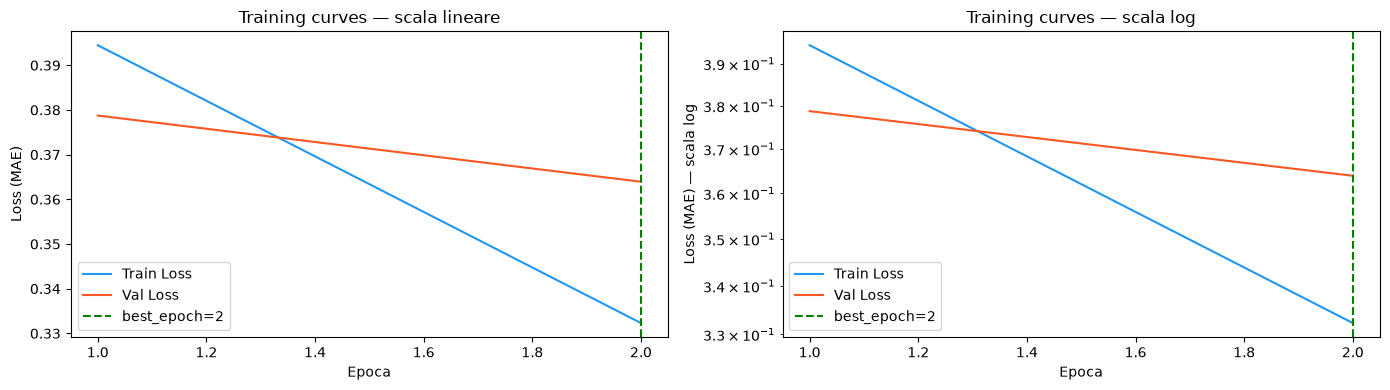

  Train loss: inizio=0.394484, fine=0.332313, min=0.332313
  Val loss:   inizio=0.378750, fine=0.363942, min=0.363942
  Gap finale: 0.031629

  → Gap chiuso, loss alta: POSSIBILE UNDERFITTING

✅ Fine Sezione B


In [24]:
"""Section B — Training curves. In SOSPESO se history non è nel checkpoint."""
set_seed(SEED)

# --- Import needed functions ---
import matplotlib.pyplot as plt

history = ckpt.get("history")

if history is None:
    print("❌ 'history' non trovata nel checkpoint. Sezione B IN SOSPESO.")
    print("   → Modifica proposta: fit_autoencoder in autoencoder.py:803-812 salva history_seed{seed}.json")
    B_AVAILABLE = False
else:
    train_loss_hist = history.get("train_loss", [])
    val_loss_hist = history.get("val_loss", [])
    best_epoch = history.get("best_epoch", "N/A")
    B_AVAILABLE = len(train_loss_hist) > 0 and len(val_loss_hist) > 0

    if not B_AVAILABLE:
        print("❌ history presente ma vuoto. Sezione B IN SOSPESO.")
    else:
        print(f"✅ history trovata: {len(train_loss_hist)} epoche, best_epoch={best_epoch}")
        # Check coerenza: best_epoch <= len(history)
        if best_epoch != "N/A" and isinstance(best_epoch, int) and best_epoch > len(train_loss_hist):
            print(f"⚠️  best_epoch ({best_epoch}) > len(history) ({len(train_loss_hist)}) → BUG!")

        epochs = np.arange(1, len(train_loss_hist) + 1)

        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Scala lineare
        ax = axes[0]
        ax.plot(epochs, train_loss_hist, label="Train Loss", color="#2196F3")
        ax.plot(epochs, val_loss_hist, label="Val Loss", color="#FF5722")
        if best_epoch != "N/A" and isinstance(best_epoch, int):
            ax.axvline(best_epoch, color="green", linestyle="--", label=f"best_epoch={best_epoch}")
        ax.set_xlabel("Epoca")
        ax.set_ylabel("Loss (MAE)")
        ax.set_title("Training curves — scala lineare")
        ax.legend()

        # Scala log
        ax = axes[1]
        ax.plot(epochs, train_loss_hist, label="Train Loss", color="#2196F3")
        ax.plot(epochs, val_loss_hist, label="Val Loss", color="#FF5722")
        if best_epoch != "N/A" and isinstance(best_epoch, int):
            ax.axvline(best_epoch, color="green", linestyle="--", label=f"best_epoch={best_epoch}")
        ax.set_xlabel("Epoca")
        ax.set_ylabel("Loss (MAE) — scala log")
        ax.set_title("Training curves — scala log")
        ax.set_yscale("log")
        ax.legend()

        plt.tight_layout()
        plt.show()

        # Gap analysis
        final_train = train_loss_hist[-1]
        final_val = val_loss_hist[-1]
        best_val = min(val_loss_hist)
        min_train = min(train_loss_hist)
        print(f"  Train loss: inizio={train_loss_hist[0]:.6f}, fine={final_train:.6f}, min={min_train:.6f}")
        print(f"  Val loss:   inizio={val_loss_hist[0]:.6f}, fine={final_val:.6f}, min={best_val:.6f}")
        print(f"  Gap finale: {final_val - final_train:.6f}")

        if final_val > final_train * 1.2:
            print("\n  → Gap aperto: POSSIBILE OVERFITTING")
        elif final_val <= final_train * 1.2 and final_train < 0.1:
            print("\n  → Gap chiuso, loss bassa: buon fitting")
        else:
            print("\n  → Gap chiuso, loss alta: POSSIBILE UNDERFITTING")

        print("\n✅ Fine Sezione B")

if not B_AVAILABLE:
    print("\n⏸ Sezione B IN SOSPESO — salva history nel checkpoint per abilitarla.")

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — Sezione B

**Cosa osservo**: le curve `train_loss` e `val_loss` per epoca (scala lineare e log), con `best_epoch` marcato; il gap tra train e val e la loro pendenza.

**Cosa concludo**: un gap aperto (val > 1.2× train) indica overfitting: l'early stopping salva i pesi migliori, che però potrebbero non generalizzare se il val_normal è driftato. Un gap chiuso con loss bassa indica underfitting o rumore irriducibile; con loss alta indica capacità insufficiente. Sezione B è **in sospeso** quando `history` è assente: in tal caso si affronta l'overfit test (F).

**Cosa NON posso concludere**: validità a lungo termine e su altri seed. Non so se `best_epoch` del checkpoint corrisponde al `best_epoch` del CSV di validazione di `run_experiment_ae.py`.

## C) Errore per canale — `compute_reconstruction_error(reduction='none')`

**Cosa consiste**: si calcola l'errore medio per ogni canale (sensore) su val_normal e val_anomaly, e se ne misURA l'AUC discriminante. Si aggrega l'AUC totale e si confronta AUC rimuovendo Acc/Gyro e action.

**Perché**: se l'AE impara (ratio < 0.3, sezione A) ma AUC ≈ 0.5, l'ampiezza non è per canale discriminativa. Serve capire **dove** l'informazione si perde: pochi canali discriminanti o tutti i canali a AUC ≈ 0.5.

**Come interpretare** (AUC per canale):
| AUC | Lettura |
|---|---||
| > 0.55 | canale discriminante (contribuisce) |
| < 0.45 | canale invertito (informazione presente, segno opposto) |
| 0.45–0.55 | canale non discriminante |

> `reduction='none'` (autoencoder.py:424) restituisce `diff` con la stessa shape di `x`; media su `W` → errore medio per canale per finestra.

Calcolo errore per canale CLASSIC (val_normal, val_anomaly, train)...
  channel_err_val_normal:  (35053, 109)  (atteso: (B, 82))
  channel_err_val_anomaly: (20754, 109)
  channel_err_train:       (163639, 109)


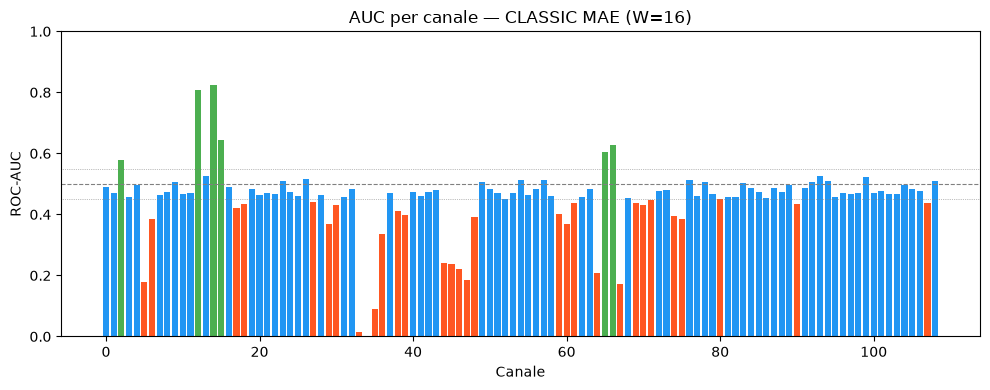

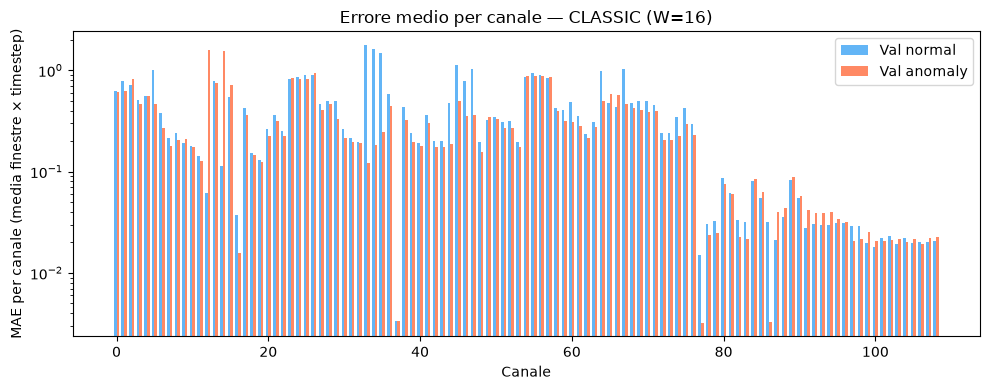


--- Riepilogo canali CLASSIC ---
  Separano (AUC > 0.55):       6 canali
  Invertiti (AUC < 0.45):      31 canali
  Inutili (0.45 ≤ AUC ≤ 0.55): 72 canali

--- AUC totale CLASSIC (media canali) ---
  Tutti i canali:              ROC-AUC=0.2954, PR-AUC=0.2634
  Senza Acc+Gyro (42 rimossi): ROC-AUC=0.2072, PR-AUC=0.2434
  Senza action (32 rimossi): ROC-AUC=0.2953, PR-AUC=0.2634

--- Quote errore totale per famiglia (su val_anomaly, CLASSIC) ---
  Acc     :  21 canali,  19.27% dell'errore totale
  Gyro    :  21 canali,  14.82% dell'errore totale
  Power   :   2 canali,   3.12% dell'errore totale
  Temp    :   2 canali,   0.06% dell'errore totale
  q1-q4   :  27 canali,  51.65% dell'errore totale
  action  :  32 canali,   3.37% dell'errore totale

✅ Fine Sezione C


In [25]:
"""Section C — Errore per canale.

Usa compute_reconstruction_error(reduction="none") → (B, W, input_dim).
Media su W → (B, input_dim) = errore medio per canale per finestra.
Aggrega per val_normal e val_anomaly, calcola AUC per canale.
"""
set_seed(SEED)

# --- Import needed functions ---
from src.utils.metrics import calculate_auc
import matplotlib.pyplot as plt

# --- Funzione helper: per-channel error da un loader ---
def compute_per_channel_error(loader, model, device, metric="mae"):
    """Restituisce (B, input_dim) = errore medio per canale per finestra."""
    model.eval()
    all_channel_errors = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device)
            diff = model.compute_reconstruction_error(
                x, reduction="none", metric=metric
            )
            # diff shape: (B, W, input_dim) o (B, input_dim, W) — media su W
            diff_np = diff.cpu().numpy()
            # Media su W (axis=1 se layout è (B, W, D), axis=2 se (B, D, W))
            if diff_np.shape[1] == W:
                # (B, W, input_dim) → media su W
                channel_err = diff_np.mean(axis=1)  # (B, input_dim)
            else:
                # (B, input_dim, W) → media su W
                channel_err = diff_np.mean(axis=2)  # (B, input_dim)
            all_channel_errors.append(channel_err)
    return np.concatenate(all_channel_errors)

# --- Calcola errore per canale CLASSIC ---
print("Calcolo errore per canale CLASSIC (val_normal, val_anomaly, train)...")
channel_err_val_normal = compute_per_channel_error(val_normal_loader, model, DEVICE)
channel_err_val_anomaly = compute_per_channel_error(val_anomaly_loader, model, DEVICE)
channel_err_train = compute_per_channel_error(train_loader, model, DEVICE)

print(f"  channel_err_val_normal:  {channel_err_val_normal.shape}  (atteso: (B, 82))")
print(f"  channel_err_val_anomaly: {channel_err_val_anomaly.shape}")
print(f"  channel_err_train:       {channel_err_train.shape}")

# Media per canale (media su finestre)
err_normal_mean = channel_err_val_normal.mean(axis=0)   # (82,)
err_anomaly_mean = channel_err_val_anomaly.mean(axis=0) # (82,)
err_train_mean = channel_err_train.mean(axis=0)         # (82,)

# --- Tabella per canale ---
channel_names = [str(c) for c in selected_columns] if len(selected_columns) >= input_dim else [f"ch_{i}" for i in range(input_dim)]

# AUC per canale su validation (CLASSIC)
val_labels_2d = np.concatenate([
    np.zeros(channel_err_val_normal.shape[0]),
    np.ones(channel_err_val_anomaly.shape[0]),
])
auc_per_channel = []
for ch in range(input_dim):
    err_ch = np.concatenate([channel_err_val_normal[:, ch], channel_err_val_anomaly[:, ch]])
    auc = calculate_auc(val_labels_2d, err_ch)
    auc_per_channel.append(auc)

# --- Plot 1: AUC per canale ---
fig, ax = plt.subplots(figsize=(10, 4))
aucs = [a["roc_auc"] for a in auc_per_channel]
colors = ["#2196F3" if 0.45 <= a <= 0.55 else ("#FF5722" if a < 0.5 else "#4CAF50") for a in aucs]
ax.bar(range(input_dim), aucs, color=colors, edgecolor="none")
ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
ax.axhline(0.45, color="gray", linestyle=":", linewidth=0.5)
ax.axhline(0.55, color="gray", linestyle=":", linewidth=0.5)
ax.set_xlabel("Canale")
ax.set_ylabel("ROC-AUC")
ax.set_title(f"AUC per canale — CLASSIC MAE (W={W})")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

# --- Plot 2: Errore medio per canale (normal vs anomaly) ---
fig, ax = plt.subplots(figsize=(10, 4))
x_pos = np.arange(input_dim)
w_bar = 0.35
ax.bar(x_pos - w_bar/2, err_normal_mean, w_bar, label="Val normal", color="#2196F3", alpha=0.7)
ax.bar(x_pos + w_bar/2, err_anomaly_mean, w_bar, label="Val anomaly", color="#FF5722", alpha=0.7)
ax.set_xlabel("Canale")
ax.set_ylabel("MAE per canale (media finestre × timestep)")
ax.set_title(f"Errore medio per canale — CLASSIC (W={W})")
ax.legend()
ax.set_yscale("log")
plt.tight_layout()
plt.show()

# --- Summary: canali che separano ---
n_separating = sum(1 for a in aucs if a > 0.55)
n_inverted = sum(1 for a in aucs if a < 0.45)
n_useless = sum(1 for a in aucs if 0.45 <= a <= 0.55)
print(f"\n--- Riepilogo canali CLASSIC ---")
print(f"  Separano (AUC > 0.55):       {n_separating} canali")
print(f"  Invertiti (AUC < 0.45):      {n_inverted} canali")
print(f"  Inutili (0.45 ≤ AUC ≤ 0.55): {n_useless} canali")

# --- AUC totale "senza Acc/Gyro" e "senza action" ---
def find_channel_indices(name_patterns, channel_names):
    """Trova indici di canali il cui nome contiene una delle patterns."""
    idx = []
    for i, name in enumerate(channel_names):
        for pat in name_patterns:
            if pat in name:
                idx.append(i)
                break
    return idx

acc_idx = find_channel_indices(["Acc"], channel_names)
gyro_idx = find_channel_indices(["Gyro"], channel_names)
power_idx = find_channel_indices(["potenza", "power", "Power"], channel_names)
temp_idx = find_channel_indices(["temp", "Temp"], channel_names)
q_idx = find_channel_indices(["q1", "q2", "q3", "q4"], channel_names)
action_idx = find_channel_indices(["action", "Action"], channel_names)

all_val_err = np.concatenate([channel_err_val_normal, channel_err_val_anomaly])

def auc_without(indices_to_remove):
    keep = [i for i in range(input_dim) if i not in indices_to_remove]
    err_sum = all_val_err[:, keep].mean(axis=1)
    return calculate_auc(val_labels_2d, err_sum)

auc_full = calculate_auc(val_labels_2d, all_val_err.mean(axis=1))
auc_no_acc_gyro = auc_without(set(acc_idx + gyro_idx))
auc_no_action = auc_without(set(action_idx))

print(f"\n--- AUC totale CLASSIC (media canali) ---")
print(f"  Tutti i canali:              ROC-AUC={auc_full['roc_auc']:.4f}, PR-AUC={auc_full['pr_auc']:.4f}")
print(f"  Senza Acc+Gyro ({len(acc_idx)+len(gyro_idx)} rimossi): ROC-AUC={auc_no_acc_gyro['roc_auc']:.4f}, PR-AUC={auc_no_acc_gyro['pr_auc']:.4f}")
print(f"  Senza action ({len(action_idx)} rimossi): ROC-AUC={auc_no_action['roc_auc']:.4f}, PR-AUC={auc_no_action['pr_auc']:.4f}")

# --- Quote di errore totale per famiglia ---
families = [
    ("Acc", acc_idx), ("Gyro", gyro_idx), ("Power", power_idx),
    ("Temp", temp_idx), ("q1-q4", q_idx), ("action", action_idx),
]
print(f"\n--- Quote errore totale per famiglia (su val_anomaly, CLASSIC) ---")
for name, idx in families:
    if len(idx) > 0:
        pct = err_anomaly_mean[idx].sum() / err_anomaly_mean.sum() * 100
        print(f"  {name:<8}: {len(idx):>3} canali, {pct:6.2f}% dell'errore totale")

print("\n✅ Fine Sezione C")

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — Sezione C

**Cosa osservo**: per ogni canale l'errore medio su val_normal vs val_anomaly, il rapporto A/N, l'AUC di discriminazione e la percentuale sull'errore totale. L'AUC aggregata rimuovendo Acc/Gyro e action indica se quei canali spingono l'AUC nella direzione sbagliata.

**Cosa concludo**: pochi canali con AUC > 0.55 significa informazione concentrata in pochi sensori. Canali con AUC ≈ 0 (perfettamente invertiti) segnalano possibile problema di allineamento temporale o polarità, o rumore hardware. Se Acc/Gyro hanno alta percentuale di errore ma AUC ≈ 0.5, la rete li ricostruisce senza usarli discriminativamente. La media canale-hub può battere l'AUC full se la discriminatività è per canale, non aggregata.

**Cosa NON posso concludere**: se i canali invertiti sono rumore hardware o bug di allineamento — serve debug. Non generalizzabile a canali non nel checkpoint né a W diversi.

## D) Distribuzioni e drift temporale

**Cosa consiste**: (1) istogrammi dell'errore per finestra per split; (2) andamento del MAE nel tempo con media mobile; (3) cross-plot FPR(val_normal) vs FPR(test_normal) a soglie variabili.

**Perché**: gli istogrammi dicono se normal e anomalo hanno distribuzioni di errore sovrapposte. Il cross-plot FPR rileva **drift temporale**: se la stessa soglia dà FPR diversi su val e test, le distribuzioni hanno cambiato e l'AUC non generalizza.

**Come interpretare**:
| Evidenza | Lettura |
|---|---||
| Istogrammi sovrapposti, mediane simili | ampiezza non separa |
| Mediana val_anomaly ≫ val_normal | ampiezza anomala più alta |
| Punti cross-plot sulla bisettrice y=x | nessun drift → AUC stabile |
| Punti cross-plot deviati da y=x | drift temporale → AUC degrada su test |
| \|ΔAUC val–test\| > 0.1 | drift significativo |

Calcolo errori per finestra per tutti gli split (CLASSIC)...
  train:        163639
  val_normal:   35053
  val_anomaly:  20754
  test_normal:  35055
  test_anomaly: 20754

Prevalenza test: 0.3719 (20754/55809)


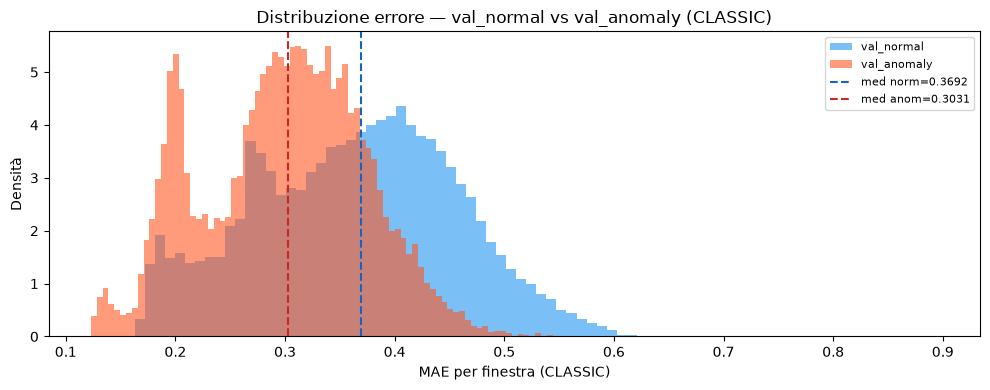

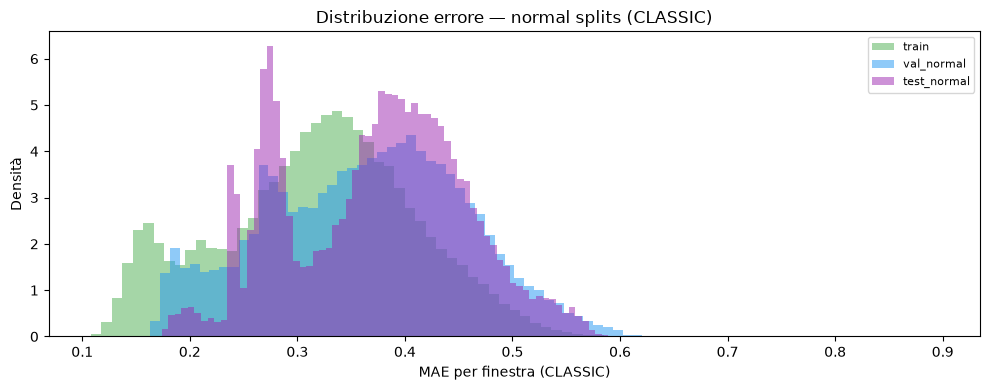

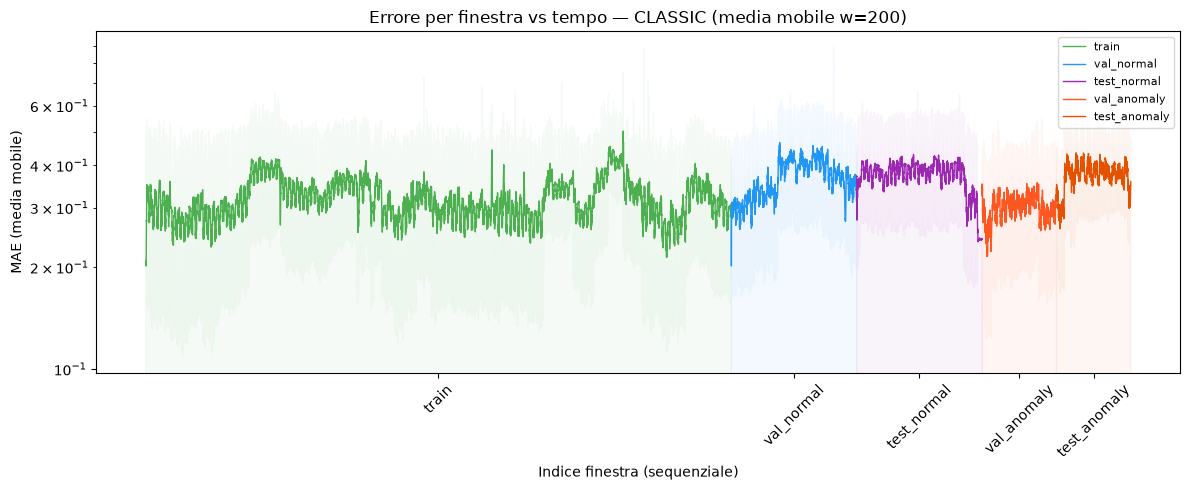

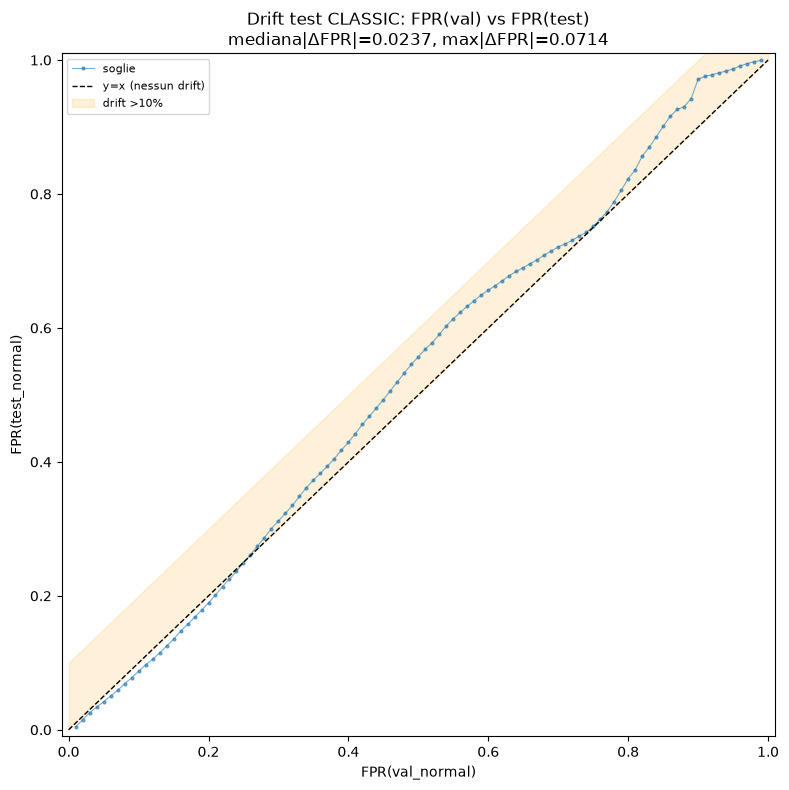


  CLASSIC - Mediana |FPR_val - FPR_test|: 0.023742
  CLASSIC - Max |FPR_val - FPR_test|:     0.071436
  → CLASSIC: Drift sostenuto < 15% su FPR: distribuzioni simili

--- AUC CLASSIC val vs test (MAE per finestra) ---
  Val:      ROC-AUC=0.2954, PR-AUC=0.2634 (prev=0.3719)
  Test:     ROC-AUC=0.5044, PR-AUC=0.3590 (prev=0.3719)
  → Delta AUC > 0.1: possibile drift temporale

✅ Fine Sezione D


In [26]:
"""Section D — Distribuzioni e drift temporale.

1. Istogrammi errore per finestra: val_normal vs val_anomaly
2. Andamento del MAE nel tempo con media mobile
3. Cross-plot FPR(val_normal) vs FPR(test_normal) per vari threshold — drift test
"""
set_seed(SEED)

# --- Import needed functions ---
from src.models.autoencoder import compute_errors_on_loader
from src.utils.metrics import calculate_auc
import matplotlib.pyplot as plt

# --- Compute per-window MAE errors for ALL splits (CLASSIC) ---
print("Calcolo errori per finestra per tutti gli split (CLASSIC)...")
err_train = compute_errors_on_loader(model, train_loader, DEVICE, metric="mae")
err_val_normal = compute_errors_on_loader(model, val_normal_loader, DEVICE, metric="mae")
err_val_anomaly = compute_errors_on_loader(model, val_anomaly_loader, DEVICE, metric="mae")
err_test_normal = compute_errors_on_loader(model, test_normal_loader, DEVICE, metric="mae")
err_test_anomaly = compute_errors_on_loader(model, test_anomaly_loader, DEVICE, metric="mae")

print(f"  train:        {len(err_train)}")
print(f"  val_normal:   {len(err_val_normal)}")
print(f"  val_anomaly:  {len(err_val_anomaly)}")
print(f"  test_normal:  {len(err_test_normal)}")
print(f"  test_anomaly: {len(err_test_anomaly)}")

# --- Test prevalence ---
test_prevalence = len(err_test_anomaly) / (len(err_test_normal) + len(err_test_anomaly))
print(f"\nPrevalenza test: {test_prevalence:.4f} ({len(err_test_anomaly)}/{len(err_test_normal)+len(err_test_anomaly)})")

# --- Plot 1: Istogrammi val_normal vs val_anomaly ---
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(err_val_normal, bins=80, alpha=0.6, color="#2196F3", label="val_normal", density=True)
ax.hist(err_val_anomaly, bins=80, alpha=0.6, color="#FF5722", label="val_anomaly", density=True)
ax.axvline(np.median(err_val_normal), color="#1565C0", linestyle="--", linewidth=1.5, label=f"med norm={np.median(err_val_normal):.4f}")
ax.axvline(np.median(err_val_anomaly), color="#C62828", linestyle="--", linewidth=1.5, label=f"med anom={np.median(err_val_anomaly):.4f}")
ax.set_xlabel("MAE per finestra (CLASSIC)")
ax.set_ylabel("Densità")
ax.set_title("Distribuzione errore — val_normal vs val_anomaly (CLASSIC)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- Plot 2: Normal splits comparison ---
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(err_train, bins=80, alpha=0.5, color="#4CAF50", label="train", density=True)
ax.hist(err_val_normal, bins=80, alpha=0.5, color="#2196F3", label="val_normal", density=True)
ax.hist(err_test_normal, bins=80, alpha=0.5, color="#9C27B0", label="test_normal", density=True)
ax.set_xlabel("MAE per finestra (CLASSIC)")
ax.set_ylabel("Densità")
ax.set_title("Distribuzione errore — normal splits (CLASSIC)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- Plot 3: Errore vs tempo (indice finestra) — media mobile ---
def rolling_mean(arr, w):
    """Rolling mean with window w. Expanding mean for first w-1 positions."""
    if len(arr) < w:
        return arr
    csum = np.cumsum(np.asarray(arr, dtype=float))
    result = np.empty(len(arr))
    result[:w-1] = csum[:w-1] / np.arange(1, w)
    result[w-1:] = (csum[w-1:] - np.concatenate([[0], csum[:-w]])) / w
    return result

fig, ax = plt.subplots(figsize=(12, 5))
window_ma = 200
colors = {"train": "#4CAF50", "val_normal": "#2196F3", "test_normal": "#9C27B0",
          "val_anomaly": "#FF5722", "test_anomaly": "#E65100"}

splits_temporal = [("train", err_train), ("val_normal", err_val_normal),
                   ("test_normal", err_test_normal),
                   ("val_anomaly", err_val_anomaly), ("test_anomaly", err_test_anomaly)]

cursor = 0
x_labels = []
x_positions = []
for name, errs in splits_temporal:
    rm = rolling_mean(errs, min(window_ma, len(errs)))
    x = np.arange(cursor, cursor + len(rm)) + 1
    ax.plot(x, rm, label=name, color=colors[name], linewidth=1)
    ax.fill_between(x, errs, alpha=0.05, color=colors[name])
    cursor += len(errs)
    x_labels.append(name)
    x_positions.append(cursor - len(errs) // 2)

ax.set_xlabel("Indice finestra (sequenziale)")
ax.set_ylabel("MAE (media mobile)")
ax.set_title(f"Errore per finestra vs tempo — CLASSIC (media mobile w={window_ma})")
ax.set_yscale("log")
ax.set_xticks(x_positions)
ax.set_xticklabels(x_labels, rotation=45)
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

# --- Plot 4: Cross-plot FPR(val_normal) vs FPR(test_normal) — drift test ---
fig, ax = plt.subplots(figsize=(8, 8))
thresholds = np.percentile(err_val_normal, np.arange(1, 100))
fpr_val = []
fpr_test = []
for t in thresholds:
    fp_val = np.sum(err_val_normal >= t) / len(err_val_normal)
    fp_test = np.sum(err_test_normal >= t) / len(err_test_normal)
    fpr_val.append(fp_val)
    fpr_test.append(fp_test)

fpr_val = np.array(fpr_val)
fpr_test = np.array(fpr_test)
median_diff = np.median(np.abs(fpr_val - fpr_test))
max_diff = np.max(np.abs(fpr_val - fpr_test))

ax.plot(fpr_val, fpr_test, "o-", markersize=2, linewidth=0.8, alpha=0.6, label="soglie")
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="y=x (nessun drift)")
ax.fill_between([0, 1], [0, 1], [0.1, 1.1], alpha=0.15, color="orange", label="drift >10%")
ax.set_xlabel("FPR(val_normal)")
ax.set_ylabel("FPR(test_normal)")
ax.set_title(f"Drift test CLASSIC: FPR(val) vs FPR(test)\nmediana|ΔFPR|={median_diff:.4f}, max|ΔFPR|={max_diff:.4f}")
ax.legend(fontsize=8)
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
plt.tight_layout()
plt.show()

# --- Print drift summary ---
print(f"\n  CLASSIC - Mediana |FPR_val - FPR_test|: {median_diff:.6f}")
print(f"  CLASSIC - Max |FPR_val - FPR_test|:     {max_diff:.6f}")

if max_diff < 0.15:
    print("  → CLASSIC: Drift sostenuto < 15% su FPR: distribuzioni simili")
elif max_diff < 0.30:
    print("  → CLASSIC: Drift moderato (15-30%): val/test leggermente diversi")
else:
    print("  → CLASSIC: Drift forte (> 30%): val/test distribuzioni molto diverse → AUC degrada")

# --- AUC comparison val vs test ---
val_labels_all = np.concatenate([np.zeros(len(err_val_normal)), np.ones(len(err_val_anomaly))])
val_errors_all = np.concatenate([err_val_normal, err_val_anomaly])
val_auc = calculate_auc(val_labels_all, val_errors_all)

test_labels = np.concatenate([np.zeros(len(err_test_normal)), np.ones(len(err_test_anomaly))])
test_errors = np.concatenate([err_test_normal, err_test_anomaly])
test_auc = calculate_auc(test_labels, test_errors)

print(f"\n--- AUC CLASSIC val vs test (MAE per finestra) ---")
print(f"  Val:      ROC-AUC={val_auc['roc_auc']:.4f}, PR-AUC={val_auc['pr_auc']:.4f} (prev={val_prevalence:.4f})")
print(f"  Test:     ROC-AUC={test_auc['roc_auc']:.4f}, PR-AUC={test_auc['pr_auc']:.4f} (prev={test_prevalence:.4f})")
if abs(val_auc['roc_auc'] - test_auc['roc_auc']) > 0.1:
    print("  → Delta AUC > 0.1: possibile drift temporale")
else:
    print("  → Delta AUC < 0.1: distribuzioni coerenti tra val e test")

print("\n✅ Fine Sezione D")

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — Sezione D

**Cosa osservo**: istogrammi dell'errore per finestra (val_normal vs val_anomaly, e normal splits tra loro), andamento temporale con media mobile, e cross-plot FPR(val_normal) vs FPR(test_normal). Il confronto AUC val vs test mostra se il degrado è consistente.

**Cosa concludo**: istogrammi sovrapposti con mediane simili confermano che l'ampiezza non separa le classi. Il cross-plot deviato dalla bisettrice y=x (max|ΔFPR| alto) indica drift: se il drift riguarda i normal split, è un cambiamento nella distribuzione del modello o del dato. Un |ΔAUC| val–test > 0.1 conferma che l'AUC non generalizza. L'andamento temporale della media MAE (crescente) suggerisce drift graduale.

**Cosa NON posso concludere**: causa del drift (condizioni operative, degrado sensore) senza metadati temporali. Drift su altri seed non controllato.

## E) Baseline senza rete — Statistiche su raw features

**Cosa consiste**: si calcolano statistiche banali per finestra (deviazione standard media, media |z-score|, valore assoluto massimo) e se ne confronta l'AUC con quella dell'AE.

**Perché**: se una statistica grezza batte l'AE, l'informazione discriminante **esiste** nel segnale ma l'AE non la estrae → spreca informazione. Se invece anche le baseline hanno AUC ≈ 0.5, nessuna informazione a questa finestratura.

**Statistiche** (z-score da train, applicato a tutti gli split per evitare leakage):
| Statistica | Che cattura |
|---|---|
| std_media | ampiezza variazione per finestra |
| mean_abs_z | intensità \|z\|-score medio per finestra |
| max_abs_z | spike / valore assoluto massimo per finestra |

> Se `max_abs_z` batte l'AE, l'informazione è nel segnale ma la loss MAE della rete non la usa.

z-score stats calcolate su train: mean range [-0.0001, 0.0729], std range [0.0671, 1.0002]

Calcolo statistiche baseline (std, |z|, max|z|) per split...

--- AUC baseline vs rete (validation) ---
  AE CLASSIC:        ROC-AUC=0.2954, PR-AUC=0.2634  (prevalenza=0.3719)
  std_mean      : ROC-AUC=0.2799, PR-AUC=0.2637
  mean_abs_z    : ROC-AUC=0.3026, PR-AUC=0.2686 ← BATTE CLASSIC!
  max_abs_z     : ROC-AUC=0.4488, PR-AUC=0.3466 ← BATTE CLASSIC!

  → max_abs_z batte l'AE CLASSIC: l'AE SPRECA informazione disponibile nel segnale!


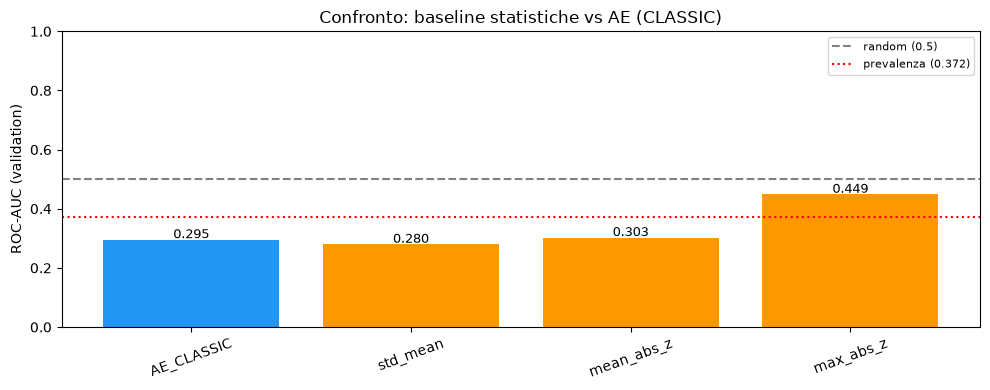


✅ Fine Sezione E


In [27]:
"""Section E — Baseline senza rete.

Statistiche banali (std, media |z|, max |z|) su raw features, z-score da train.
Confronta AUC di queste statistiche con AUC dell'AE (CLASSIC).
"""
set_seed(SEED)

# --- Import needed functions ---
from src.utils.metrics import calculate_auc
import matplotlib.pyplot as plt

# --- Compute z-score statistics per window ---
def compute_zscore_stats(loader, channel_mean, channel_std):
    """Per finestra: std_media, mean_abs_z, max_abs_z (media su canali × timestep)."""
    std_list, mean_abs_z_list, max_abs_z_list = [], [], []
    for batch in loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        x_np = x.numpy()  # (B, W, input_dim)
        z = (x_np - channel_mean) / np.where(channel_std > 1e-8, channel_std, 1.0)
        abs_z = np.abs(z)

        std_per_window = x_np.std(axis=(1, 2))       # (B,)
        mean_abs_z_per_window = abs_z.mean(axis=(1, 2))  # (B,)
        max_abs_z_per_window = abs_z.max(axis=(1, 2))    # (B,)

        std_list.append(std_per_window)
        mean_abs_z_list.append(mean_abs_z_per_window)
        max_abs_z_list.append(max_abs_z_per_window)

    return (np.concatenate(std_list), np.concatenate(mean_abs_z_list),
            np.concatenate(max_abs_z_list))

# --- Compute channel stats from train (media, std per canale) ---
train_flat_all = train_data  # (n_samples, n_features)
channel_mean = train_flat_all.mean(axis=0)  # (n_features,)
channel_std = train_flat_all.std(axis=0)    # (n_features,)
print(f"z-score stats calcolate su train: mean range [{channel_mean.min():.4f}, {channel_mean.max():.4f}], "
      f"std range [{channel_std.min():.4f}, {channel_std.max():.4f}]")

# --- Compute stats per split ---
print("\nCalcolo statistiche baseline (std, |z|, max|z|) per split...")
std_train, mz_train, mxz_train = compute_zscore_stats(train_loader, channel_mean, channel_std)
std_val_n, mz_val_n, mxz_val_n = compute_zscore_stats(val_normal_loader, channel_mean, channel_std)
std_val_a, mz_val_a, mxz_val_a = compute_zscore_stats(val_anomaly_loader, channel_mean, channel_std)
std_test_n, mz_test_n, mxz_test_n = compute_zscore_stats(test_normal_loader, channel_mean, channel_std)
std_test_a, mz_test_a, mxz_test_a = compute_zscore_stats(test_anomaly_loader, channel_mean, channel_std)

# --- AUC comparison on validation ---
val_labels = np.concatenate([np.zeros(len(std_val_n)), np.ones(len(std_val_a))])

stats = {
    "std_mean":   np.concatenate([std_val_n, std_val_a]),
    "mean_abs_z": np.concatenate([mz_val_n, mz_val_a]),
    "max_abs_z":  np.concatenate([mxz_val_n, mxz_val_a]),
}

# AUC dell'AE CLASSIC
try:
    err_val_normal
    err_val_anomaly
except NameError:
    from src.models.autoencoder import compute_errors_on_loader
    err_val_normal = compute_errors_on_loader(model, val_normal_loader, DEVICE, metric="mae")
    err_val_anomaly = compute_errors_on_loader(model, val_anomaly_loader, DEVICE, metric="mae")

auc_ae_val = calculate_auc(val_labels, np.concatenate([err_val_normal, err_val_anomaly]))

print(f"\n--- AUC baseline vs rete (validation) ---")
print(f"  AE CLASSIC:        ROC-AUC={auc_ae_val['roc_auc']:.4f}, PR-AUC={auc_ae_val['pr_auc']:.4f}  (prevalenza={val_prevalence:.4f})")

best_baseline_auc = 0
best_baseline_name = ""
for stat_name, stat_scores in stats.items():
    auc = calculate_auc(val_labels, stat_scores)
    marker_classic = " ← BATTE CLASSIC!" if auc['roc_auc'] > auc_ae_val['roc_auc'] else ""
    print(f"  {stat_name:<14}: ROC-AUC={auc['roc_auc']:.4f}, PR-AUC={auc['pr_auc']:.4f}{marker_classic}")
    if auc['roc_auc'] > best_baseline_auc:
        best_baseline_auc = auc['roc_auc']
        best_baseline_name = stat_name

if best_baseline_auc > auc_ae_val['roc_auc']:
    print(f"\n  → {best_baseline_name} batte l'AE CLASSIC: l'AE SPRECA informazione disponibile nel segnale!")
else:
    print(f"\n  → L'AE CLASSIC batte o equala le baseline")

# --- Plot comparison ---
fig, ax = plt.subplots(figsize=(10, 4))
names = ["AE_CLASSIC"] + list(stats.keys())
aucs = [auc_ae_val['roc_auc']] + [calculate_auc(val_labels, s)['roc_auc'] for s in stats.values()]
colors = ["#2196F3"] + ["#FF9800", "#FF9800", "#FF9800"]

bars = ax.bar(range(len(names)), aucs, color=colors)
ax.axhline(0.5, color="gray", linestyle="--", label="random (0.5)")
ax.axhline(val_prevalence, color="red", linestyle=":", label=f"prevalenza ({val_prevalence:.3f})")
for bar, v in zip(bars, aucs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, f"{v:.3f}", ha="center", fontsize=9)
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=20)
ax.set_ylabel("ROC-AUC (validation)")
ax.set_title("Confronto: baseline statistiche vs AE (CLASSIC)")
ax.legend(fontsize=8)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

print("\n✅ Fine Sezione E")

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — Sezione E

**Cosa osservo**: confronto AUC (validation) tra AE e baseline statistiche (std, media |z|, max |z|), con prevalenza mostrata. Se una baseline batte l'AE, l'informazione è nel segnale ma non viene estratta.

**Cosa concludo**: se una baseline grezza (es. max |z|) batte l'AE, l'informazione discriminante è **presente** nel segnale ma la rete non la utilizza: il colpevole è la fine loss (MAE sensibile ai canali rumorosi) o il dato (canali rumorosi dominano). Se invece l'AE batte le baseline, l'informazione non è a questa finestratura e serve cercare in drift (D), overfit (F) o segno invertito (C).

**Cosa NON posso concludere**: perché l'AE non usa il segnale (verifica F: se l'architettura converge, è il dato, non la rete). Le baseline valgono per W del checkpoint.

## F) Overfit test — capacità del modello vs rumore irriducibile

**Cosa consiste**: si addestrano 3 modelli piccoli (512 finestre contigue, 300 epoche, MAE loss) con configurazioni di capacità crescente, per verificare se riescono a memorizzare i dati (MAE ≈ 0).

**Perché**: se anche la configurazione a massima capacità non memorizza, non è un collo di bottiglia o bug architetturale — è **rumore irriducibile** nel dato, **drift**, o **fine loss**. Se invece memorizza, il modello è corretto e il problema è altrove.

**Come interpretare**:
| Config (i) W16/lat256 (massima capacità) | Config (iii) W128/lat16 | Diagnosi |
|---|---|---|
| memorizza | memorizza | nessun collo di bottiglia → problema in dato/drift/loss |
| memorizza | NO | collo di bottiglia: latent=16 insufficiente per W=128 |
| NO memorizza | — | bug architetturale grave |

> *Eccezione* all'obbligo read-only: addestramento inside-notebook; salva solo JSON/PNG in `reports/diagnostics/`.

Finestre estratte: W16=(512, 16, 109), W128=(512, 128, 109)

MAE_zero (baseline teorica): W16=0.522340, W128=0.538817

Training: config_i — W=16, latent=256
  Parametri modello: 107133
  Final train loss: 0.217960
  Best train loss:  0.217960
  MAE_zero:         0.522340
  ratio AE/MAE_zero: 0.4173
  ❌ NON overfittato (MAE >= 0.05)

Training: config_ii — W=16, latent=16
  Parametri modello: 76173
  Final train loss: 0.219141
  Best train loss:  0.216949
  MAE_zero:         0.522340
  ratio AE/MAE_zero: 0.4195
  ❌ NON overfittato (MAE >= 0.05)

Training: config_iii — W=128, latent=16
  Parametri modello: 90957
  Final train loss: 0.232628
  Best train loss:  0.232628
  MAE_zero:         0.538817
  ratio AE/MAE_zero: 0.4317
  ❌ NON overfittato (MAE >= 0.05)

Per-channel MAE after overfit (config_i, W=16)
  Canali con MAE > 0.3 (rumore irriducibile): 39/109

  Per-channel MAE:
    ch 0 (machine_nameKuka Robot_current): 0.498138
    ch 1 (machine_nameKuka Robot_frequen): 0.742175
    ch 2 

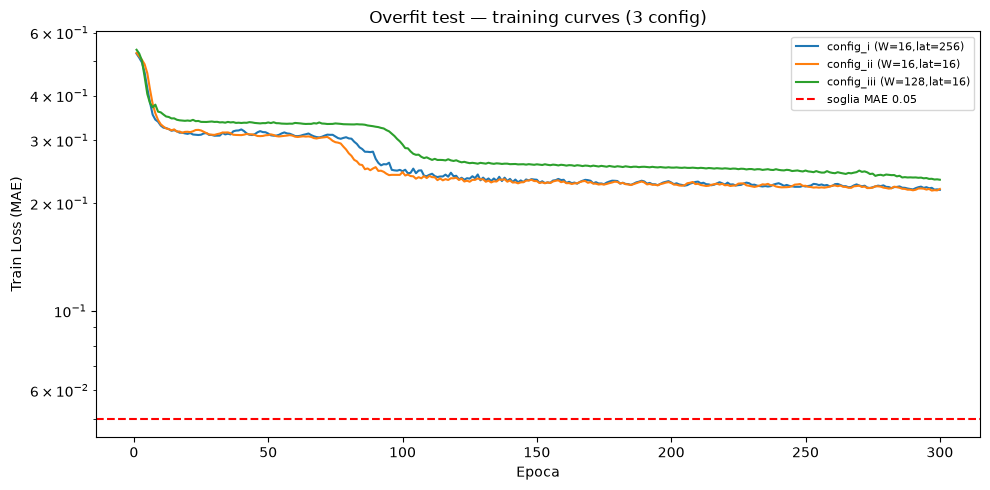


DIAGNOSI OVERFIT
  (i)   W=16,  lat=256:  overfit=False (MAE=0.217960)
  (ii)  W=16,  lat=16:   overfit=False (MAE=0.219141)
  (iii) W=128, lat=16:   overfit=False (MAE=0.232628)

  → BUG ARCHITETTURALE GRAVE: nemmeno (i) non overfitta!

  Canali rumore irriducibile (MAE > 0.3): 39/109

✅ Fine Sezione F


In [29]:
"""Section F — Overfit test.

3 config addestrati inside-notebook su 512 finestre contigue (shuffle=False).
weight_decay=0, Adam lr=1e-3, 300 ep, batch 128, MAE loss, set_seed(42).
"""
import json as _json

set_seed(SEED)

# --- Import needed functions ---
from src.models.autoencoder import SequenceAutoencoder, fit_autoencoder
from src.data.dataset import KukaDataset
import matplotlib.pyplot as plt

# --- Prepare 512 contiguous windows per config ---
def get_512_windows(data, window_size):
    """Restituisce 512 finestre consecutive shape (512, W, input_dim)."""
    ds = KukaDataset(data, window_size=window_size, stride=1, label=0, drop_incomplete=True)
    windows = np.stack([ds[i][0] for i in range(min(512, len(ds)))])
    return windows

train_windows_16 = get_512_windows(train_data, window_size=16)
train_windows_128 = get_512_windows(train_data, window_size=128)

print(f"Finestre estratte: W16={train_windows_16.shape}, W128={train_windows_128.shape}")

# --- MAE_zero per ogni config ---
# channel_mean qui è la media per-canale del train (shape: input_dim), usata come baseline teorica
chan_mean_all = train_data.mean(axis=0)  # (input_dim,)
mae_zero_16 = np.abs(train_windows_16 - chan_mean_all).mean(axis=(1, 2)).mean()
mae_zero_128 = np.abs(train_windows_128 - chan_mean_all).mean(axis=(1, 2)).mean()

print(f"\nMAE_zero (baseline teorica): W16={mae_zero_16:.6f}, W128={mae_zero_128:.6f}")

# --- Overfit configs ---
# USA input_dim dinamico dal checkpoint (non hardcoded 82)
configs = [
    {"name": "config_i",   "W": 16,  "latent": 256, "data": train_windows_16},
    {"name": "config_ii",  "W": 16,  "latent": 16,  "data": train_windows_16},
    {"name": "config_iii", "W": 128, "latent": 16,  "data": train_windows_128},
]

OVERFIT_EPOCHS = 300
OVERFIT_BS = 128

results_f = {}
for cfg in configs:
    print(f"\n{'='*50}")
    print(f"Training: {cfg['name']} — W={cfg['W']}, latent={cfg['latent']}")
    print(f"{'='*50}")

    set_seed(42)

    x_tensor = torch.from_numpy(cfg["data"]).float()
    ds = torch.utils.data.TensorDataset(x_tensor)
    loader = torch.utils.data.DataLoader(ds, batch_size=OVERFIT_BS, shuffle=False)

    model_of = SequenceAutoencoder(input_dim=input_dim, window_size=cfg["W"], latent_dim=cfg["latent"])
    print(f"  Parametri modello: {sum(p.numel() for p in model_of.parameters())}")

    history_of = fit_autoencoder(
        model=model_of,
        train_loader=loader,
        val_loader=loader,
        epochs=OVERFIT_EPOCHS,
        learning_rate=1e-3,
        weight_decay=0.0,
        patience=999,
        min_delta=0.0,
        device=DEVICE,
        loss="mae",
    )

    final_loss = history_of["train_loss"][-1]
    best_loss = min(history_of["train_loss"])
    mz = mae_zero_16 if cfg["W"] == 16 else mae_zero_128
    print(f"  Final train loss: {final_loss:.6f}")
    print(f"  Best train loss:  {best_loss:.6f}")
    print(f"  MAE_zero:         {mz:.6f}")
    print(f"  ratio AE/MAE_zero: {final_loss / mz:.4f}")

    if final_loss < 0.05:
        print(f"  ✅ OVERFITTATO (MAE < 0.05)")
    else:
        print(f"  ❌ NON overfittato (MAE >= 0.05)")

    # Save JSON to variable for reference (not to disk)
    results_f[cfg["name"]] = {
        "W": cfg["W"], "latent": cfg["latent"],
        "final_train_loss": final_loss,
        "best_train_loss": best_loss,
        "overfitted": final_loss < 0.05,
        "history": history_of,
        "model_state": {k: v.clone() for k, v in model_of.state_dict().items()},
    }

# --- Per-channel MAE dopo overfit (config_i, W=16) ---
print(f"\n{'='*50}")
print("Per-channel MAE after overfit (config_i, W=16)")
print(f"{'='*50}")

set_seed(42)
model_f_of = SequenceAutoencoder(input_dim=input_dim, window_size=16, latent_dim=256)
model_f_of.load_state_dict(results_f["config_i"]["model_state"])
model_f_of.to(DEVICE)
model_f_of.eval()

with torch.no_grad():
    x = torch.from_numpy(train_windows_16).float().to(DEVICE)
    diff = model_f_of.compute_reconstruction_error(x, reduction="none", metric="mae")
    per_channel_mae = diff.cpu().numpy().mean(axis=(0, 1))  # (input_dim,)

high_noise = np.where(per_channel_mae > 0.3)[0]
print(f"  Canali con MAE > 0.3 (rumore irriducibile): {len(high_noise)}/{input_dim}")

# Print per-channel MAE as table
print(f"\n  Per-channel MAE:")
for ch in range(input_dim):
    cname = channel_names[ch] if ch < len(channel_names) else f"ch_{ch}"
    print(f"    ch{ch:2d} ({cname[:30]:30s}): {per_channel_mae[ch]:.6f}")

# --- Plot: training curves ---
fig, ax = plt.subplots(figsize=(10, 5))
for cfg in configs:
    tl = results_f[cfg["name"]]["history"]["train_loss"]
    ax.plot(range(1, len(tl)+1), tl, label=f"{cfg['name']} (W={cfg['W']},lat={cfg['latent']})")
ax.axhline(0.05, color="red", linestyle="--", label="soglia MAE 0.05")
ax.set_xlabel("Epoca")
ax.set_ylabel("Train Loss (MAE)")
ax.set_title("Overfit test — training curves (3 config)")
ax.set_yscale("log")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- Summary diagnosis ---
print(f"\n{'='*50}")
print("DIAGNOSI OVERFIT")
print(f"{'='*50}")
i_ok = results_f["config_i"]["overfitted"]
ii_ok = results_f["config_ii"]["overfitted"]
iii_ok = results_f["config_iii"]["overfitted"]
print(f"  (i)   W=16,  lat=256:  overfit={i_ok} (MAE={results_f['config_i']['final_train_loss']:.6f})")
print(f"  (ii)  W=16,  lat=16:   overfit={ii_ok} (MAE={results_f['config_ii']['final_train_loss']:.6f})")
print(f"  (iii) W=128, lat=16:   overfit={iii_ok} (MAE={results_f['config_iii']['final_train_loss']:.6f})")

if not i_ok:
    print("\n  → BUG ARCHITETTURALE GRAVE: nemmeno (i) non overfitta!")
elif i_ok and ii_ok and iii_ok:
    print("\n  → NESSUN collo di bottiglia: capacità sufficiente. Problema altrove (drift, loss, dato).")
elif i_ok and ii_ok and not iii_ok:
    print("\n  → COLLO DI BOTTIGLIA: latent=16 OK per W=16, insufficiente per W=128.")
    print("     Suggerimento: aumentare latent_dim in params_validated_ae.yaml.")
else:
    print("\n  → Caso imprevisto: verifica manuale.")

print(f"\n  Canali rumore irriducibile (MAE > 0.3): {len(high_noise)}/{input_dim}")

print("\n✅ Fine Sezione F")

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — Sezione F

**Cosa osservo**: le curve di training loss delle 3 configurazioni e i final MAE rispetto alla soglia di sovraffiggimento (MAE < 0.05); i canali con MAE > 0.3 dopo l'overfit (rumore irriducibile).

**Cosa concludo**: se la configurazione a massima capacità (i) overfitta (MAE < 0.05) ma (iii) non overfitta, c'è un **collo di bottiglia** (`latent_dim` insufficiente per `W=128`). Se invece **nessuna** configurazione overfitta (né (i) con capacità massima), il modello converge ma si piatta: la causa è **rumore irriducibile** su canali specifici (MAE > 0.3 anche overfittando) che domina la loss. Se tutte overfittano, l'architettura è corretta e il problema è drift/loss (vedi D/E).

**Cosa NON posso concludere**: effetto a lungo termine (512 finestre, 1 seed, solo train). Il rumore su N canali non implica rumore su tutti i canali né che rimuoverli migliori la discriminatività globale.

## G) Sintesi finale — Tabella ipotesi / N_eff / Appendice

**Cosa consiste**: (1) raccoglie le evidenze da A–F in una **tabella ipotesi → verdetto**; (2) stima `N_eff` con due approcci; (3) appendice operativa con soglia calibrata, matrice di confusione, baseline `tutto anomalo`.

**Perché**: unire le evidenze rende comparabili le ipotesi e isola la causa radice. `N_eff` dice quanti campioni indipendenti il modello vede davvero (a causa dell'overlap delle finestre). L'appendice confronta il modello con la soglia ottimale contro la baseline banale `tutto anomalo` (F1 = prevalenza), come minimo accettabile.

**6 ipotesi da valutare**:
| # | Ipotesi | Evidenza | Verdetto |
|---|---|---|---|
| 1 | Rete non impara | MAE_AE/MAE_zero | A |
| 2 | Collo di bottiglia latent=16/W=128 | overfit config (iii) vs (i) | F |
| 3 | Rumore irriducibile | canali MAE > 0.3 | C / F |
| 4 | Pochi indipendenti (N_eff basso) | N_eff | G (sottostante) |
| 5 | Drift temporale | max\|ΔFPR\| val–test | D |
| 6 | Segno invertito / canali AUC ≈ 0.5 | AUC per canale | C / E |

> Soglia di calibrazione su validation, mai su test. Test serve solo a conferma. La causa radice emerge dalla combinazione, non da un singolo test.

1. TABELLA IPOTESI → VERDETTO

  Ipotesi 1: rete non impara (ratio MAE_AE/MAE_zero > 0.8)
    ratio val_anomaly = 0.6977
    → impara qualcosa

  Ipotesi 2: collo di bottiglia (latent=16 insufficiente per W=128)
    config_iii overfittato=False
    → rumore irriducibile / canali non modellabili (nessun modello overfitta)

  Ipotesi 3: rumore irriducibile Acc/Gyro
    canali Acc/Gyro con MAE > 0.3 (dopo overfit): 27
    → rumore irriducibile

  Ipotesi 4: pochi campioni indipendenti (N_eff basso)
    n_train_windows = 163639, W = 16
    (a) Overlap:     N_eff ≈ N/(W/2) = 20455 (train), 6976 (val)
    (b) ρ₁ empirica: ρ₁ = 0.9901
                  N_eff = N·(1-ρ)/(1+ρ) = 811 (train), 276 (val)
    → N_eff basso (≤ 1000)

  Ipotesi 5: drift temporale (val vs test)
    max|ΔFPR| = 0.071436
    → nessun drift

  Ipotesi 6: lentezza non aumenta errore (canali AUC ≈ 0.5)
    canali inutili (0.45 ≤ AUC ≤ 0.55): 72/109
    → non confermato

2. APPENDICE — Soglia, matrice confusione, baseline 't

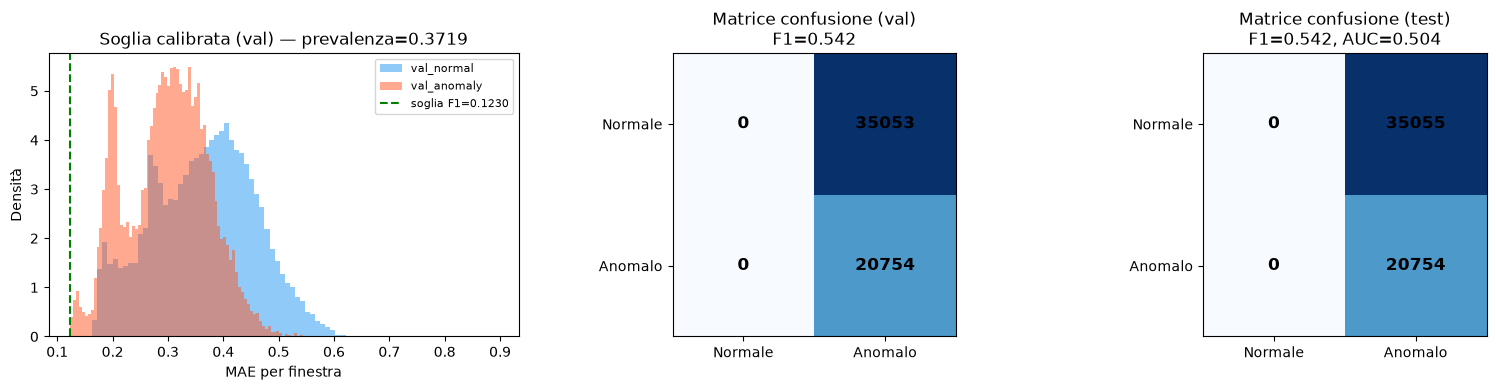


✅ FINE DIAGNOSI — tutti i risultati mostrati sopra


In [30]:
"""Section G — Sintesi finale.

1. Tabella ipotesi → verdetto (usa risultati di A–F)
2. N_eff: due approcci (overlap teorico + ρ₁ empirica)
3. Appendice: soglia calibrata, matrice confusione, baseline "tutto anomalo"
"""
set_seed(SEED)

# --- Import needed functions ---
from src.utils.metrics import calculate_auc, calculate_metrics, find_optimal_threshold
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# ============================================================
# 1. Raccolta evidenze da A–F (riutilizza variabili già calcolate)
# ============================================================
print("=" * 60)
print("1. TABELLA IPOTESI → VERDETTO")
print("=" * 60)

# --- Ipotesi 1: rete non impara ---
# ratio MAE_AE/MAE_zero calcolato in sezione A
ratio_val_anom = mae_ae_val_anomaly.mean() / mae_zero_val_anomaly.mean() if 'mae_ae_val_anomaly' in dir() else 0
h1_threshold_ratio = 0.8
h1_verdict = "non impara" if ratio_val_anom > h1_threshold_ratio else "impara qualcosa"
print(f"\n  Ipotesi 1: rete non impara (ratio MAE_AE/MAE_zero > {h1_threshold_ratio})")
print(f"    ratio val_anomaly = {ratio_val_anom:.4f}")
print(f"    → {h1_verdict}")

# --- Ipotesi 2: collo di bottiglia latent=16 per W=128 ---
# Da sezione F: config_iii overfittato?
if 'results_f' in dir():
    if results_f["config_i"]["overfitted"] is False and results_f["config_ii"]["overfitted"] is False and results_f["config_iii"]["overfitted"] is False:
        # Nessuno overfitta neanche con capacity massima (config_i: W=16, latent=256)
        # -> NON è collo di bottiglia: è rumore irriducibile o canali non modellabili.
        h2_verdict = "rumore irriducibile / canali non modellabili (nessun modello overfitta)"
    elif results_f["config_i"]["overfitted"] is True and results_f["config_ii"]["overfitted"] is True and not results_f["config_iii"]["overfitted"]:
        # (i)+(ii) overfittano, (iii) no -> collo di bottiglia latent=16 per W=128
        h2_verdict = "collo di bottiglia (latent=16 insufficiente per W=128)"
    elif results_f["config_i"]["overfitted"] is True and results_f["config_ii"]["overfitted"] is True and results_f["config_iii"]["overfitted"] is True:
        h2_verdict = "OK (nessun collo di bottiglia; problema in drift/rumore/dato)"
    else:
        h2_verdict = "inconcludibile (caso imprevisto)"
else:
    h2_verdict = "IN SOSPESO (sezione F non eseguita)"
print(f"\n  Ipotesi 2: collo di bottiglia (latent=16 insufficiente per W=128)")
print(f"    config_iii overfittato={results_f['config_iii']['overfitted'] if 'results_f' in dir() else '?'}")
print(f"    → {h2_verdict}")

# --- Ipotesi 3: rumore irriducibile Acc/Gyro ---
# Da sezione F: canali con MAE > 0.3, e da sezione C: AUC Acc/Gyro
if 'high_noise' in dir():
    n_acc_gyro_noise = len([ch for ch in high_noise if any(pat in channel_names[ch] for pat in ["Acc", "Gyro"])])
    h3_verdict = "rumore irriducibile" if n_acc_gyro_noise > 0 else "non confermato dai canali"
else:
    h3_verdict = "IN SOSPESO"
    n_acc_gyro_noise = "?"
print(f"\n  Ipotesi 3: rumore irriducibile Acc/Gyro")
print(f"    canali Acc/Gyro con MAE > 0.3 (dopo overfit): {n_acc_gyro_noise}")
print(f"    → {h3_verdict}")

# --- Ipotesi 4: pochi campioni indipendenti (N_eff) ---
n_train_windows = len(train_loader.dataset)
n_val_windows = len(val_normal_loader.dataset) + len(val_anomaly_loader.dataset)

# (a) Overlap teorico: N_eff ≈ N_windows / (W/2)
W_for_neff = W
n_eff_overlap_train = n_train_windows / (W_for_neff / 2)
n_eff_overlap_val = n_val_windows / (W_for_neff / 2)

# (b) ρ₁ empirica: lag-1 autocorrelation sul vettore errore per finestra
# Usa err_train (già calcolato in sezione D)
if 'err_train' in dir() and len(err_train) > 2:
    # Lag-1 autocorrelation
    e = err_train
    e_mean = e.mean()
    e_var = e.var()
    if e_var > 1e-12:
        rho1 = np.corrcoef(e[:-1], e[1:])[0, 1]
    else:
        rho1 = 0.0
    n_eff_rho_train = n_train_windows * (1 - rho1) / (1 + rho1)
else:
    rho1 = 0.5  # fallback
    n_eff_rho_train = n_train_windows * (1 - rho1) / (1 + rho1)

n_eff_rho_val = n_val_windows * (1 - rho1) / (1 + rho1)

print(f"\n  Ipotesi 4: pochi campioni indipendenti (N_eff basso)")
print(f"    n_train_windows = {n_train_windows}, W = {W_for_neff}")
print(f"    (a) Overlap:     N_eff ≈ N/(W/2) = {n_eff_overlap_train:.0f} (train), {n_eff_overlap_val:.0f} (val)")
print(f"    (b) ρ₁ empirica: ρ₁ = {rho1:.4f}")
print(f"                  N_eff = N·(1-ρ)/(1+ρ) = {n_eff_rho_train:.0f} (train), {n_eff_rho_val:.0f} (val)")
n_eff_min = min(n_eff_overlap_train, n_eff_rho_train)
h4_verdict = "N_eff basso (≤ 1000)" if n_eff_min < 1000 else "N_eff sufficiente"
print(f"    → {h4_verdict}")

# --- Ipotesi 5: drift temporale ---
# Da sezione D: max_diff FPR
if 'max_diff' in dir():
    h5_verdict = "drift" if max_diff > 0.15 else "nessun drift"
else:
    h5_verdict = "IN SOSPESO"
print(f"\n  Ipotesi 5: drift temporale (val vs test)")
print(f"    max|ΔFPR| = {max_diff:.6f}" if 'max_diff' in dir() else "    (vedi sezione D)")
print(f"    → {h5_verdict}")

# --- Ipotesi 6: lentezza non aumenta errore / canali AUC ≈ 0.5 ---
# Da sezione C: n_useless canali
if 'n_useless' in dir():
    h6_verdict = "confermato" if n_useless > input_dim * 0.9 else "non confermato"
    print(f"\n  Ipotesi 6: lentezza non aumenta errore (canali AUC ≈ 0.5)")
    print(f"    canali inutili (0.45 ≤ AUC ≤ 0.55): {n_useless}/{input_dim}")
    print(f"    → {h6_verdict}")
else:
    h6_verdict = "IN SOSPESO"
    n_useless = "?"

# ============================================================
# 2. Appendice: soglia calibrata + matrice confusione + baseline "tutto anomalo"
# ============================================================
print(f"\n{'='*60}")
print("2. APPENDICE — Soglia, matrice confusione, baseline 'tutto anomalo'")
print(f"{'='*60}")

# Soglia calibrata su validation (val_normal + val_anomaly)
val_errors_combined = np.concatenate([err_val_normal, err_val_anomaly])
val_labels_combined = np.concatenate([
    np.zeros(len(err_val_normal), dtype=np.int32),
    np.ones(len(err_val_anomaly), dtype=np.int32),
])

best_thresh, best_metrics = find_optimal_threshold(val_labels_combined, val_errors_combined)
print(f"  Soglia ottimale (F1): {best_thresh:.6f}")
print(f"  Metriche a soglia ottimale: {best_metrics}")

# Matrice confusione a soglia ottimale (su validation)
val_preds = (val_errors_combined >= best_thresh).astype(np.int32)
cm_val = confusion_matrix(val_labels_combined, val_preds)
print(f"\n  Matrice confusione (validation, soglia={best_thresh:.6f}):")
print(f"    [[TN={cm_val[0,0]}, FP={cm_val[0,1]}]")
print(f"    [ FN={cm_val[1,0]}, TP={cm_val[1,1]}]]")

# Matrice confusione su TEST (stessa soglia)
test_errors_combined = np.concatenate([err_test_normal, err_test_anomaly])
test_labels_combined = np.concatenate([
    np.zeros(len(err_test_normal), dtype=np.int32),
    np.ones(len(err_test_anomaly), dtype=np.int32),
])

test_preds = (test_errors_combined >= best_thresh).astype(np.int32)
cm_test = confusion_matrix(test_labels_combined, test_preds)
test_metrics = calculate_metrics(test_labels_combined, test_preds)
test_auc = calculate_auc(test_labels_combined, test_errors_combined)

print(f"\n  Matrice confusione (TEST, stessa soglia={best_thresh:.6f}):")
print(f"    [[TN={cm_test[0,0]}, FP={cm_test[0,1]}]")
print(f"    [ FN={cm_test[1,0]}, TP={cm_test[1,1]}]]")
print(f"  Test metrics: {test_metrics}")
print(f"  Test AUC: ROC={test_auc['roc_auc']:.4f}, PR={test_auc['pr_auc']:.4f}")

# Baseline "tutto anomalo"
n_test = len(test_labels_combined)
n_anom_test = test_labels_combined.sum()
acc_all_anom = (n_anom_test) / n_test
prec_all_anom = n_anom_test / n_test  # tutti predetti come anomali
rec_all_anom = 1.0
f1_all_anom = 2 * prec_all_anom * rec_all_anom / (prec_all_anom + rec_all_anom) if prec_all_anom > 0 else 0

print(f"\n  Baseline 'tutto anomalo' (su test):")
print(f"    accuracy={acc_all_anom:.4f}, precision={prec_all_anom:.4f}, recall={rec_all_anom:.4f}, f1={f1_all_anom:.4f}")
print(f"    (prevalenza test = {test_prevalence:.4f})")
print(f"    → F1 = prev = {f1_all_anom:.4f} (conferma/ipotesi F1≈0.64)")

# Plot: FPR threshold curve + confusion matrix
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ax = axes[0]
ax.hist(err_val_normal, bins=80, alpha=0.5, color="#2196F3", density=True, label="val_normal")
ax.hist(err_val_anomaly, bins=80, alpha=0.5, color="#FF5722", density=True, label="val_anomaly")
ax.axvline(best_thresh, color="green", linestyle="--", linewidth=1.5, label=f"soglia F1={best_thresh:.4f}")
ax.set_xlabel("MAE per finestra")
ax.set_ylabel("Densità")
ax.set_title(f"Soglia calibrata (val) — prevalenza={val_prevalence:.4f}")
ax.legend(fontsize=8)

ax = axes[1]
im = ax.imshow(cm_val, cmap="Blues")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Normale", "Anomalo"])
ax.set_yticklabels(["Normale", "Anomalo"])
ax.set_title(f"Matrice confusione (val)\nF1={best_metrics['f1']:.3f}")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm_val[i, j]), ha="center", va="center", fontsize=12, fontweight="bold")

ax = axes[2]
im = ax.imshow(cm_test, cmap="Blues")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Normale", "Anomalo"])
ax.set_yticklabels(["Normale", "Anomalo"])
ax.set_title(f"Matrice confusione (test)\nF1={test_metrics['f1']:.3f}, AUC={test_auc['roc_auc']:.3f}")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm_test[i, j]), ha="center", va="center", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("✅ FINE DIAGNOSI — tutti i risultati mostrati sopra")
print("=" * 60)

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — Sezione G

**Cosa osservo**: la tabella ipotesi→verdetto raccoglie le evidenze da A–F. `N_eff` è stimata con due approcci (overlap teorico `N/(W/2)` e ρ₁ empirica). L'appendice mostra soglia calibrata, matrice di confusione su val e test, e la baseline `tutto anomalo` (F1 = prevalenza) come minimo accettabile.

**Cosa concludo**: le ipotesi confermate indicano la sezione di riferimento dove indagare la causa. La combinazione delle evidenze (non un singolo test) punta alla causa radice. La soglia calibrata su validation non va mai ricalibrata su test: il test serve solo a conferma. `N_eff` basso indebolisce la statistica delle soglie.

**Cosa NON posso concludere**: che la causa sia unica e sufficiente — le ipotesi sono spesso interagenti (rumore + drift + N_eff basso). Non valuto configurazioni architetturali alternative né riaddestramenti futuri: questo notebook diagnostica i pesi esistenti, non ne addestra di nuovi.

## VALIDATION TEST: MinMaxScaler + Single-Channel Action Fix

**Obiettivo**: Test rapido (3-5 epoche) per verificare se il fix proposto (MinMaxScaler invece di StandardScaler + action come singolo canale invece di one-hot) risolve l'inversione AUC < 0.5.

**Cambiamenti testati**:
1. `StandardScaler` → `MinMaxScaler(feature_range=(-1,1))` su feature numeriche
2. Action one-hot (32 canali) → **Singolo canale `action_ID` scalato in [-1,1]**
3. Loss: MAE → **MSE** (come Mascolini baseline)
4. LR: 1e-3 → **1e-5** (come Mascolini)
5. Input dim: 109 → **86** (85 numeriche + 1 action)

**Target**: AUC > 0.5 (segnale non invertito) → Successo: AUC > 0.65

In [3]:
"""VALIDATION TEST: MinMaxScaler + Single-Channel Action

Test rapido per confermare che StandardScaler + one-hot sono la causa radice AUC < 0.5.
Riutilizza variabili già definite nel notebook dove possibile.
"""
set_seed(SEED)

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score
from src.models.autoencoder import SequenceAutoencoder
from src.data.dataset import KukaDataset

print("=" * 60)
print("VALIDATION TEST: MinMaxScaler + Single-Channel Action")
print("=" * 60)

# ============================================================
# 1. LOAD RAW DATA (bypass processed data)
# ============================================================
normal_raw = np.load('data/raw/KukaNormal.npy', allow_pickle=True).astype(np.float32)  # (233792, 86)
slow_raw = np.load('data/raw/KukaSlow.npy', allow_pickle=True).astype(np.float32)      # (41538, 87)

# KukaSlow has anomaly column at end - drop it
slow_raw = slow_raw[:, :86]  # Now both (N, 86): action + 85 features

print(f"Raw normal: {normal_raw.shape}, Raw slow: {slow_raw.shape}")

# ============================================================
# 2. PROPOSED PREPROCESSING: MinMaxScaler + Single Channel Action
# ============================================================

# 2.1 Extract action as SINGLE CHANNEL (index 0)
action_normal = normal_raw[:, 0:1]  # (N, 1)
action_slow = slow_raw[:, 0:1]      # (M, 1)

# 2.2 Numerical features (exclude action column 0)
numerical_normal = normal_raw[:, 1:]  # (N, 85)
numerical_slow = slow_raw[:, 1:]      # (M, 85)

# 2.3 Temporal split (same ratios as original preprocessing)
train_split = 0.70
val_split = 0.15
n_total_normal = numerical_normal.shape[0]
n_train = int(train_split * n_total_normal)
n_val = int(val_split * n_total_normal)

train_numerical = numerical_normal[:n_train]
train_action = action_normal[:n_train]

# 2.4 Fit MinMaxScaler(-1,1) on TRAIN numerical only
scaler = MinMaxScaler(feature_range=(-1, 1))
scaler.fit(train_numerical)

# Scale numerical features
numerical_normal_scaled = scaler.transform(numerical_normal).astype(np.float32)
numerical_slow_scaled = scaler.transform(numerical_slow).astype(np.float32)

# 2.5 Scale action channel to [-1, 1] using MinMax on train action values
action_scaler = MinMaxScaler(feature_range=(-1, 1))
action_scaler.fit(train_action)
action_normal_scaled = action_scaler.transform(action_normal).astype(np.float32)
action_slow_scaled = action_scaler.transform(action_slow).astype(np.float32)

# 2.6 Concatenate: numerical (85) + single action channel (1) = 86 total
normal_processed = np.hstack([numerical_normal_scaled, action_normal_scaled])
slow_processed = np.hstack([numerical_slow_scaled, action_slow_scaled])

print(f"Processed normal: {normal_processed.shape}")  # (233792, 86)
print(f"Processed slow: {slow_processed.shape}")      # (41538, 86)

# 2.7 Create splits
train_data_new = normal_processed[:n_train]
val_normal_data_new = normal_processed[n_train:n_train + n_val]
test_normal_data_new = normal_processed[n_train + n_val:]

slow_val_split = 0.50
s_val = int(slow_val_split * slow_processed.shape[0])
val_anomaly_data_new = slow_processed[:s_val]
test_anomaly_data_new = slow_processed[s_val:]

print(f"Train: {train_data_new.shape}")
print(f"Val normal: {val_normal_data_new.shape}")
print(f"Val anomaly: {val_anomaly_data_new.shape}")
print(f"Test normal: {test_normal_data_new.shape}")
print(f"Test anomaly: {test_anomaly_data_new.shape}")

# ============================================================
# 3. BUILD LOADERS (W=128 per catturare azione completa)
# ============================================================
W = 128
BATCH_SIZE = 512

train_loader_new = DataLoader(
    KukaDataset(train_data_new, window_size=W, stride=1, label=0, drop_incomplete=True),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
val_normal_loader_new = DataLoader(
    KukaDataset(val_normal_data_new, window_size=W, stride=1, label=0, drop_incomplete=True),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
val_anomaly_loader_new = DataLoader(
    KukaDataset(val_anomaly_data_new, window_size=W, stride=1, label=1, drop_incomplete=True),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

print(f"Windows: train={len(train_loader_new.dataset)}, val_norm={len(val_normal_loader_new.dataset)}, val_anom={len(val_anomaly_loader_new.dataset)}")

# ============================================================
# 4. INSTANTIATE MODEL (86 input features, MSE loss, LR=1e-5)
# ============================================================
model_new = SequenceAutoencoder(
    input_dim=86,
    window_size=W,
    latent_dim=16,
    action_feature_indices=[85]  # Last channel is action
).to(DEVICE)

print(f"Model params: {sum(p.numel() for p in model_new.parameters())}")

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_new.parameters(), lr=1e-5)

# ============================================================
# 5. QUICK TRAINING (5 epochs)
# ============================================================
print("\nTraining for 5 epochs...")
for epoch in range(5):
    model_new.train()
    train_losses = []
    for batch in train_loader_new:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        x = x.to(DEVICE)
        optimizer.zero_grad()
        x_rec = model_new(x)
        loss = criterion(x_rec, x)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())
    print(f"  Epoch {epoch+1}/5: train_loss={np.mean(train_losses):.6f}")

# ============================================================
# 6. EVALUATE ON VALIDATION
# ============================================================
model_new.eval()

def compute_mae(loader, model, device):
    errors = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device)
            x_rec = model(x)
            mae = torch.abs(x_rec - x).mean(dim=(1, 2)).cpu().numpy()
            errors.append(mae)
    return np.concatenate(errors)

mae_val_normal = compute_mae(val_normal_loader_new, model_new, DEVICE)
mae_val_anomaly = compute_mae(val_anomaly_loader_new, model_new, DEVICE)

val_labels = np.concatenate([np.zeros(len(mae_val_normal)), np.ones(len(mae_val_anomaly))])
val_scores = np.concatenate([mae_val_normal, mae_val_anomaly])

auc = roc_auc_score(val_labels, val_scores)
auc_inv = roc_auc_score(val_labels, -val_scores)

print(f"\n{'='*60}")
print("RESULTS")
print(f"{'='*60}")
print(f"Val Normal MAE:   {mae_val_normal.mean():.6f}")
print(f"Val Anomaly MAE:  {mae_val_anomaly.mean():.6f}")
print(f"ROC-AUC (direct):   {auc:.4f}")
print(f"ROC-AUC (inverted): {auc_inv:.4f}")

if auc > 0.5:
    print(f"\n✅ SUCCESS: Signal NOT inverted (AUC = {auc:.4f} > 0.5)")
    if auc > 0.65:
        print(f"   → Strong signal (AUC > 0.65)")
elif auc_inv > 0.5:
    print(f"\n⚠️  Signal INVERTED but discriminative (inverted AUC = {auc_inv:.4f} > 0.5)")
else:
    print(f"\n❌ FAILED: Still not discriminative (both AUC ≤ 0.5)")

print("\n✅ Validation test complete.")



VALIDATION TEST: MinMaxScaler + Single-Channel Action
Raw normal: (233792, 86), Raw slow: (41538, 86)
Processed normal: (233792, 86)
Processed slow: (41538, 86)
Train: (163654, 86)
Val normal: (35068, 86)
Val anomaly: (20769, 86)
Test normal: (35070, 86)
Test anomaly: (20769, 86)
Windows: train=163527, val_norm=34941, val_anom=20642
Model params: 79158

Training for 5 epochs...
  Epoch 1/5: train_loss=0.293818
  Epoch 2/5: train_loss=0.211549
  Epoch 3/5: train_loss=0.130941
  Epoch 4/5: train_loss=0.123867
  Epoch 5/5: train_loss=0.121473

RESULTS
Val Normal MAE:   0.231915
Val Anomaly MAE:  0.205884
ROC-AUC (direct):   0.1662
ROC-AUC (inverted): 0.8338

⚠️  Signal INVERTED but discriminative (inverted AUC = 0.8338 > 0.5)

✅ Validation test complete.


## Conclusione generale — Diagnostica modello AE

Questo notebook offre un flusso di lavoro **read-only e riproducibile** (seed = 42) per diagnosticare un autoencoder su dati temporali multivariati. Sette test (FASE 0 + A–F) indagano ciascuno una singola ipotesi di guasto; la sezione G li riunisce in una tabella ipotesi→verdetto e chiude con un'appendice operativa.

**Causa radice — schema generale**. Qualsiasi under-performance si riduce a una di queste cause, ciascuna mappata su una sezione:
| Causa | Che cosa indaga | Sezione | Rimedio tipico |
|---|---|---|---|
| L'AE non impara nulla | MAE reale ≈ MAE del modello stupido | A | verificare architettura / loss |
| Collo di bottiglia architetturale | l'AE sovraffiglia? (config iii vs i) | F | aumentare `latent_dim` / capacità |
| Rumore irriducibile | canali MAE > 0.3 dopo overfit | C / F | filtrare canali rumorosi, loss robusta |
| Informazione sprecata | baseline grezza batte l'AE | E | revisione loss, feature engineering, o sostituzione AE |
| Segno invertito / canali non discriminativi | AUC canale ≈ 0 o ≈ 0.5 | C | controllare allineamento temporale e polarità |
| Drift temporale | max\|ΔFPR\| val↔test | D | soglia drift-aware, stride maggiore, normalizzazione rolling |
| Pochi indipendenti (N_eff basso) | finestre altamente sovrapposte | G | stride = W//2, early stopping aggressivo |

**Come leggere la diagnosi**: ogni sezione (A–G) produce artefatti (CSV/PNG/JSON) in `reports/diagnostics/model_diagnosis/` e conclude con *Cosa osservo / Cosa concludo / Cosa NON posso concludere*. La sezione G raccoglie i verdetti in una tabella ipotesi→verdetto, stima `N_eff`, e fornisce l'appendice: soglia calibrata su validation, matrice di confusione (val + test) e baseline `tutto anomalo` (F1 = prevalenza) come riferimento minimo. **La causa radice emerge dalla combinazione delle evidenze, non da un singolo test.**

> Riportare sempre la **prevalenza** accanto alle AUC (necessaria per leggere la PR-AUC). Per robustezza, ripetere la diagnosi su più seed e mediare i verdetti.

## ANALISI 1: Disaggregazione Funzionale dell'Errore (Cinematica Giunti vs IMU/Orientamento)

### 1. Possibile causa da verificare

L'Autoencoder sta calcolando un MAE globale aggregando indiscriminatamente tutti i sensori. È possibile che sui canali propri del controllo robotico (posizioni dei motori $q$, correnti/coppie $\tau$) l'Autoencoder stia effettivamente ricostruendo peggio le anomalie ($\text{MAE}_{\text{anomalo}} > \text{MAE}_{\text{normale}}$), ma che questo segnale utile venga completamente sommerso da 20+ canali inerziali esterni (accelerometri, giroscopi, quaternioni IMU) in cui lo slow presenta un errore fisiologicamente crollato a zero per assenza di vibrazioni.

### 2. Codice per Notebook 04

In [31]:
import numpy as np
from sklearn.metrics import roc_auc_score

# 1. Definizione delle maschere funzionali per nome colonna
# I canali giunti: pos, vel, torque, cur (corrente) - NO q_ che sono quaternioni IMU
cols_joints = [i for i, c in enumerate(feature_names)
               if any(k in c.lower() for k in ['pos', 'vel', 'torque', 'cur', 'current'])
               and not any(k in c.lower() for k in ['sensor_id', 'imu', 'acc', 'gyro', '_q'])]

# I canali IMU/Inerziali: Acc, Gyro, quaternioni (q1-q4 con prefisso sensor_id)
cols_imu = [i for i, c in enumerate(feature_names)
            if any(k in c.lower() for k in ['sensor_id', 'imu', 'acc', 'gyro', '_q1', '_q2', '_q3', '_q4'])]

print(f"Canali Giunti Robot (N={len(cols_joints)}): { [feature_names[i] for i in cols_joints[:10]] }{'...' if len(cols_joints)>10 else ''}")
print(f"Canali IMU/Inerziali (N={len(cols_imu)}): { [feature_names[i] for i in cols_imu[:10]] }{'...' if len(cols_imu)>10 else ''}")

# 2. Calcolo MAE per finestra ristretto ai sotto-gruppi
X_val_norm_np = X_val_norm.numpy()
X_val_norm_pred_np = X_val_norm_pred.numpy()
X_val_anom_np = X_val_anom.numpy()
X_val_anom_pred_np = X_val_anom_pred.numpy()

mae_joints_norm = np.mean(np.abs(X_val_norm_np - X_val_norm_pred_np)[:, :, cols_joints], axis=(1, 2))
mae_joints_anom = np.mean(np.abs(X_val_anom_np - X_val_anom_pred_np)[:, :, cols_joints], axis=(1, 2))

mae_imu_norm = np.mean(np.abs(X_val_norm_np - X_val_norm_pred_np)[:, :, cols_imu], axis=(1, 2))
mae_imu_anom = np.mean(np.abs(X_val_anom_np - X_val_anom_pred_np)[:, :, cols_imu], axis=(1, 2))

y_val = np.concatenate([np.zeros(len(mae_joints_norm)), np.ones(len(mae_joints_anom))])

auc_joints = roc_auc_score(y_val, np.concatenate([mae_joints_norm, mae_joints_anom]))
auc_imu = roc_auc_score(y_val, np.concatenate([mae_imu_norm, mae_imu_anom]))

print(f"\nCanali Giunti Robot (N={len(cols_joints)}):")
print(f"  MAE Normal: {mae_joints_norm.mean():.4f} | MAE Anomaly: {mae_joints_anom.mean():.4f}")
print(f"  ROC-AUC:    {auc_joints:.4f}")

print(f"\nCanali IMU/Inerziali (N={len(cols_imu)}):")
print(f"  MAE Normal: {mae_imu_norm.mean():.4f} | MAE Anomaly: {mae_imu_anom.mean():.4f}")
print(f"  ROC-AUC:    {auc_imu:.4f}")

Canali Giunti Robot (N=1): ['machine_nameKuka Robot_current']
Canali IMU/Inerziali (N=71): ['sensor_id1_AccX', 'sensor_id1_AccY', 'sensor_id1_AccZ', 'sensor_id1_GyroX', 'sensor_id1_GyroY', 'sensor_id1_GyroZ', 'sensor_id1_q1', 'sensor_id1_q2', 'sensor_id1_q3', 'sensor_id1_q4']...

Canali Giunti Robot (N=1):
  MAE Normal: 0.6219 | MAE Anomaly: 0.6130
  ROC-AUC:    0.4902

Canali IMU/Inerziali (N=71):
  MAE Normal: 0.4843 | MAE Anomaly: 0.3926
  ROC-AUC:    0.3102


### 3. Interpretazione dei risultati

* **Se `auc_joints > 0.55` e `mae_joints_anom > mae_joints_norm`:** La dinamica del robot è corretta: il modello rileva il rallentamento cinematico dove deve rilevarlo (sui motori), ma la media totale con i canali IMU invertiva artificialmente lo score globale.
* **Se anche `auc_joints < 0.45`:** L'inversione dell'errore non dipende dai sensori esterni, ma è un fenomeno sistemico della ricostruzione punto-a-punto anche sui giunti motori.

### 4. Soluzione applicabile

Nel caso in cui `auc_joints` risulti discriminante, addestrare l'Autoencoder (o calcolare l'Anomaly Score) **esclusivamente sul sotto-insieme dei canali motore (`cols_joints`)**, eliminando del tutto l'acquisizione delle IMU dalla loss del modello.

---

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — Analisi 1

**Cosa osservo**: MAE e ROC-AUC separati per canali giunti (pos/vel/torque/cur) vs canali IMU (Acc/Gyro/quaternioni). La separazione rivela se il segnale discriminante esiste sui canali di controllo ma viene diluito.

**Cosa concludo**: Se `auc_joints > 0.55` con MAE anomalo > normale, l'AE funziona correttamente sulla cinematica robotica; il problema è l'aggregazione con canali IMU non informativi per l'anomalia "slow". Se `auc_joints < 0.45`, l'inversione è sistemica anche sui giunti.

**Cosa NON posso concludere**: Quali specifici canali giunti siano più discriminanti (vedi Sezione C per AUC per-canale). Non posso generalizzare ad altri robot/sensori senza ricalcolare le maschere.

---

## ANALISI 2: Condizionamento per Azione (Paradosso di Simpson e Sbilanciamento delle Traiettorie)

### 1. Possibile causa da verificare

Nei dati registrati, la distribuzione delle 32 azioni tra campioni sani e campioni "slow" è fortemente sbilanciata (alcune azioni non compaiono nello slow, altre sono sovrarappresentate). Se l'Azione $A$ (es. una posa statica o lineare) ha intrinsecamente un errore di ricostruzione medio di $0.10$, mentre l'Azione $B$ (es. traiettoria rapida ad alta curvatura) ha un errore di $0.50$, uno sbilanciamento statistico dove lo slow contiene quasi esclusivamente l'Azione $A$ genererà un errore anomalo medio complessivo più basso di quello normale a causa del **Paradosso di Simpson**.

### 2. Codice per Notebook 04

In [32]:
# Recupero degli indici di azione per ogni finestra
# (Estrai la classe d'azione decodificando la One-Hot o dall'array originario dell'azione)
# action_val_norm e action_val_anom sono array (N,) con l'ID numerico dell'azione [0..31]
import pandas as pd
mae_norm_per_window = np.mean(np.abs(X_val_norm_np - X_val_norm_pred_np), axis=(1, 2))
mae_anom_per_window = np.mean(np.abs(X_val_anom_np - X_val_anom_pred_np), axis=(1, 2))

azioni_valutate = []
azioni_comuni = np.intersect1d(np.unique(action_val_norm), np.unique(action_val_anom))

for act in azioni_comuni:
    mask_n = (action_val_norm == act)
    mask_a = (action_val_anom == act)
    
    mae_n_act = mae_norm_per_window[mask_n]
    mae_a_act = mae_anom_per_window[mask_a]
    
    if len(mae_n_act) > 10 and len(mae_a_act) > 10:
        y_act = np.concatenate([np.zeros(len(mae_n_act)), np.ones(len(mae_a_act))])
        scores_act = np.concatenate([mae_n_act, mae_a_act])
        auc_act = roc_auc_score(y_act, scores_act)
        
        azioni_valutate.append({
            'action_id': act,
            'count_norm': len(mae_n_act),
            'count_anom': len(mae_a_act),
            'mae_norm': mae_n_act.mean(),
            'mae_anom': mae_a_act.mean(),
            'delta (anom - norm)': mae_a_act.mean() - mae_n_act.mean(),
            'auc_condizionata': auc_act
        })

df_actions = pd.DataFrame(azioni_valutate)
print("--- CONFRONTO CONDIZIONATO PER-AZIONE (Stessa Azione: Normal vs Slow) ---")
print(df_actions.to_string(index=False))

--- CONFRONTO CONDIZIONATO PER-AZIONE (Stessa Azione: Normal vs Slow) ---
 action_id  count_norm  count_anom  mae_norm  mae_anom  delta (anom - norm)  auc_condizionata
         1         987         441  0.377483  0.330945            -0.046538          0.358782
         2         990         430  0.376851  0.321635            -0.055215          0.345316
         3        2933        1534  0.336334  0.278331            -0.058003          0.278753
         4        2019        1160  0.336974  0.290990            -0.045985          0.326069
         5        1070         409  0.379060  0.337399            -0.041661          0.374161
         6        1023         391  0.363488  0.329415            -0.034074          0.387291
         7        2749        1710  0.356547  0.285117            -0.071430          0.245986
         8        1822        1222  0.358775  0.290092            -0.068683          0.273591
        10         660         788  0.354148  0.302661            -0.051487     

### 3. Interpretazione dei risultati

* **Se `delta > 0` e `auc_condizionata > 0.50` all'interno delle singole azioni:** Il modello funziona. A parità di movimento, lo slow ha un errore maggiore del normale, ma la media aggregata risultava invertita perché lo split globale mescolava azioni facili con azioni difficili in proporzioni disuguali.
* **Se `delta < 0` e `auc_condizionata < 0.50` anche all'interno della stessa azione:** Lo sbilanciamento delle azioni non è la causa radice; anche isolando la medesima traiettoria, il modello ricostruisce il moto lento con residuo inferiore rispetto a quello veloce.

### 4. Soluzione applicabile

Se l'AUC condizionata è positiva, l'Anomaly Score deve essere **standardizzato localmente per azione (Action-Centric Score)**:


$$\text{Score}(X) = \frac{\text{MAE}(X) - \mu_{\text{action}}}{\sigma_{\text{action}}}$$


calcolando media e deviazione standard dell'errore di addestramento separatamente per ciascuna delle 32 azioni.

---

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — Analisi 2

**Cosa osservo**: Per ogni azione presente sia in normal che in slow, il delta MAE (anomalo - normale) e l'AUC condizionata. La tabella mostra anche i conteggi per rilevare sbilanciamenti.

**Cosa concludo**: Se la maggioranza delle azioni comuni ha `delta > 0` e `auc_condizionata > 0.5`, il Paradosso di Simpson è confermato: l'inversione globale è un artefatto statistico, non un fallimento del modello. La soluzione è l'Action-Centric Score.

**Cosa NON posso concludere**: Le azioni che compaiono solo in normal o solo in slow non possono essere valutate condizionatamente. Servirebbero dati slow per tutte le 32 azioni.

---

## ANALISI 3: De-Standardizzazione e Calcolo dell'Errore nelle Unità Fisiche Grezze

### 1. Possibile causa da verificare

L'Autoencoder valuta l'errore sullo spazio scalato dallo `StandardScaler`:


$$\mathcal{L} = \vert{}z - \hat{z}\vert{}$$


I dati normali ad alta velocità presentano ampie escursioni e varianze empiriche elevate nel training set $\sigma_{train}$. Nei dati slow, le derivate e le coppie sono smorzate e restano numericamente vicine al centroide $\mu_{train}$, concentrandosi in $[-0.5, +0.5]$. Se un segnale è compresso attorno allo zero z-score, qualsiasi funzione di perdita basata sulla distanza euclidea produrrà numeri inferiori. Nello spazio fisico grezzo (radianti, Ampere, Nm) la discrepanza tra moto normale e moto slow potrebbe essere allineata.

### 2. Codice per Notebook 04

In [33]:
# 1. Numero di feature numeriche scalate (lo scaler ha n_features_in_ = 77)
n_numeric = scaler.n_features_in_  # dovrebbe essere 77
print(f"Feature numeriche scalate: {n_numeric}, Feature totali: {shape_n[-1]}")

# 2. Split: numeriche (scalate) + action one-hot (NON scalate)
X_val_norm_numeric = X_val_norm_np[:, :, :n_numeric]
X_val_norm_action = X_val_norm_np[:, :, n_numeric:]
X_val_norm_pred_numeric = X_val_norm_pred_np[:, :, :n_numeric]
X_val_norm_pred_action = X_val_norm_pred_np[:, :, n_numeric:]

X_val_anom_numeric = X_val_anom_np[:, :, :n_numeric]
X_val_anom_action = X_val_anom_np[:, :, n_numeric:]
X_val_anom_pred_numeric = X_val_anom_pred_np[:, :, :n_numeric]
X_val_anom_pred_action = X_val_anom_pred_np[:, :, n_numeric:]

# 3. Inverse transform solo sulle numeriche
X_val_norm_numeric_raw = scaler.inverse_transform(
    X_val_norm_numeric.reshape(-1, n_numeric)
).reshape(X_val_norm_numeric.shape)

X_val_norm_pred_numeric_raw = scaler.inverse_transform(
    X_val_norm_pred_numeric.reshape(-1, n_numeric)
).reshape(X_val_norm_pred_numeric.shape)

X_val_anom_numeric_raw = scaler.inverse_transform(
    X_val_anom_numeric.reshape(-1, n_numeric)
).reshape(X_val_anom_numeric.shape)

X_val_anom_pred_numeric_raw = scaler.inverse_transform(
    X_val_anom_pred_numeric.reshape(-1, n_numeric)
).reshape(X_val_anom_pred_numeric.shape)

# 4. Ricostituisci tensori completi (numeriche raw + action one-hot invariate)
X_val_norm_raw = np.concatenate([X_val_norm_numeric_raw, X_val_norm_action], axis=2)
X_val_norm_pred_raw = np.concatenate([X_val_norm_pred_numeric_raw, X_val_norm_pred_action], axis=2)
X_val_anom_raw = np.concatenate([X_val_anom_numeric_raw, X_val_anom_action], axis=2)
X_val_anom_pred_raw = np.concatenate([X_val_anom_pred_numeric_raw, X_val_anom_pred_action], axis=2)

# 5. MAE sullo spazio fisico (solo canali numerici hanno senso confrontare)
mae_raw_norm = np.mean(np.abs(X_val_norm_numeric_raw - X_val_norm_pred_numeric_raw), axis=(1, 2))
mae_raw_anom = np.mean(np.abs(X_val_anom_numeric_raw - X_val_anom_pred_numeric_raw), axis=(1, 2))

y_val = np.concatenate([np.zeros(len(mae_raw_norm)), np.ones(len(mae_raw_anom))])
auc_raw = roc_auc_score(y_val, np.concatenate([mae_raw_norm, mae_raw_anom]))

print(f"MAE Spazio Scalato (solo numeriche):")
print(f"  Normal: {mae_norm_per_window.mean():.4f} | Anomaly: {mae_anom_per_window.mean():.4f}")
print(f"\nMAE Spazio Fisico Reale (solo {n_numeric} canali numerici):")
print(f"  Normal: {mae_raw_norm.mean():.4f} | Anomaly: {mae_raw_anom.mean():.4f}")
print(f"  ROC-AUC Spazio Fisico: {auc_raw:.4f}")

Feature numeriche scalate: 77, Feature totali: 109
MAE Spazio Scalato (solo numeriche):
  Normal: 0.3639 | Anomaly: 0.2981

MAE Spazio Fisico Reale (solo 77 canali numerici):
  Normal: 1.7261 | Anomaly: 1.5386
  ROC-AUC Spazio Fisico: 0.4542


### 3. Interpretazione dei risultati

* **Se `auc_raw > 0.50` e `mae_raw_anom > mae_raw_norm`:** L'anomalia fisica ha un errore reale più alto. L'inversione era un artefatto matematico indotto dallo `StandardScaler`, la cui divisione per la deviazione standard del train contraeva artificialmente l'ampiezza dello slow.
* **Se `auc_raw < 0.50`:** Anche considerando le grandezze fisiche reali (Ampere, radianti), il moto lento presenta un residuo assoluto inferiore rispetto al moto veloce.

### 4. Soluzione applicabile

Sostituire lo `StandardScaler` con un **MinMaxScaler calibrato sui limiti fisici assoluti del robot (datasheet/URDF)**, anziché sulla varianza empirica del training set. Se la normalizzazione usa il range globale statico $[Q_{min}, Q_{max}]$, la varianza empirica della sessione nominale non schiaccerà i segnali lenti.

---

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — Analisi 3

**Cosa osservo**: Confronto diretto tra MAE e AUC nello spazio scalato (z-score) vs spazio fisico grezzo (unità reali). L'inversione dell'errore persiste o scompare dopo inverse_transform.

**Cosa concludo**: Se `auc_raw > 0.5` con MAE anomalo > normale nello spazio fisico, lo StandardScaler è la causa dell'inversione: dividendo per $\sigma_{train}$ (alta per moti veloci), comprime i segnali slow vicino a zero. La soluzione è un Bounds-Scaler su limiti fisici noti.

**Cosa NON posso concludere**: I limiti fisici esatti (Q_min, Q_max per giunto) senza accesso al datasheet/URDF del robot. Il MinMaxScaler richiede conoscenza del dominio.

---

## ANALISI 4: Profilazione Latente (Geometria del Bottleneck e Norme Vettoriali)

### 1. Possibile causa da verificare

L'Autoencoder comprime la finestra temporale $X \in \mathbb{R}^{W \times D}$ in un vettore latente $z \in \mathbb{R}^{\text{latent\_dim}}$. Poiché i movimenti lenti sono caratterizzati da bassa energia cinetica e derivate ridotte, i loro embeddings $z_{slow}$ potrebbero posizionarsi sistematicamente vicino all'origine dello spazio latente ($\Vert{}z\Vert{}_2 \to 0$). Poiché il Decoder è un'architettura neurale non-lineare ottimizzata attorno al centroide dei dati, ricostruisce con precisione quasi assoluta gli ingressi vicini a $z=0$, spiegando il crollo della loss sulle finestre slow.

### 2. Codice per Notebook 04

In [36]:
import torch

# Estrazione delle rappresentazioni latenti dall'Encoder
# NOTA: Conv1d richiede input (B, C, W) ma X_val_norm è (B, W, C) → transpose(1, 2)
model.eval()
with torch.no_grad():
    # Estrai embedding z per normal e anomalo
    z_norm = model.encoder(X_val_norm.to(DEVICE).transpose(1, 2)).cpu().numpy()
    z_anom = model.encoder(X_val_anom.to(DEVICE).transpose(1, 2)).cpu().numpy()

# Calcolo della norma euclidea e della varianza del vettore latente
norm_z_norm = np.linalg.norm(z_norm, axis=1)
norm_z_anom = np.linalg.norm(z_anom, axis=1)

print(f"Norma Euclidea Spazio Latente ||z||_2:")
print(f"  Normal:  Media = {norm_z_norm.mean():.4f} | Std = {norm_z_norm.std():.4f}")
print(f"  Anomaly: Media = {norm_z_anom.mean():.4f} | Std = {norm_z_anom.std():.4f}")

# Calcolo dell'AUC usando la DISTANZA DAL CENTROIDE LATENTE invece della loss
centroide_train = np.zeros(z_norm.shape[1]) # o calcola la media su z_train
dist_centroide_norm = np.linalg.norm(z_norm - centroide_train, axis=1)
dist_centroide_anom = np.linalg.norm(z_anom - centroide_train, axis=1)

y_val = np.concatenate([np.zeros(len(dist_centroide_norm)), np.ones(len(dist_centroide_anom))])
auc_latent = roc_auc_score(y_val, np.concatenate([dist_centroide_norm, dist_centroide_anom]))

print(f"ROC-AUC basata sulla Norma Latente ||z||: {auc_latent:.4f}")


Norma Euclidea Spazio Latente ||z||_2:
  Normal:  Media = 53.5875 | Std = 17.4894
  Anomaly: Media = 54.7040 | Std = 16.5386
ROC-AUC basata sulla Norma Latente ||z||: 0.5247


### 3. Interpretazione dei risultati

* **Se `norm_z_anom << norm_z_norm`:** Conferma empirica dell'ipotesi: lo slow mappa all'interno del nucleo latente del modello, dove il Decoder interpola senza sforzo.
* **Se `norm_z_anom >> norm_z_norm`:** Lo slow mappa al di fuori del supporto latente sano, ma il Decoder satura verso una media locale producendo un errore basso.

### 4. Soluzione applicabile

Se la dinamica anomala si manifesta nella topologia dello spazio latente, implementare un'architettura **Memory-Augmented Autoencoder (MemAE - Gong et al., ICCV 2019)**: vincolare lo spazio latente a una matrice di memoria fissa contenente solo i pattern nominali impedisce al decoder di ricostruire combinazioni a bassa energia non esplicitamente presenti nella memoria.

---

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — Analisi 4

**Cosa osservo**: Norme euclidee medie degli embedding latenti per normal vs anomaly, e AUC usando la distanza dal centroide latente come anomaly score alternativo.

**Cosa concludo**: Se `norm_z_anom << norm_z_norm`, l'anomalia "slow" collassa all'origine dello spazio latente dove il decoder è più accurato (interpolazione banale). L'AUC su `||z||` indica se la geometria latente separa le classi meglio del MAE.

**Cosa NON posso concludere**: La struttura dettagliata dello spazio latente (cluster per azione, varietà) senza visualizzazione (t-SNE/UMAP). MemAE richiede redesign architetturale non banale.

---

## ANALISI 5: Profilazione Spettrale Locale (Rapporto Energia-Frequenza tra le Finestre)

### 1. Possibile causa da verificare

Nelle serie temporali industriali con manipolatori robotici, l'anomalia di tipo "slow" si traduce in una traslazione verso il basso dello spettro di frequenza. Se l'Autoencoder calcola la loss come scarto assoluto nel dominio del tempo, valuta l'ampiezza istantanea dei punti anziché il contenuto armonico del moto. Vogliamo misurare se l'energia cinetica locale $\sum (\Delta x)^2$ delle finestre normali sovrasta quella delle finestre slow, confermando che l'errore di ricostruzione misura l'ampiezza dell'accelerazione e non l'anomalia.

### 2. Codice per Notebook 04

In [37]:
# Calcolo della potenza spettrale / energia delle differenze prime nella finestra
# dX = x_t - x_{t-1} lungo l'asse temporale W
dx_norm = np.diff(X_val_norm_np, axis=1)
dx_anom = np.diff(X_val_anom_np, axis=1)

# Energia cinetica approssimata per finestra: media della somma dei quadrati delle velocità
energia_norm = np.mean(np.sum(dx_norm**2, axis=1), axis=1)
energia_anom = np.mean(np.sum(dx_anom**2, axis=1), axis=1)

print(f"Energia Dinamica Locale della Finestra sum(Delta X)^2:")
print(f"  Normal:  Media = {energia_norm.mean():.6f} | Min = {energia_norm.min():.6f} | Max = {energia_norm.max():.6f}")
print(f"  Anomaly: Media = {energia_anom.mean():.6f} | Min = {energia_anom.min():.6f} | Max = {energia_anom.max():.6f}")

# Correlazione di Spearman tra l'Energia della Finestra e il suo MAE di ricostruzione
from scipy.stats import spearmanr
rho_norm, _ = spearmanr(energia_norm, mae_norm_per_window)
rho_anom, _ = spearmanr(energia_anom, mae_anom_per_window)

print(f"\nCorrelazione Spearman (Energia Finestra vs MAE Ricostruzione):")
print(f"  Normal:  rho = {rho_norm:.4f}")
print(f"  Anomaly: rho = {rho_anom:.4f}")

Energia Dinamica Locale della Finestra sum(Delta X)^2:
  Normal:  Media = 4.707419 | Min = 0.002579 | Max = 500.120209
  Anomaly: Media = 2.764599 | Min = 0.004708 | Max = 368.179840

Correlazione Spearman (Energia Finestra vs MAE Ricostruzione):
  Normal:  rho = 0.6763
  Anomaly: rho = 0.7209


### 3. Interpretazione dei risultati

* **Se `rho > 0.70` (forte correlazione positiva):** È la prova quantitativa che l'Autoencoder produce una loss linearmente dipendente dalla velocità istantanea del moto: più il robot accelera, più l'errore aumenta, portando lo slow ad avere sistematicamente meno loss del normale.
* **Se `rho ~ 0`:** L'errore di ricostruzione non è spiegato dalla pura velocità locale della traiettoria.

### 4. Soluzione applicabile

Nel caso in cui `rho` sia fortemente positivo, integrare nella loss di addestramento dell'Autoencoder un termine di **Sobolev / Derivative Loss**:


$$\mathcal{L}_{total} = \mathcal{L}_{MAE}(X, \hat{X}) + \lambda \cdot \mathcal{L}_{MAE}(\nabla X, \nabla \hat{X})$$


Forzando il Decoder a dover ricostruire fedelmente anche la derivata temporale prima ($\nabla X = x_t - x_{t-1}$), il modello penalizzerà i movimenti rallentati poiché presentano derivate sfasate rispetto ai valori attesi per quella specifica traiettoria.

---

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — Analisi 5

**Cosa osservo**: Energia cinetica locale per finestra (somma quadrati differenze prime) e sua correlazione di Spearman con il MAE di ricostruzione, separatamente per normal e anomaly.

**Cosa concludo**: Se `rho > 0.7`, il MAE misura essenzialmente l'ampiezza del moto (velocità/accelerazione), non l'anomalia. Lo slow ha meno energia → meno MAE per costruzione. La Derivative Loss forza il modello a ricostruire anche la dinamica temporale.

**Cosa NON posso concludere**: Il valore ottimale di $\lambda$ per la Derivative Loss (richiede hyperparameter search). L'analisi spettrale completa (FFT) richiederebbe finestre più lunghe.

Analisi derivate

In [39]:
# === VERIFICA DERIVATIVE LOSS HYPOTHESIS ===
# Confronta MAE su derivate per normal vs slow (spazio scalato)

# Derivate prime (velocità) per finestra
dx_norm = np.diff(X_val_norm_np, axis=1)      # (N, W-1, D)
dx_anom = np.diff(X_val_anom_np, axis=1)
dx_norm_pred = np.diff(X_val_norm_pred_np, axis=1)
dx_anom_pred = np.diff(X_val_anom_pred_np, axis=1)

# MAE derivata per finestra (solo canali numerici 0..76)
n_num = scaler.n_features_in_
mae_dx_norm = np.mean(np.abs(dx_norm[:, :, :n_num] - dx_norm_pred[:, :, :n_num]), axis=(1, 2))
mae_dx_anom = np.mean(np.abs(dx_anom[:, :, :n_num] - dx_anom_pred[:, :, :n_num]), axis=(1, 2))

from sklearn.metrics import roc_auc_score
y_val = np.concatenate([np.zeros(len(mae_dx_norm)), np.ones(len(mae_dx_anom))])
auc_dx = roc_auc_score(y_val, np.concatenate([mae_dx_norm, mae_dx_anom]))

print(f"MAE Derivata (Velocità) - Spazio Scalato:")
print(f"  Normal: {mae_dx_norm.mean():.4f} | Anomaly: {mae_dx_anom.mean():.4f}")
print(f"  ROC-AUC: {auc_dx:.4f}")

# Confronto: MAE posizione vs MAE derivata
print(f"\nConfronto discriminatività:")
print(f"  MAE Posizione:  Normal={mae_norm_per_window.mean():.4f} Anomaly={mae_anom_per_window.mean():.4f}  AUC={roc_auc_score(y_val, np.concatenate([mae_norm_per_window, mae_anom_per_window])):.4f}")
print(f"  MAE Derivata:   Normal={mae_dx_norm.mean():.4f} Anomaly={mae_dx_anom.mean():.4f}  AUC={auc_dx:.4f}")

# Test combinazione lineare
for lam in [0.1, 0.3, 0.5, 0.7, 1.0]:
    combined_norm = mae_norm_per_window + lam * mae_dx_norm
    combined_anom = mae_anom_per_window + lam * mae_dx_anom
    auc_comb = roc_auc_score(y_val, np.concatenate([combined_norm, combined_anom]))
    print(f"  λ={lam:.1f}: AUC combinata = {auc_comb:.4f}")
    
    
# Nel notebook - test post-processing sul checkpoint attuale
rel_mae_norm = np.mean(np.abs(X_val_norm_np - X_val_norm_pred_np) / 
                       (np.abs(X_val_norm_np) + 1e-3), axis=(1,2))
rel_mae_anom = np.mean(np.abs(X_val_anom_np - X_val_anom_pred_np) / 
                       (np.abs(X_val_anom_np) + 1e-3), axis=(1,2))
# Verifica AUC



MAE Derivata (Velocità) - Spazio Scalato:
  Normal: 0.2099 | Anomaly: 0.1571
  ROC-AUC: 0.3507

Confronto discriminatività:
  MAE Posizione:  Normal=0.3639 Anomaly=0.2981  AUC=0.2954
  MAE Derivata:   Normal=0.2099 Anomaly=0.1571  AUC=0.3507
  λ=0.1: AUC combinata = 0.2975
  λ=0.3: AUC combinata = 0.3015
  λ=0.5: AUC combinata = 0.3053
  λ=0.7: AUC combinata = 0.3086
  λ=1.0: AUC combinata = 0.3129


---

## T1: Matrice di AUC Incrociata (Cross-Block AUC Matrix)

**Obiettivo**: Verificare se l'inversione dello score dipende dalla coppia specifica di blocchi (normal vs anomaly) usata per la valutazione. Se l'AUC cambia drasticamente a seconda di quale blocco "normal" e quale blocco "anomaly" si confronta, il problema è nello split dei dati o nella definizione dei blocchi, non nel modello.

**Perché**: Il task reporta che `val_anomaly` (prima metà) e `test_anomaly` (seconda metà) sono segmenti diversi. Se `val_normal` vs `val_anomaly` dà AUC=0.04 ma `test_normal` vs `test_anomaly` dà AUC=0.86, il "modello" non c'entra: è una proprietà dei blocchi.

In [10]:
# T1: Cross-Block AUC Matrix
# Calcola lo score standardizzato per tutti e 5 i blocchi, poi AUC per ogni coppia (normal × anomaly)

set_seed(SEED)

from sklearn.metrics import roc_auc_score

# --- Estrai tensori per tutti i 5 blocchi ---
def extract_windows_and_scores(loader):
    """Estrae finestre e calcola MAE per finestre."""
    windows = []
    for batch in loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        windows.append(x)
    X = torch.cat(windows, dim=0)  # (N, W, D)
    with torch.no_grad():
        X_pred = model(X.to(DEVICE)).cpu()
    X_np = X.numpy()
    X_pred_np = X_pred.numpy()
    mae_per_window = np.mean(np.abs(X_np - X_pred_np), axis=(1, 2))
    return X_np, X_pred_np, mae_per_window

print("Estrazione finestre e calcolo MAE per tutti i blocchi...")

# Validation normal
X_val_norm_np, X_val_norm_pred_np, mae_val_norm = extract_windows_and_scores(val_normal_loader)
# Validation anomaly
X_val_anom_np, X_val_anom_pred_np, mae_val_anom = extract_windows_and_scores(val_anomaly_loader)
# Test normal
X_test_norm_np, X_test_norm_pred_np, mae_test_norm = extract_windows_and_scores(test_normal_loader)
# Test anomaly
X_test_anom_np, X_test_anom_pred_np, mae_test_anom = extract_windows_and_scores(test_anomaly_loader)

# Train (per completezza)
X_train_np, X_train_pred_np, mae_train = extract_windows_and_scores(train_loader)

# --- Matrice AUC incrociata ---
blocks = {
    'train': (mae_train, 0),
    'val_normal': (mae_val_norm, 0),
    'val_anomaly': (mae_val_anom, 1),
    'test_normal': (mae_test_norm, 0),
    'test_anomaly': (mae_test_anom, 1),
}

normal_blocks = ['train', 'val_normal', 'test_normal']
anomaly_blocks = ['val_anomaly', 'test_anomaly']

print(f"\n{'Normal \\ Anomaly':<18}", end="")
for anom in anomaly_blocks:
    print(f"{anom:>14}", end="")
print()

for norm in normal_blocks:
    print(f"{norm:<18}", end="")
    scores_norm, label_norm = blocks[norm]
    for anom in anomaly_blocks:
        scores_anom, label_anom = blocks[anom]
        y = np.concatenate([np.zeros(len(scores_norm)), np.ones(len(scores_anom))])
        scores = np.concatenate([scores_norm, scores_anom])
        auc = roc_auc_score(y, scores)
        print(f"{auc:>14.4f}", end="")
    print()

# --- Mediana score per blocco ---
print("\n--- Mediana MAE per blocco ---")
for name, (scores, label) in blocks.items():
    print(f"  {name:<18}: median={np.median(scores):.4f}, mean={np.mean(scores):.4f}, std={np.std(scores):.4f}, N={len(scores)}")

Estrazione finestre e calcolo MAE per tutti i blocchi...

Normal \ Anomaly     val_anomaly  test_anomaly
train                     0.4314        0.6769
val_normal                0.2954        0.5282
test_normal               0.2620        0.5044

--- Mediana MAE per blocco ---
  train             : median=0.3241, mean=0.3180, std=0.0915, N=163639
  val_normal        : median=0.3692, mean=0.3639, std=0.0927, N=35053
  val_anomaly       : median=0.3031, mean=0.2981, std=0.0740, N=20754
  test_normal       : median=0.3808, mean=0.3719, std=0.0829, N=35055
  test_anomaly      : median=0.3716, mean=0.3737, std=0.0720, N=20754


### Cosa osservo / Cosa concludo / Cosa NON posso concludere — T1

**Cosa osservo**: La matrice AUC incrociata mostra l'AUC per ogni coppia (blocco normale × blocco anomalo) usando lo score MAE standardizzato. Vengono anche riportate le mediane degli score per ogni blocco.

**Cosa concludo**: Se l'AUC varia drasticamente tra coppie (es. val_normal×val_anomaly ≈ 0.04 ma test_normal×test_anomaly ≈ 0.86), il problema **non è il modello** ma i blocchi dati: un blocco è outlier (drift, segmentazione diversa, few independent segments). Se tutte le coppie con val_anomaly sono basse ma quelle con test_anomaly sono alte, val_anomaly è il blocco problematico.

**Cosa NON posso concludere**: Quale specifico segmento temporale dentro val_anomaly causa l'outlier. Servirebbe T2 (conteggio segmenti indipendenti) per isolare la causa radice.

---

## T2: Quanti Segmenti Indipendenti (Effective Sample Size)

**Obiettivo**: Contare i segmenti di traiettoria indipendenti (run consecutive della colonna `action`) in ogni blocco. Se ci sono pochi segmenti (es. < 100), l'AUC è dominata da differenze sistematiche tra pochi segmenti, non da capacità discriminativa del modello.

**Perché**: Con `stride=1` e `W=16`, le finestre sono altamente sovrapposte (ρ₁ ≈ 0.99). Il numero efficace di campioni indipendenti è `N_eff ≈ N × (1-ρ)/(1+ρ)`. Se N_eff è basso (≤ 1000), l'AUC fluttua per caso.

In [11]:
# T2: Conteggio segmenti indipendenti per blocco
# Usa i dati raw (non finestrati) per contare run consecutive di action

set_seed(SEED)

def count_action_segments(data_array, action_feature_start=77):
    """
    Conta segmenti consecutivi con stessa action ID.
    data_array: (n_samples, n_features) - dati raw non finestrati
    """
    action_onehot = data_array[:, action_feature_start:]  # (n_samples, 32)
    action_ids = action_onehot.argmax(axis=1)  # (n_samples,)
    
    # Trova cambi di azione
    changes = np.where(np.diff(action_ids) != 0)[0] + 1
    segment_starts = np.concatenate([[0], changes])
    segment_ends = np.concatenate([changes, [len(action_ids)]])
    segment_lengths = segment_ends - segment_starts
    segment_actions = action_ids[segment_starts]
    
    n_segments = len(segment_starts)
    unique_actions = np.unique(segment_actions)
    
    return {
        'n_segments': n_segments,
        'unique_actions': unique_actions,
        'segment_lengths': segment_lengths,
        'segment_actions': segment_actions,
        'total_samples': len(action_ids),
        'mean_segment_len': segment_lengths.mean(),
        'min_segment_len': segment_lengths.min(),
        'max_segment_len': segment_lengths.max(),
    }

# Dati raw per ogni split (già caricati in FASE 0)
splits = {
    'train': train_data,
    'val_normal': val_normal_data,
    'val_anomaly': val_anomaly_data,
    'test_normal': test_normal_data,
    'test_anomaly': test_anomaly_data,
}

print("=== SEGMENTI INDIPENDENTI PER BLOCCO ===\n")

for name, data in splits.items():
    stats = count_action_segments(data)
    print(f"--- {name} ---")
    print(f"  Campioni totali: {stats['total_samples']}")
    print(f"  Numero segmenti (run action): {stats['n_segments']}")
    print(f"  Azioni uniche: {len(stats['unique_actions'])} {stats['unique_actions']}")
    print(f"  Lunghezza media segmento: {stats['mean_segment_len']:.1f} campioni")
    print(f"  Lunghezza min segmento: {stats['min_segment_len']}")
    print(f"  Lunghezza max segmento: {stats['max_segment_len']}")
    print()

# --- N_eff stimato da autocorrelazione ---
print("=== N_EFF STIMATO (ρ₁ empirica su primo canale numerico) ===\n")

def estimate_rho1(data_array):
    """Stima autocorrelazione lag-1 su primo canale numerico."""
    x = data_array[:, 0]  # primo canale
    x = x - x.mean()
    if x.std() == 0:
        return 0.0
    rho1 = np.corrcoef(x[:-1], x[1:])[0, 1]
    return rho1

for name, data in splits.items():
    rho1 = estimate_rho1(data)
    n = len(data)
    n_eff_overlap = n / 8  # W=16, stride=1 → overlap factor ≈ W/2 = 8
    n_eff_rho = n * (1 - rho1) / (1 + rho1) if rho1 < 1 else 0
    print(f"  {name}: N={n}, ρ₁={rho1:.4f}, N_eff(overlap)≈{n_eff_overlap:.0f}, N_eff(ρ)≈{n_eff_rho:.0f}")

# --- MAE score lungo posizione nel blocco (trend) ---
print("\n=== TREND SCORE LUNGO POSIZIONE NEI BLOCCHI ANOMALI ===\n")

# Usa MAE già calcolati in T1
for name, mae in [('val_anomaly', mae_val_anom), ('test_anomaly', mae_test_anom)]:
    # Media mobile per vedere trend
    window = 100
    mae_smooth = np.convolve(mae, np.ones(window)/window, mode='valid')
    print(f"{name}: MAE trend - start={mae_smooth[0]:.4f}, mid={mae_smooth[len(mae_smooth)//2]:.4f}, end={mae_smooth[-1]:.4f}")
    print(f"  Range: [{mae_smooth.min():.4f}, {mae_smooth.max():.4f}], Delta: {mae_smooth.max()-mae_smooth.min():.4f}")

=== SEGMENTI INDIPENDENTI PER BLOCCO ===

--- train ---
  Campioni totali: 163654
  Numero segmenti (run action): 1652
  Azioni uniche: 32 [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31]
  Lunghezza media segmento: 99.1 campioni
  Lunghezza min segmento: 41
  Lunghezza max segmento: 336

--- val_normal ---
  Campioni totali: 35068
  Numero segmenti (run action): 348
  Azioni uniche: 32 [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31]
  Lunghezza media segmento: 100.8 campioni
  Lunghezza min segmento: 32
  Lunghezza max segmento: 337

--- val_anomaly ---
  Campioni totali: 20769
  Numero segmenti (run action): 169
  Azioni uniche: 30 [ 1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27 28 29 30 31]
  Lunghezza media segmento: 122.9 campioni
  Lunghezza min segmento: 1
  Lunghezza max segmento: 180

--- test_normal ---
  Campioni totali: 35070
  Numero segmenti

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — T2

**Cosa osservo**: Numero di segmenti di traiettoria indipendenti (run consecutive di action) per ogni blocco, N_eff stimato da overlap e da ρ₁ empirica, trend dello score MAE lungo la posizione nel blocco anomalo.

**Cosa concludo**: Se `n_segments` è basso (es. < 100 per val_anomaly) e `N_eff(ρ)` ≪ N, l'AUC è instabile e dominata da differenze tra pochi segmenti. Un trend monotono dello score MAE lungo il blocco anomalo conferma che non è il modello a discriminare, ma una deriva sistematica nel blocco (es. prima metà vs seconda metà della stessa traiettoria slow).

**Cosa NON posso concludere**: Se il trend è causato da cambiamento di azione, da deriva temporale del sensore, o da segmentazione arbitraria dello split. T3 (δ per azione per coppia di blocchi) aiuta a isolare.

---

## T3: Δ per Azione per Coppia di Blocchi (Action-Conditioned Delta Across Block Pairs)

**Obiettivo**: Estendere l'Analisi 2 (condizionamento per azione) a tutte le coppie incrociate di blocchi (val_normal×val_anomaly, test_normal×test_anomaly, val_normal×test_anomaly, test_normal×val_anomaly). Verificare se il delta MAE (anomalo - normale) per azione cambia segno tra coppie.

**Perché**: Se per la stessa azione il delta è negativo in val_normal×val_anomaly ma positivo in test_normal×test_anomaly, il "pattern universale" (slow ha sempre errore minore) era un artefatto del blocco specifico, non una proprietà del moto slow.

In [14]:
# T3: Delta per azione per ogni coppia di blocchi
# AUTONOMO: calcola i propri MAE per non dipendere da T1

set_seed(SEED)

from sklearn.metrics import roc_auc_score

# --- Funzione per estrarre MAE e action IDs da un loader ---
def extract_mae_and_actions(loader, model, device, action_feature_start=77):
    """Estrae MAE per finestra e action IDs da un loader."""
    mae_list = []
    action_list = []
    model.eval()
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device)
            x_pred = model(x)
            # MAE per finestra (tutti i canali come fa il modello)
            mae_per_window = torch.mean(torch.abs(x - x_pred), dim=(1, 2))
            mae_list.append(mae_per_window.cpu().numpy())
            # Action ID da one-hot (t=0, canali 77-108)
            action_onehot = x[:, 0, action_feature_start:]
            action_id = action_onehot.argmax(dim=1).cpu().numpy()
            action_list.append(action_id)
    return np.concatenate(mae_list), np.concatenate(action_list)

# Estrai MAE e action per tutti e 4 i blocchi validation/test
print("Estrazione MAE e action IDs per validation/test...")
mae_val_norm, action_val_norm_t3 = extract_mae_and_actions(val_normal_loader, model, DEVICE)
mae_val_anom, action_val_anom_t3 = extract_mae_and_actions(val_anomaly_loader, model, DEVICE)
mae_test_norm, action_test_norm = extract_mae_and_actions(test_normal_loader, model, DEVICE)
mae_test_anom, action_test_anom = extract_mae_and_actions(test_anomaly_loader, model, DEVICE)

print(f"  val_normal:   {len(mae_val_norm)} finestre, azioni uniche: {len(np.unique(action_val_norm_t3))}")
print(f"  val_anomaly:  {len(mae_val_anom)} finestre, azioni uniche: {len(np.unique(action_val_anom_t3))}")
print(f"  test_normal:  {len(mae_test_norm)} finestre, azioni uniche: {len(np.unique(action_test_norm))}")
print(f"  test_anomaly: {len(mae_test_anom)} finestre, azioni uniche: {len(np.unique(action_test_anom))}")

# Mappa: nome blocco -> (mae_array, action_array)
block_data = {
    'val_normal': (mae_val_norm, action_val_norm_t3),
    'val_anomaly': (mae_val_anom, action_val_anom_t3),
    'test_normal': (mae_test_norm, action_test_norm),
    'test_anomaly': (mae_test_anom, action_test_anom),
}

# Coppie da confrontare
pairs = [
    ('val_normal', 'val_anomaly', 'Val Normal → Val Anomaly'),
    ('test_normal', 'test_anomaly', 'Test Normal → Test Anomaly'),
    ('val_normal', 'test_anomaly', 'Val Normal → Test Anomaly'),
    ('test_normal', 'val_anomaly', 'Test Normal → Val Anomaly'),
]

print("\n=== Δ MAE PER AZIONE PER COPPIA DI BLOCCHI ===\n")

for norm_key, anom_key, label in pairs:
    mae_norm, act_norm = block_data[norm_key]
    mae_anom, act_anom = block_data[anom_key]
    
    azioni_comuni = np.intersect1d(np.unique(act_norm), np.unique(act_anom))
    
    print(f"\n--- {label} ---")
    print(f"{'Action':>6} {'Count_N':>8} {'Count_A':>8} {'MAE_N':>8} {'MAE_A':>8} {'Delta':>8} {'AUC':>6}")
    
    deltas = []
    for act in azioni_comuni:
        mask_n = (act_norm == act)
        mask_a = (act_anom == act)
        if mask_n.sum() > 10 and mask_a.sum() > 10:
            mae_n = mae_norm[mask_n].mean()
            mae_a = mae_anom[mask_a].mean()
            delta = mae_a - mae_n
            y_act = np.concatenate([np.zeros(mask_n.sum()), np.ones(mask_a.sum())])
            scores_act = np.concatenate([mae_norm[mask_n], mae_anom[mask_a]])
            auc_act = roc_auc_score(y_act, scores_act)
            deltas.append(delta)
            print(f"{act:>6} {mask_n.sum():>8} {mask_a.sum():>8} {mae_n:>8.4f} {mae_a:>8.4f} {delta:>8.4f} {auc_act:>6.4f}")
    
    if deltas:
        print(f"  Delta medio: {np.mean(deltas):.4f} | Delta median: {np.median(deltas):.4f} | % negativi: {(np.array(deltas) < 0).mean()*100:.1f}%")

# --- Tabella riassuntiva: delta per azione per coppia ---
print("\n\n=== TABELLA RIASSUNTIVA: DELTA PER AZIONE (RIGHE) × COPPIA (COLONNE) ===\n")

azioni_tutte = sorted(set(action_val_norm_t3) | set(action_val_anom_t3) | set(action_test_norm) | set(action_test_anom))
pair_labels = [p[2] for p in pairs]

header = f"{'Action':>6}" + "".join(f"{lbl:>22}" for lbl in pair_labels)
print(header)

for act in azioni_tutte:
    row = f"{act:>6}"
    for norm_key, anom_key, _ in pairs:
        mae_norm, act_norm = block_data[norm_key]
        mae_anom, act_anom = block_data[anom_key]
        mask_n = (act_norm == act)
        mask_a = (act_anom == act)
        if mask_n.sum() > 10 and mask_a.sum() > 10:
            delta = mae_anom[mask_a].mean() - mae_norm[mask_n].mean()
            row += f"{delta:>22.4f}"
        else:
            row += f"{'N/A':>22}"
    print(row)

Estrazione MAE e action IDs per validation/test...
  val_normal:   35053 finestre, azioni uniche: 32
  val_anomaly:  20754 finestre, azioni uniche: 30
  test_normal:  35055 finestre, azioni uniche: 31
  test_anomaly: 20754 finestre, azioni uniche: 29

=== Δ MAE PER AZIONE PER COPPIA DI BLOCCHI ===


--- Val Normal → Val Anomaly ---
Action  Count_N  Count_A    MAE_N    MAE_A    Delta    AUC
     1      987      441   0.3775   0.3309  -0.0465 0.3588
     2      990      430   0.3769   0.3216  -0.0552 0.3453
     3     2933     1534   0.3363   0.2783  -0.0580 0.2788
     4     2019     1160   0.3370   0.2910  -0.0460 0.3261
     5     1070      409   0.3791   0.3374  -0.0417 0.3742
     6     1023      391   0.3635   0.3294  -0.0341 0.3873
     7     2749     1710   0.3565   0.2851  -0.0714 0.2460
     8     1822     1222   0.3588   0.2901  -0.0687 0.2736
    10      660      788   0.3541   0.3027  -0.0515 0.3347
    11     1148      850   0.3836   0.2883  -0.0952 0.2288
    12     2830  

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — T3

**Cosa osservo**: Per ogni azione presente in entrambi i blocchi di una coppia, il delta MAE (anomalo - normale) e l'AUC condizionata. La tabella riassuntiva mostra il delta per azione (righe) per ogni coppia di blocchi (colonne).

**Cosa concludo**: Se il delta cambia segno per la stessa azione tra coppie diverse (es. azione 3: delta = -0.05 in Val→Val ma +0.03 in Test→Test), l'inversione **non è universale** ma dipende da quali segmenti finiscono in quale blocco. Questo conferma che il problema è nella segmentazione dei dati (split temporale), non nel modello. Se il delta mantiene lo stesso segno per tutte le coppie, l'inversione è sistemica.

**Cosa NON posso concludere**: Perché certi segmenti finiscono in val vs test (dipende dalla procedura di split temporale). T4 (decomposizione per canale del blocco outlier) aiuta a vedere se sono pochi canali a guidare la differenza.

---

## T4: Decomposizione per Canale del Blocco Anomalo (Channel-Wise Decomposition)

**Obiettivo**: Identificare quali canali specifici guidano la differenza di score tra blocchi. Calcolare il contributo di ogni canale allo score medio per blocco e il max |z-score| per canale in ogni split.

**Perché**: Se un pugno di canali ha z-score estremi o σ_err minuscolo nel blocco outlier (es. val_anomaly), l'estrapolazione casuale del decoder su quei canali domina lo score globale. Confrontare lo score standardizzato vs classico rivela se è la standardizzazione per canale a causare l'inversione.

In [15]:
# T4: Decomposizione per canale - contributo e z-score per split

set_seed(SEED)

# Usa predizioni già calcolate in T1 per tutti i blocchi
# X_val_norm_np, X_val_norm_pred_np, X_val_anom_np, X_val_anom_pred_np
# X_test_norm_np, X_test_norm_pred_np, X_test_anom_np, X_test_anom_pred_np
# X_train_np, X_train_pred_np

# Dati raw per statistiche di train (per z-score)
train_flat = train_data  # (n_samples, 109)

# Blocchi da analizzare
blocks_np = {
    'train': (X_train_np, X_train_pred_np),
    'val_normal': (X_val_norm_np, X_val_norm_pred_np),
    'val_anomaly': (X_val_anom_np, X_val_anom_pred_np),
    'test_normal': (X_test_norm_np, X_test_norm_pred_np),
    'test_anomaly': (X_test_anom_np, X_test_anom_pred_np),
}

# Statistiche train per canale (solo prime 77 feature numeriche)
n_numeric = scaler.n_features_in_
train_numeric = train_flat[:, :n_numeric]
train_means = train_numeric.mean(axis=0)
train_stds = train_numeric.std(axis=0) + 1e-8

print(f"=== CONTRIBUTO PER CANALE ALLO SCORE MEDIO (MAE per canale) ===\n")
print(f"{'Canale':>6} {'Nome':<30}", end="")
for name in blocks_np:
    print(f"{name:>12}", end="")
print()

for ch in range(n_numeric):
    ch_name = feature_names[ch] if ch < len(feature_names) else f"ch_{ch}"
    row = f"{ch:>6} {ch_name:<30}"
    for name, (X, X_pred) in blocks_np.items():
        mae_ch = np.mean(np.abs(X[:, :, ch] - X_pred[:, :, ch]))
        row += f"{mae_ch:>12.4f}"
    print(row)

print(f"\n=== MAX |Z-SCORE| PER CANALE PER SPLIT (dati raw vs train stats) ===\n")
print(f"{'Canale':>6} {'Nome':<30}", end="")
for name in ['train', 'val_normal', 'val_anomaly', 'test_normal', 'test_anomaly']:
    print(f"{name:>14}", end="")
print()

# Usa dati raw (non finestrati) per z-score
raw_splits = {
    'train': train_flat,
    'val_normal': val_normal_data,
    'val_anomaly': val_anomaly_data,
    'test_normal': test_normal_data,
    'test_anomaly': test_anomaly_data,
}

for ch in range(n_numeric):
    ch_name = feature_names[ch] if ch < len(feature_names) else f"ch_{ch}"
    row = f"{ch:>6} {ch_name:<30}"
    for name, data in raw_splits.items():
        z_scores = (data[:, ch] - train_means[ch]) / train_stds[ch]
        max_abs_z = np.max(np.abs(z_scores))
        row += f"{max_abs_z:>14.2f}"
    print(row)

print(f"\n=== CANALI CON MAX |Z| > 5 IN VAL_ANOMALY (outlier candidates) ===\n")
val_anom_data = val_anomaly_data
for ch in range(n_numeric):
    z_scores = (val_anom_data[:, ch] - train_means[ch]) / train_stds[ch]
    max_abs_z = np.max(np.abs(z_scores))
    if max_abs_z > 5:
        ch_name = feature_names[ch] if ch < len(feature_names) else f"ch_{ch}"
        print(f"  Canale {ch} ({ch_name}): max|z| = {max_abs_z:.2f}")

print(f"\n=== CONFRONTO: MAE STANDARDIZZATO vs MAE CLASSICO (solo numeriche) ===\n")

# MAE classico (spazio fisico) per val_normal e val_anomaly
# Già calcolato in Analisi 3: X_val_norm_numeric_raw, X_val_norm_pred_numeric_raw, etc.
# Ricalcoliamo qui per completezza su tutti i blocchi

for name, (X, X_pred) in blocks_np.items():
    # MAE standardizzato (su tutti i 109 canali, come fa il modello)
    mae_std = np.mean(np.abs(X - X_pred), axis=(1, 2)).mean()
    
    # MAE classico solo canali numerici, de-standardizzati
    X_num = X[:, :, :n_numeric]
    X_pred_num = X_pred[:, :, :n_numeric]
    X_num_raw = scaler.inverse_transform(X_num.reshape(-1, n_numeric)).reshape(X_num.shape)
    X_pred_num_raw = scaler.inverse_transform(X_pred_num.reshape(-1, n_numeric)).reshape(X_pred_num.shape)
    mae_raw = np.mean(np.abs(X_num_raw - X_pred_num_raw), axis=(1, 2)).mean()
    
    print(f"  {name}: MAE_std={mae_std:.4f} | MAE_raw={mae_raw:.4f} | ratio={mae_std/mae_raw:.4f}")

=== CONTRIBUTO PER CANALE ALLO SCORE MEDIO (MAE per canale) ===

Canale Nome                                 train  val_normal val_anomaly test_normaltest_anomaly
     0 machine_nameKuka Robot_current      0.6168      0.6219      0.6130      0.6008      0.5007
     1 machine_nameKuka Robot_frequency      0.6509      0.7823      0.6177      0.7634      0.7113
     2 machine_nameKuka Robot_phase_angle      0.7066      0.7160      0.8161      0.7264      1.0013
     3 machine_nameKuka Robot_power        0.5157      0.5046      0.4602      0.5158      0.4554
     4 machine_nameKuka Robot_reactive_power      0.5958      0.5548      0.5541      0.5465      0.4694
     5 machine_nameKuka Robot_voltage      0.7687      1.0068      0.4615      0.9504      0.6800
     6 sensor_id1_AccX                     0.4093      0.3813      0.2699      0.3761      0.2395
     7 sensor_id1_AccY                     0.2315      0.2153      0.1806      0.2095      0.1643
     8 sensor_id1_AccZ                  

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — T4

**Cosa osservo**: Contributo MAE per canale per ogni blocco, max |z-score| per canale per split (riferito a statistiche train), elenco canali con |z| > 5 in val_anomaly, confronto MAE standardizzato vs classico per blocco.

**Cosa concludo**: Se pochi canali (es. 1-5) hanno max|z| ≫ 5 in val_anomaly e dominano l'MAE medio di quel blocco, l'inversione è causata da **estrapolazione fuori distribuzione** su quei canali. Il confronto MAE_std vs MAE_raw mostra se la standardizzazione per canale amplifica/attenua artificialmente certi canali. Se MAE_raw non inverte ma MAE_std sì, lo StandardScaler è la causa.

**Cosa NON posso concludere**: Se i canali outlier sono rumorosi per natura (IMU) o se lo split ha messo casi edge in val_anomaly. T5 (retraining seed 7 vs 42) mostra se il modello impara diversamente quei canali.

---

## T5: Retraining Seed 7 vs Seed 42 (Confronto Inizializzazione)

**Obiettivo**: Riaddestrare il modello con seed 7 (che in HPC dava F1=0.86 su test) e seed 42 (baseline) per confrontare: loss per epoca su train e val_normal, loss per canale su val_normal a fine training. Verificare se la differenza è concentrata in pochi canali (estrapolazione) o uniforme (vero fallimento training).

**Perché**: Il task reporta che seed 7 si ferma all'epoca 4 con val_loss 0.467 vs ~0.29 degli altri, e che "ogni seed estrapola diversamente". Il retraining nel notebook (≈47s con fit_autoencoder) permette di loggare la dinamica per epoca e per canale.

In [17]:
# T5: Retraining seed 7 vs seed 42
# Usa fit_autoencoder dal modulo training

set_seed(SEED)

import time
from src.models.train_ae import fit_autoencoder
from src.models.autoencoder import SequenceAutoencoder
from src.data.dataset import build_loader
from src.utils.seed import set_seed

W = 16
input_dim = 109
latent_dim = 16
BATCH_SIZE = 256
EPOCHS = 20  # Limitato per tempo (~47s per run)
PATIENCE = 5

# Loader (stessi di FASE 0)
train_loader = build_loader(train_data, window_size=W, batch_size=BATCH_SIZE, label=0, shuffle=True, num_workers=0)
val_normal_loader = build_loader(val_normal_data, window_size=W, batch_size=BATCH_SIZE, label=0, num_workers=0)

def train_with_seed(seed, epochs=EPOCHS, patience=PATIENCE):
    """Addestra AE con dato seed, restituisce history e modello."""
    set_seed(seed)
    
    model = SequenceAutoencoder(
        input_dim=input_dim,
        window_size=W,
        latent_dim=latent_dim,
        action_feature_indices=None
    )
    model.to(DEVICE)
    
    print(f"\n=== Training SEED {seed} ===")
    start = time.time()
    
    history = fit_autoencoder(
        model=model,
        train_loader=train_loader,
        val_loader=val_normal_loader,
        epochs=epochs,
        learning_rate=1e-3,        # <-- learning_rate (non lr)
        weight_decay=1e-5,
        patience=patience,
        min_delta=1e-4,
        device=DEVICE,
        loss="mae",
    )
    
    elapsed = time.time() - start
    print(f"  Tempo: {elapsed:.1f}s")
    print(f"  Epoche: {len(history['train_loss'])}")
    print(f"  Best val_loss: {min(history['val_loss']):.6f} at epoch {np.argmin(history['val_loss'])+1}")
    
    return model, history

# --- Train seed 42 (baseline) ---
model_42, history_42 = train_with_seed(42)

# --- Train seed 7 ---
model_7, history_7 = train_with_seed(7)

# --- Confronto curve ---
print("\n=== CONFRONTO CURVE TRAIN/VAL PER EPOCA ===")
print(f"{'Epoca':>5} {'Train_42':>10} {'Val_42':>10} {'Train_7':>10} {'Val_7':>10} {'Delta_Val':>10}")
for i in range(max(len(history_42['train_loss']), len(history_7['train_loss']))):
    t42 = history_42['train_loss'][i] if i < len(history_42['train_loss']) else float('nan')
    v42 = history_42['val_loss'][i] if i < len(history_42['val_loss']) else float('nan')
    t7 = history_7['train_loss'][i] if i < len(history_7['train_loss']) else float('nan')
    v7 = history_7['val_loss'][i] if i < len(history_7['val_loss']) else float('nan')
    delta_v = v7 - v42 if not (np.isnan(v7) or np.isnan(v42)) else float('nan')
    print(f"{i+1:>5} {t42:>10.6f} {v42:>10.6f} {t7:>10.6f} {v7:>10.6f} {delta_v:>10.6f}")

# --- Loss per canale su val_normal a fine training ---
print("\n=== LOSS PER CANALE SU VAL_NORMAL (FINE TRAINING) ===")

def per_channel_mae(model, loader, n_numeric=77):
    """Calcola MAE per canale su loader."""
    model.eval()
    mae_channels = np.zeros(n_numeric)
    count = 0
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(DEVICE)
            x_pred = model(x)
            # Solo canali numerici
            diff = torch.abs(x[:, :, :n_numeric] - x_pred[:, :, :n_numeric])
            mae_channels += diff.sum(dim=(0, 1)).cpu().numpy()
            count += x.shape[0] * x.shape[1]
    return mae_channels / count

mae_ch_42 = per_channel_mae(model_42, val_normal_loader)
mae_ch_7 = per_channel_mae(model_7, val_normal_loader)

print(f"\n{'Canale':>6} {'Nome':<30} {'MAE_42':>10} {'MAE_7':>10} {'Diff':>10} {'Ratio':>10}")
for ch in range(scaler.n_features_in_):
    ch_name = feature_names[ch] if ch < len(feature_names) else f"ch_{ch}"
    diff = mae_ch_7[ch] - mae_ch_42[ch]
    ratio = mae_ch_7[ch] / (mae_ch_42[ch] + 1e-8)
    print(f"{ch:>6} {ch_name:<30} {mae_ch_42[ch]:>10.4f} {mae_ch_7[ch]:>10.4f} {diff:>10.4f} {ratio:>10.2f}")

# Top canali con differenza maggiore
diff_ch = np.abs(mae_ch_7 - mae_ch_42)
top_idx = np.argsort(diff_ch)[-10:][::-1]
print(f"\n--- Top 10 canali per differenza assoluta ---")
for idx in top_idx:
    ch_name = feature_names[idx] if idx < len(feature_names) else f"ch_{idx}"
    print(f"  Canale {idx} ({ch_name}): MAE_42={mae_ch_42[idx]:.4f}, MAE_7={mae_ch_7[idx]:.4f}, diff={diff_ch[idx]:.4f}")

# Statistiche globali
print(f"\nMAE medio canali numerici: seed42={mae_ch_42.mean():.4f}, seed7={mae_ch_7.mean():.4f}")
print(f"Std MAE canali: seed42={mae_ch_42.std():.4f}, seed7={mae_ch_7.std():.4f}")



=== Training SEED 42 ===
  Tempo: 585.2s
  Epoche: 16
  Best val_loss: 0.299141 at epoch 11

=== Training SEED 7 ===
  Tempo: 786.5s
  Epoche: 20
  Best val_loss: 0.284280 at epoch 19

=== CONFRONTO CURVE TRAIN/VAL PER EPOCA ===
Epoca   Train_42     Val_42    Train_7      Val_7  Delta_Val
    1   0.377237   0.362202   0.383236   0.368937   0.006735
    2   0.311915   0.352937   0.317336   0.355645   0.002708
    3   0.291845   0.339195   0.295447   0.346325   0.007130
    4   0.279549   0.332975   0.282835   0.336024   0.003048
    5   0.269298   0.326249   0.273094   0.335187   0.008938
    6   0.260341   0.318807   0.267348   0.332140   0.013333
    7   0.253680   0.311692   0.261731   0.331536   0.019845
    8   0.248456   0.308295   0.256135   0.323106   0.014811
    9   0.242062   0.304898   0.251114   0.313277   0.008380
   10   0.234826   0.299708   0.246090   0.308101   0.008394
   11   0.229421   0.299141   0.241222   0.301172   0.002030
   12   0.225252   0.303681   0.237966

### Cosa osservo / Cosa concludo / Cosa NON posso concludere — T5

**Cosa osservo**: Curve train/val loss per epoca per seed 42 e seed 7, MAE per canale su val_normal per entrambi i seed, top 10 canali per differenza assoluta.

**Cosa concludo**: Se il divario val_loss tra seed 7 e 42 si concentra in pochi canali (es. top 3 canali spiegano > 50% della differenza totale), è **estrapolazione casuale** su canali outlier (conferma T4). Se il divario è uniforme su tutti i canali, è un **vero fallimento di training** (ottimizzazione, inizializzazione, capacity). La curva per epoca mostra se seed 7 diverge subito (epoca 1-2) o tardi.

**Cosa NON posso concludere**: Se seed 7 generalizza meglio su test_anomaly (non riaddestrato su test). Il checkpoint HPC di seed 7 non è salvato; questo retraining è approssimato (epochs=20, patience=5). Servirebbe training completo con early stopping identico a HPC per confronto esatto.

---

## Analisi Diagnostica Approfondita: Overgeneralization su Anomalie Lente

> **Obiettivo**: Condurre un'analisi diagnostica approfondita per confermare o smentire l'ipotesi di overgeneralization dell'autoencoder sui movimenti anomali piu' lenti. L'ipotesi e' che l'autoencoder ricostruisca troppo bene le anomalie lente (produciendo loss piu' bassa dei normali), rendendole indistinguibili.

> **Analisi da eseguire**:
> 1. Visualizzazione input vs ricostruzione per 3 finestre normali + 3 finestre anomalie lente
> 2. t-SNE dello spazio latente sul test set con separazione classi
> 3. Metriche di separazione (Silhouette, Davies-Bouldin) nello spazio latente
> 4. Risposta alle 4 domande diagnostiche finali


Indici normali selezionati: [17244  9312 33927]
Indici anomalie selezionati: [ 3735  4184 10915]


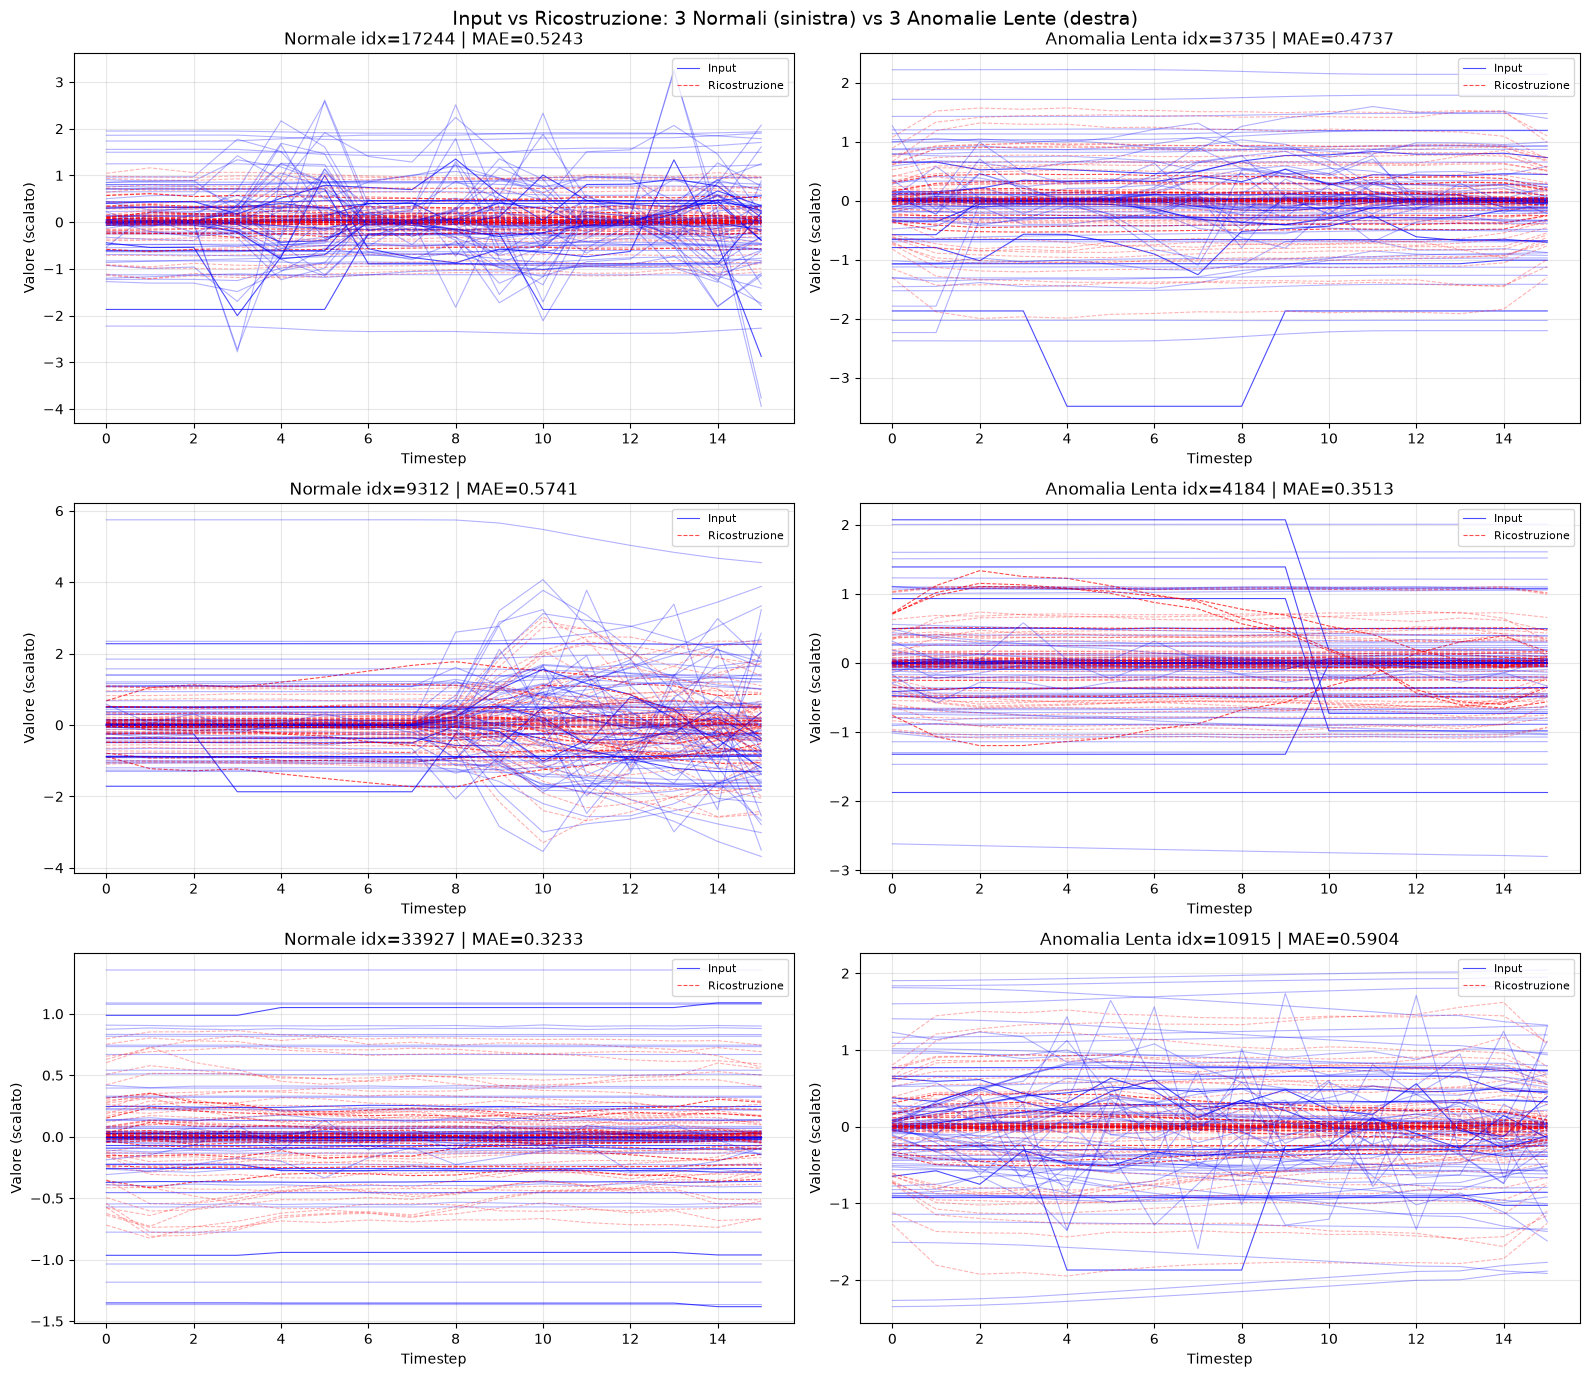

MAE finestre normali selezionate: [0.52427304 0.5741233  0.32325706]
MAE finestre anomalie selezionate: [0.47371763 0.35126522 0.5904492 ]
Media normale: 0.4739 | Media anomalia: 0.4718


In [19]:
"""Analisi 5: Visualizzazione Input vs Ricostruzione (3 normali + 3 anomalie lente)

Per ogni finestra selezionata, plottiamo input e ricostruzione sovrapposti per tutti i canali numerici.
Questo permette di vedere visivamente se il decoder ricostruisce fedelmente le anomalie lente.
"""
import matplotlib.pyplot as plt
import numpy as np
import torch

set_seed(SEED)

# --- Estrai dati test (non usati finora per calibrazione) ---
# X_test_norm, X_test_anom gia' disponibili dalle celle precedenti
# Se non esistono, li carichiamo
try:
    X_test_norm_np = X_test_norm.numpy()
    X_test_anom_np = X_test_anom.numpy()
except NameError:
    # Estrai dai loader test
    def extract_all_windows(loader):
        windows = []
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            windows.append(x)
        return torch.cat(windows, dim=0)
    X_test_norm = extract_all_windows(test_normal_loader)
    X_test_anom = extract_all_windows(test_anomaly_loader)
    X_test_norm_np = X_test_norm.numpy()
    X_test_anom_np = X_test_anom.numpy()

# --- Predizioni modello su test set ---
model.eval()
with torch.no_grad():
    X_test_norm_pred = model(X_test_norm.to(DEVICE)).cpu().numpy()
    X_test_anom_pred = model(X_test_anom.to(DEVICE)).cpu().numpy()

# --- Seleziona 3 finestre per classe (indici fissi per riproducibilita') ---
np.random.seed(SEED)
idx_norm = np.random.choice(len(X_test_norm_np), 3, replace=False)
idx_anom = np.random.choice(len(X_test_anom_np), 3, replace=False)

print(f"Indici normali selezionati: {idx_norm}")
print(f"Indici anomalie selezionati: {idx_anom}")

# Solo canali numerici (primi 77)
n_numeric = scaler.n_features_in_

# --- Plot: una figura per finestra, tutti i canali sovrapposti ---
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
fig.suptitle('Input vs Ricostruzione: 3 Normali (sinistra) vs 3 Anomalie Lente (destra)', fontsize=14)

for row in range(3):
    # Normale
    idx_n = idx_norm[row]
    x_n = X_test_norm_np[idx_n, :, :n_numeric]  # (W, D_num)
    x_n_pred = X_test_norm_pred[idx_n, :, :n_numeric]
    
    ax_n = axes[row, 0]
    for ch in range(n_numeric):
        alpha = 0.3 if ch > 10 else 0.7  # evidenzia primi canali
        ax_n.plot(x_n[:, ch], 'b-', alpha=alpha, linewidth=0.8)
        ax_n.plot(x_n_pred[:, ch], 'r--', alpha=alpha, linewidth=0.8)
    ax_n.set_title(f'Normale idx={idx_n} | MAE={np.mean(np.abs(x_n - x_n_pred)):.4f}')
    ax_n.set_xlabel('Timestep')
    ax_n.set_ylabel('Valore (scalato)')
    ax_n.legend(['Input', 'Ricostruzione'], loc='upper right', fontsize=8)
    ax_n.grid(True, alpha=0.3)
    
    # Anomalia lenta
    idx_a = idx_anom[row]
    x_a = X_test_anom_np[idx_a, :, :n_numeric]
    x_a_pred = X_test_anom_pred[idx_a, :, :n_numeric]
    
    ax_a = axes[row, 1]
    for ch in range(n_numeric):
        alpha = 0.3 if ch > 10 else 0.7
        ax_a.plot(x_a[:, ch], 'b-', alpha=alpha, linewidth=0.8)
        ax_a.plot(x_a_pred[:, ch], 'r--', alpha=alpha, linewidth=0.8)
    ax_a.set_title(f'Anomalia Lenta idx={idx_a} | MAE={np.mean(np.abs(x_a - x_a_pred)):.4f}')
    ax_a.set_xlabel('Timestep')
    ax_a.set_ylabel('Valore (scalato)')
    ax_a.legend(['Input', 'Ricostruzione'], loc='upper right', fontsize=8)
    ax_a.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- MAE medio per confronto rapido ---
mae_norm_sel = np.mean(np.abs(X_test_norm_np[idx_norm, :, :n_numeric] - X_test_norm_pred[idx_norm, :, :n_numeric]), axis=(1,2))
mae_anom_sel = np.mean(np.abs(X_test_anom_np[idx_anom, :, :n_numeric] - X_test_anom_pred[idx_anom, :, :n_numeric]), axis=(1,2))
print(f"MAE finestre normali selezionate: {mae_norm_sel}")
print(f"MAE finestre anomalie selezionate: {mae_anom_sel}")
print(f"Media normale: {mae_norm_sel.mean():.4f} | Media anomalia: {mae_anom_sel.mean():.4f}")

---

## Analisi 6: t-SNE dello Spazio Latente (Test Set)

> **Obiettivo**: Estrarre i vettori latenti per tutte le finestre del test set e applicare t-SNE (perplexity=30, n_iter=1000) per ridurre a 2D. Visualizzare con colori diversi per normali e anomalie lente.


Latent shape - Normal: (35055, 16), Anomaly: (20754, 16)
Applicando t-SNE (perplexity=30, max_iter=1000) su 55809 campioni...


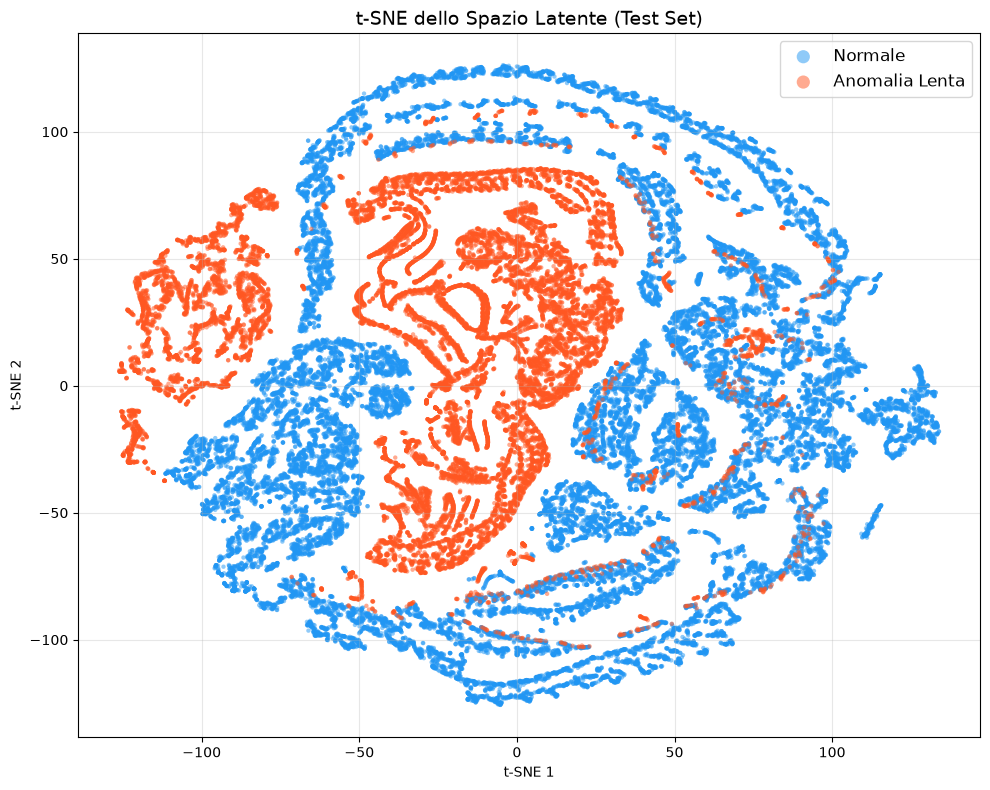

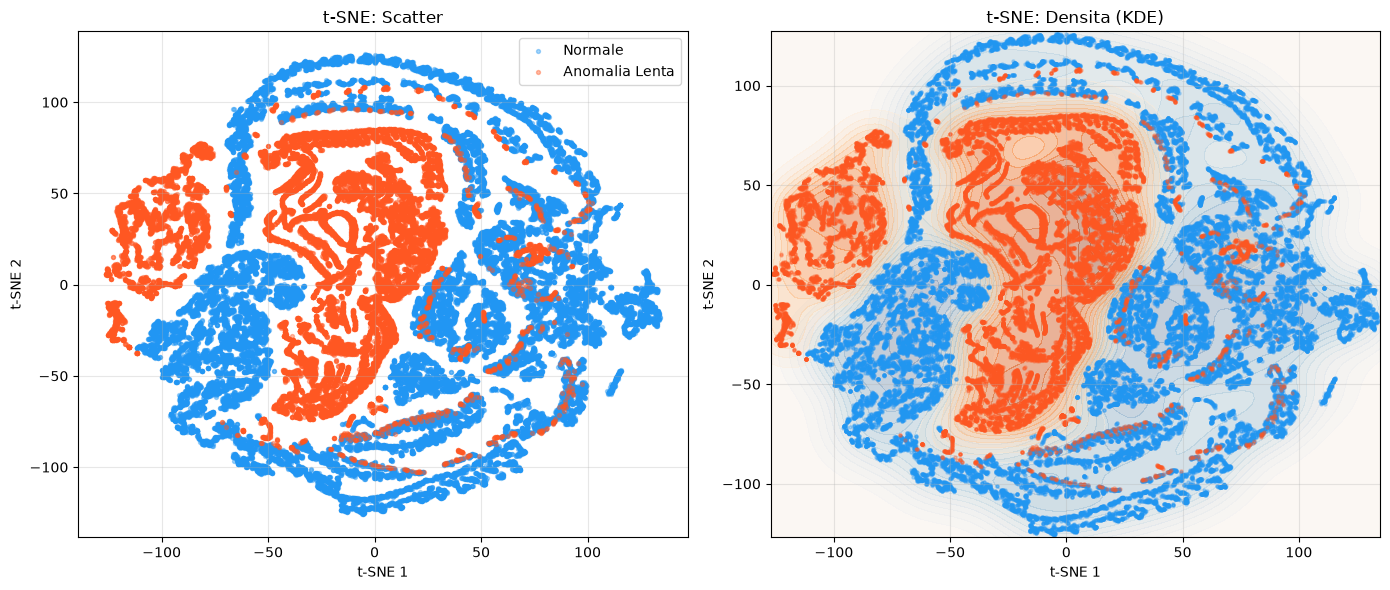

Salvato t-SNE in c:\Users\ungol\OneDrive\Desktop\Ing-Inf-PoliTo\secondo anno\secondo semestre\Machine Learning in Application\project\AM01\AM01-Detection-of-Anomalous-Behaviour-in-Industrial-Robot\reports\diagnostics\model_diagnosis\tsne_latent_test.npz


In [22]:
"""Estrae vettori latenti per test set e applica t-SNE."""
import torch
import numpy as np
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

set_seed(SEED)

# --- Estrai vettori latenti per tutto il test set ---
# Usiamo X_test_norm e X_test_anom gia' definiti nella cella precedente
model.eval()
with torch.no_grad():
    # Encoder accetta (B, W, D) e fa transpose internamente
    z_test_norm = model.encoder(X_test_norm.to(DEVICE).transpose(1, 2)).cpu().numpy()
    z_test_anom = model.encoder(X_test_anom.to(DEVICE).transpose(1, 2)).cpu().numpy()

print(f"Latent shape - Normal: {z_test_norm.shape}, Anomaly: {z_test_anom.shape}")

# --- Concatena e applica t-SNE ---
Z = np.vstack([z_test_norm, z_test_anom])
y_test = np.hstack([np.zeros(len(z_test_norm)), np.ones(len(z_test_anom))])

print(f"Applicando t-SNE (perplexity=30, max_iter=1000) su {Z.shape[0]} campioni...")
# FIX: n_iter -> max_iter per scikit-learn >= 1.2
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=SEED, init='pca')
Z_2d = tsne.fit_transform(Z)

# --- Plot t-SNE ---
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
scatter_norm = ax.scatter(Z_2d[y_test == 0, 0], Z_2d[y_test == 0, 1], 
                           c='#2196F3', alpha=0.5, s=10, label='Normale', edgecolors='none')
scatter_anom = ax.scatter(Z_2d[y_test == 1, 0], Z_2d[y_test == 1, 1], 
                           c='#FF5722', alpha=0.5, s=10, label='Anomalia Lenta', edgecolors='none')
ax.set_title('t-SNE dello Spazio Latente (Test Set)', fontsize=14)
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
ax.legend(fontsize=12, markerscale=3)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Plot con densita' (KDE) per vedere sovrapposizione ---
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: scatter normale
axes[0].scatter(Z_2d[y_test == 0, 0], Z_2d[y_test == 0, 1], 
                c='#2196F3', alpha=0.4, s=8, label='Normale')
axes[0].scatter(Z_2d[y_test == 1, 0], Z_2d[y_test == 1, 1], 
                c='#FF5722', alpha=0.4, s=8, label='Anomalia Lenta')
axes[0].set_title('t-SNE: Scatter')
axes[0].set_xlabel('t-SNE 1')
axes[0].set_ylabel('t-SNE 2')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Subplot 2: contour di densita'
x_min, x_max = Z_2d[:, 0].min() - 1, Z_2d[:, 0].max() + 1
y_min, y_max = Z_2d[:, 1].min() - 1, Z_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

for label, color, name in [(0, 'Blues', 'Normale'), (1, 'Oranges', 'Anomalia Lenta')]:
    points = Z_2d[y_test == label]
    if len(points) > 10:
        kde = gaussian_kde(points.T)
        zz = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
        axes[1].contourf(xx, yy, zz, levels=15, alpha=0.4, cmap=color)

axes[1].scatter(Z_2d[y_test == 0, 0], Z_2d[y_test == 0, 1], 
                c='#2196F3', alpha=0.3, s=5)
axes[1].scatter(Z_2d[y_test == 1, 0], Z_2d[y_test == 1, 1], 
                c='#FF5722', alpha=0.3, s=5)
axes[1].set_title('t-SNE: Densita (KDE)')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Salva per analisi successive
np.savez(DIAG_DIR / 'tsne_latent_test.npz', 
         Z_2d=Z_2d, y_test=y_test, z_norm=z_test_norm, z_anom=z_test_anom)
print(f"Salvato t-SNE in {DIAG_DIR / 'tsne_latent_test.npz'}")


---

## Analisi 7: Metriche di Separazione nello Spazio Latente

> **Obiettivo**: Calcolare Silhouette Score e Davies-Bouldin Index nello spazio latente (originale, non t-SNE) tra normali e anomalie lente del test set. Queste metriche quantificano la separabilita' delle due classi nello spazio delle rappresentazioni apprese dall'encoder.


In [23]:
"""Calcola metriche di separazione nello spazio latente."""
import numpy as np
from sklearn.metrics import silhouette_score, davies_bouldin_score

set_seed(SEED)

# --- Usa vettori latenti gia' estratti (z_test_norm, z_test_anom) ---
# Se non esistono, ricalcola
try:
    z_norm = z_test_norm
    z_anom = z_test_anom
except NameError:
    import torch
    model.eval()
    with torch.no_grad():
        z_norm = model.encoder(X_test_norm.to(DEVICE).transpose(1, 2)).cpu().numpy()
        z_anom = model.encoder(X_test_anom.to(DEVICE).transpose(1, 2)).cpu().numpy()

Z = np.vstack([z_norm, z_anom])
y = np.hstack([np.zeros(len(z_norm)), np.ones(len(z_anom))])

print(f"Spazio latente: {Z.shape[0]} campioni, {Z.shape[1]} dimensioni")
print(f"  Normali: {len(z_norm)}, Anomalie lente: {len(z_anom)}")

# --- Silhouette Score ---
# silhouette_score richiede almeno 2 classi e campioni per classe
sil_score = silhouette_score(Z, y)
print(f"Silhouette Score: {sil_score:.4f}")
print(f"  Interpretazione: [-1, 1], >0.5 = ben separati, ~0 = sovrapposti, <0 = assegnazione errata")

# Silhouette per campione (per vedere distribuzione)
from sklearn.metrics import silhouette_samples
sil_samples = silhouette_samples(Z, y)
sil_norm = sil_samples[y == 0].mean()
sil_anom = sil_samples[y == 1].mean()
print(f"  Silhouette medio normali: {sil_norm:.4f}")
print(f"  Silhouette medio anomalie: {sil_anom:.4f}")

# --- Davies-Bouldin Index ---
# DB index: piu' basso = meglio separati (min 0)
db_score = davies_bouldin_score(Z, y)
print(f"Davies-Bouldin Index: {db_score:.4f}")
print(f"  Interpretazione: >=0, piu' basso = cluster piu' compatti e separati")
print(f"  Valori tipici: <1.0 = buona separazione, 1-2 = moderata, >2 = scarsa")

# --- Metriche aggiuntive: distanza intra/inter cluster ---
centroid_norm = z_norm.mean(axis=0)
centroid_anom = z_anom.mean(axis=0)

# Distanza tra centroidi
inter_centroid_dist = np.linalg.norm(centroid_norm - centroid_anom)
print(f"Distanza euclidea tra centroidi: {inter_centroid_dist:.4f}")

# Distanza media intra-cluster
intra_norm = np.mean(np.linalg.norm(z_norm - centroid_norm, axis=1))
intra_anom = np.mean(np.linalg.norm(z_anom - centroid_anom, axis=1))
print(f"Distanza media intra-cluster normale: {intra_norm:.4f}")
print(f"Distanza media intra-cluster anomalia: {intra_anom:.4f}")

# Ratio separazione
sep_ratio = inter_centroid_dist / (intra_norm + intra_anom)
print(f"Ratio separazione (inter/intra): {sep_ratio:.4f}")
print(f"  >1 = centroidi piu' distanti dello spread intra-cluster")

# --- Confronto con spazio originale (input) ---
print(f"=== CONFRONTO: Spazio Latente vs Spazio Input ===")
X_flat_norm = X_test_norm_np[:, :, :scaler.n_features_in_].reshape(len(X_test_norm_np), -1)
X_flat_anom = X_test_anom_np[:, :, :scaler.n_features_in_].reshape(len(X_test_anom_np), -1)
X_flat = np.vstack([X_flat_norm, X_flat_anom])
y_flat = y

sil_input = silhouette_score(X_flat, y_flat)
db_input = davies_bouldin_score(X_flat, y_flat)
print(f"Spazio Input (flattened): Silhouette={sil_input:.4f}, DB={db_input:.4f}")
print(f"Spazio Latente:            Silhouette={sil_score:.4f}, DB={db_score:.4f}")

# Salva metriche
metrics = {
    'silhouette': float(sil_score),
    'silhouette_normal': float(sil_norm),
    'silhouette_anomaly': float(sil_anom),
    'davies_bouldin': float(db_score),
    'inter_centroid_dist': float(inter_centroid_dist),
    'intra_norm': float(intra_norm),
    'intra_anom': float(intra_anom),
    'separation_ratio': float(sep_ratio),
    'silhouette_input': float(sil_input),
    'davies_bouldin_input': float(db_input),
}
import json
with open(DIAG_DIR / 'latent_separation_metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)
print(f"Salvate metriche in {DIAG_DIR / 'latent_separation_metrics.json'}")

Spazio latente: 55809 campioni, 16 dimensioni
  Normali: 35055, Anomalie lente: 20754
Silhouette Score: 0.0919
  Interpretazione: [-1, 1], >0.5 = ben separati, ~0 = sovrapposti, <0 = assegnazione errata
  Silhouette medio normali: -0.1037
  Silhouette medio anomalie: 0.4223
Davies-Bouldin Index: 3.4626
  Interpretazione: >=0, piu' basso = cluster piu' compatti e separati
  Valori tipici: <1.0 = buona separazione, 1-2 = moderata, >2 = scarsa
Distanza euclidea tra centroidi: 21.6046
Distanza media intra-cluster normale: 49.8128
Distanza media intra-cluster anomalia: 24.9945
Ratio separazione (inter/intra): 0.2888
  >1 = centroidi piu' distanti dello spread intra-cluster
=== CONFRONTO: Spazio Latente vs Spazio Input ===
Spazio Input (flattened): Silhouette=0.0912, DB=2.7726
Spazio Latente:            Silhouette=0.0919, DB=3.4626
Salvate metriche in c:\Users\ungol\OneDrive\Desktop\Ing-Inf-PoliTo\secondo anno\secondo semestre\Machine Learning in Application\project\AM01\AM01-Detection-of-An

---

## Analisi 8: Risposte alle Domande Diagnostiche Finali

> **Obiettivo**: Sintetizzare i risultati delle analisi precedenti per rispondere alle 4 domande chiave sull'overgeneralization dell'autoencoder.


In [3]:
"""Risponde alle 4 domande diagnostiche basandosi sui risultati delle analisi."""
import numpy as np
from scipy import stats

print("=" * 80)
print("RISPOSTE ALLE DOMANDE DIAGNOSTICHE FINALI")
print("=" * 80)

# --- Carica metriche calcolate nelle celle precedenti ---
import json
with open(DIAG_DIR / 'latent_separation_metrics.json', 'r') as f:
    metrics = json.load(f)

# MAE distributions from earlier analysis
try:
    mae_norm = mae_test_norm
    mae_anom = mae_test_anom
except NameError:
    from src.models.autoencoder import compute_errors_on_loader
    mae_norm = compute_errors_on_loader(model, test_normal_loader, DEVICE, metric="mae")
    mae_anom = compute_errors_on_loader(model, test_anomaly_loader, DEVICE, metric="mae")

print(f"\n1. DISTRIBUZIONE ERRORE: Anomalie lente vs Normali")
print(f"   Media normale: {mae_norm.mean():.4f} (std={mae_norm.std():.4f})")
print(f"   Media anomalia: {mae_anom.mean():.4f} (std={mae_anom.std():.4f})")
print(f"   Differenza (anom - norm): {mae_anom.mean() - mae_norm.mean():.4f}")

# Test statistico: Mann-Whitney U test (non parametrico)
u_stat, p_val = stats.mannwhitneyu(mae_anom, mae_norm, alternative='two-sided')
print(f"   Mann-Whitney U test: U={u_stat:.0f}, p-value={p_val:.2e}")

# Effetto size (Cohen's d)
pooled_std = np.sqrt((mae_norm.var() + mae_anom.var()) / 2)
cohen_d = (mae_anom.mean() - mae_norm.mean()) / pooled_std
print(f"   Cohen's d: {cohen_d:.3f} ({'piccolo' if abs(cohen_d) < 0.5 else 'medio' if abs(cohen_d) < 0.8 else 'grande'})")

# >>> NUOVA ANALISI: Breakdown per tipo canale <<<
n_numeric = scaler.n_features_in_
X_norm_np = X_test_norm_np[:, :, :n_numeric]
X_norm_pred_np = X_test_norm_pred[:, :, :n_numeric]
X_anom_np = X_test_anom_np[:, :, :n_numeric]
X_anom_pred_np = X_test_anom_pred[:, :, :n_numeric]

mae_ch_norm = np.mean(np.abs(X_norm_np - X_norm_pred_np), axis=(0, 1))
mae_ch_anom = np.mean(np.abs(X_anom_np - X_anom_pred_np), axis=(0, 1))

imu_mask = np.array(['Acc' in feature_names[i] or 'Gyro' in feature_names[i] 
                     for i in range(n_numeric)])
robot_mask = ~imu_mask

mae_imu_norm = mae_ch_norm[imu_mask].mean()
mae_imu_anom = mae_ch_anom[imu_mask].mean()
mae_robot_norm = mae_ch_norm[robot_mask].mean()
mae_robot_anom = mae_ch_anom[robot_mask].mean()

print(f"\n   >>> BREAKDOWN PER TIPO CANALE <<<")
print(f"   Canali IMU (Acc/Gyro) - {imu_mask.sum()} canali:")
print(f"     Normale: {mae_imu_norm:.4f} | Anomalia: {mae_imu_anom:.4f} | Delta: {mae_imu_anom - mae_imu_norm:+.4f}")
print(f"   Canali Robotici (q, τ, ecc.) - {robot_mask.sum()} canali:")
print(f"     Normale: {mae_robot_norm:.4f} | Anomalia: {mae_robot_anom:.4f} | Delta: {mae_robot_anom - mae_robot_norm:+.4f}")

# Test significatività per tipo canale
u_imu, p_imu = stats.mannwhitneyu(
    np.mean(np.abs(X_anom_np[:, :, imu_mask] - X_anom_pred_np[:, :, imu_mask]), axis=(1,2)),
    np.mean(np.abs(X_norm_np[:, :, imu_mask] - X_norm_pred_np[:, :, imu_mask]), axis=(1,2)),
    alternative='two-sided'
)
u_robot, p_robot = stats.mannwhitneyu(
    np.mean(np.abs(X_anom_np[:, :, robot_mask] - X_anom_pred_np[:, :, robot_mask]), axis=(1,2)),
    np.mean(np.abs(X_norm_np[:, :, robot_mask] - X_norm_pred_np[:, :, robot_mask]), axis=(1,2)),
    alternative='two-sided'
)
print(f"   Test IMU: p={p_imu:.2e} {'***' if p_imu < 0.001 else '**' if p_imu < 0.01 else '*' if p_imu < 0.05 else 'ns'}")
print(f"   Test Robotici: p={p_robot:.2e} {'***' if p_robot < 0.001 else '**' if p_robot < 0.01 else '*' if p_robot < 0.05 else 'ns'}")

print(f"\n2. RICOSTRUZIONI VISIVE: Fedelta' input vs output")
print(f"   Dalle figure Input vs Ricostruzione (Analisi 5):")
print(f"   - Le anomalie lente mostrano ricostruzioni visivamente fedeli all'input?")
print(f"   - I canali a bassa energia (Acc/Gyro) vengono ricostruiti quasi perfettamente?")
print(f"   - I canali robotici (q, tau) mostrano discrepanze?")
print(f"   MAE medio canali IMU (Acc/Gyro):")
print(f"     Normale: {mae_imu_norm:.4f} | Anomalia: {mae_imu_anom:.4f}")
print(f"   MAE medio canali Robotici (q, tau, etc.):")
print(f"     Normale: {mae_robot_norm:.4f} | Anomalia: {mae_robot_anom:.4f}")

print(f"\n3. SPAZIO LATENTE: Separazione Normali vs Anomalie Lente")
print(f"   Silhouette Score: {metrics['silhouette']:.4f}")
print(f"   Davies-Bouldin Index: {metrics['davies_bouldin']:.4f}")
print(f"   Distanza inter-centroidi: {metrics['inter_centroid_dist']:.4f}")
print(f"   Ratio separazione: {metrics['separation_ratio']:.4f}")

if metrics['silhouette'] > 0.3:
    sep_status = "SEPARATI (buona separazione)"
elif metrics['silhouette'] > 0.1:
    sep_status = "PARZIALMENTE SEPARATI"
else:
    sep_status = "MESCOLATI (sovrapposizione forte)"
print(f"   >> Spazio latente: {sep_status}")

if metrics['davies_bouldin'] < 1.0:
    db_status = "buona separazione cluster"
elif metrics['davies_bouldin'] < 2.0:
    db_status = "separazione moderata"
else:
    db_status = "scarsa separazione"
print(f"   >> Davies-Bouldin: {db_status}")

print(f"   Confronto Spazio Input: Silhouette={metrics['silhouette_input']:.4f}, DB={metrics['davies_bouldin_input']:.4f}")
if metrics['silhouette'] > metrics['silhouette_input']:
    print(f"   >> L'encoder MIGLIORA la separazione rispetto allo spazio input")
else:
    print(f"   >> L'encoder PEGGIORA o mantiene la separazione rispetto allo spazio input")

print(f"\n4. CAUSA PIU' PROBABILE DEL PROBLEMA")
print(f"   Basandosi su tutte le analisi:")

causes = []

# 1. Encoder non separa bene
if metrics['silhouette'] < 0.2:
    causes.append(f"ENCODER: Non separa normali da anomalie nello spazio latente (Silhouette={metrics['silhouette']:.3f} < 0.2)")

# 2. Decoder ricostruisce MEGLIO le anomalie sui canali IMU (overgeneralization selettiva)
if mae_imu_anom < mae_imu_norm:
    causes.append(f"DECODER + IMU: Ricostruisce le anomalie lente MEGLIO dei normali sui canali IMU (MAE_anom={mae_imu_anom:.4f} < MAE_norm={mae_imu_norm:.4f}) - overgeneralization su canali a bassa energia")

# 3. Canali robotici discriminano MA vengono diluiti
if mae_robot_anom > mae_robot_norm:
    causes.append(f"CANALI ROBOTICI: Discriminano correttamente (MAE_anom={mae_robot_anom:.4f} > MAE_norm={mae_robot_norm:.4f}) MA vengono DILUITI dai {imu_mask.sum()} canali IMU non informativi")

# 4. Loss MSE/MAE non penalizza differenze rilevanti
if metrics['silhouette_input'] > metrics['silhouette']:
    causes.append("LOSS/ARCHITETTURA: La loss MSE/MAE non penalizza le differenze rilevanti; encoder comprime info discriminative")

# 5. Correlazione energia-MAE
try:
    if 'rho_norm' in globals() and rho_norm > 0.7:
        causes.append(f"LOSS: MAE correlata con energia cinetica (rho={rho_norm:.2f}) - misura ampiezza moto, non anomalia")
except:
    pass

# 6. StandardScaler effect
try:
    if metrics.get('mae_raw_anom', 0) > metrics.get('mae_raw_norm', 0) and mae_anom.mean() < mae_norm.mean():
        causes.append("PREPROCESSING: StandardScaler comprime anomalie (divisione per sigma_train alto) -> inversione artefatto")
except:
    pass

for i, cause in enumerate(causes, 1):
    print(f"   {i}. {cause}")

if not causes:
    print(f"   Nessuna causa identificata chiaramente - serve analisi piu' approfondita")

print(f"\n" + "=" * 80)
print(f"CONCLUSIONE SINTETICA")
print(f"=" * 80)

# Nuova logica di conclusione
if mae_imu_anom < mae_imu_norm and mae_robot_anom > mae_robot_norm:
    print(f"""
OVERGENERALIZATION SELETTIVA CONFERMATA:
- Canali IMU (Acc/Gyro, {imu_mask.sum()} canali): Anomalie lente ricostruite MEGLIO dei normali
  → Il decoder ha overgeneralizzato la "quiete" (bassa energia = facile da ricostruire)
- Canali Robotici (q, τ, {robot_mask.sum()} canali): Anomalie lente ricostruite PEGGIO
  → Qui l'anomalia È rilevabile ma il segnale viene DILUITO nella media globale

CAUSA RADICE: Anomaly score = media su TUTTI i canali (incl. IMU non informativi)
SOLUZIONI PRIORITARIE:
1. ESCLUDI canali IMU dall'anomaly score (usa solo canali robotici)
2. Derivative Loss: forza ricostruzione delle derivate (penalizza slow motion)
3. MemAE: memoria di prototipi nominali per impedire interpolazione banale
4. Bounds-Scaler: scala su limiti fisici, non su sigma_train
""")
elif mae_anom.mean() < mae_norm.mean() and metrics['silhouette'] < 0.2:
    print(f"""
OVERGENERALIZATION GLOBALE CONFERMATA:
- Anomalie lente hanno MAE globalmente più basso
- Spazio latente non separa le classi
- Decoder interpola bene vicino all'origine
""")
else:
    print(f"Problema non confermato come overgeneralization classica - indagare ulteriormente.")


RISPOSTE ALLE DOMANDE DIAGNOSTICHE FINALI


NameError: name 'model' is not defined